# AMN-Style iML1515 FluxTransformer Evaluation

Evaluate a pretrained *E. coli* iML1515 FluxTransformer as a frozen metabolic reservoir for Faure-inspired AMN-style experiments.

Main workflow: load and sanity-check the checkpoint/test data, inspect simulated flux diagnostics, predict experimental growth rate (`GR_AVG`) from medium composition with a small prior dense network, compare against TabPFN baselines, and visualize selected pathway-token embeddings with t-SNE.

In [1]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)
hf_token = os.getenv("HFTOKEN")

In [2]:
from datetime import date

import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
from IPython.display import display, Image

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import seaborn as sns
from matplotlib.animation import FuncAnimation, PillowWriter
from openTSNE import TSNEEmbedding, affinity, initialization

from train_flux_transformer import load_data, set_seed
from sklearn.model_selection import train_test_split

%matplotlib inline
pd.set_option('display.max_rows', None)

def format_r2_with_std(r2_value, r2_std):
    std_precision = 3 if abs(float(r2_std)) < 0.005 else 2
    return f"$R^2$ = {r2_value:.2f} $\\pm$ {r2_std:.{std_precision}f}"


In [3]:
class AttentionBlock(nn.Module):
    """Custom multi-head attention block for metabolic modeling"""
    def __init__(self, d_model=128, n_heads=8, dropout=0.05):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"

        self.d_model = d_model
        self.n_heads = n_heads
        self.layer_norm = nn.LayerNorm(d_model)

        self.mha = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True
        )

        self.head_scores = nn.Parameter(torch.zeros(n_heads))

    def forward(self, x, c):
        # x: (batch, seq_len, d_model)
        # c: (batch, seq_len, 1)
        x_norm = self.layer_norm(x) # pre-norm
        attn_out, attn_weights = self.mha(x_norm, x_norm, x_norm, need_weights=True, average_attn_weights=False)

        x_out = attn_out + x

        # Per-head diffusion of c:
        c_heads = torch.matmul(attn_weights, c.unsqueeze(1))
        alpha = F.softmax(self.head_scores, dim=0).view(1, self.n_heads, 1, 1)  # (1,H,1,1)
        c_att = (c_heads * alpha).sum(dim=1)  # (B, S, 1)

        c_out = c_att + c

        return x_out, c_out

In [4]:
class FeedForwardBlock(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.05):
        super().__init__()

        self.d_model = d_model + 1
        self.d_ff = d_ff

        self.layer_norm = nn.LayerNorm(self.d_model)
        self.linear1 = nn.Linear(self.d_model, self.d_ff)
        self.activation = nn.GELU()
        self.linear2 = nn.Linear(self.d_ff, self.d_model)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, x, c):
        y = torch.cat((x, c), dim=2)
        
        norm_y = self.layer_norm(y)
        hidden = self.linear1(norm_y)
        hidden = self.activation(hidden)
        hidden = self.dropout(hidden)
        output = self.linear2(hidden)

        return output + y

In [5]:
class FluxTransformerLayer(nn.Module):
    """Single transformer block without embedding layer"""
    def __init__(self, d_model=128, n_heads=8, d_ff=1024, dropout=0.05):
        super().__init__()
        self.d_model = d_model
        
        self.attention_block = AttentionBlock(d_model, n_heads, dropout)
        self.feedforward_block = FeedForwardBlock(d_model, d_ff, dropout)
        
        self.apply(self._init_weights)
    
    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
    
    def forward(self, x, c):
        attn_x, attn_c = self.attention_block(x, c)
        ff_output = self.feedforward_block(attn_x, attn_c)
        
        # Split the concatenated output
        updated_x = ff_output[:, :, :-1]
        updated_c = ff_output[:, :, -1:]
        
        return updated_x, updated_c
        
class FluxTransformer(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        input_token_indices,          # list[int] or 1D tensor[int64]
        d_model=128,
        n_heads=8,
        n_layers=3,
        d_ff=1024,
        dropout=0.05,
    ):
        super().__init__()
        if vocab_size is None:
            raise ValueError("vocab_size must be provided explicitly.")
        self.vocab_size = int(vocab_size)
        self.d_model = d_model

        idx = torch.as_tensor(input_token_indices, dtype=torch.long)
        if idx.ndim != 1:
            raise ValueError("input_token_indices must be 1D.")
        if (idx < 0).any() or (idx >= self.vocab_size).any():
            raise ValueError("input_token_indices contains out-of-range indices.")
        # Register as buffer so it moves with .to(device)
        self.register_buffer("input_token_indices", idx, persistent=True)

        self.input_embedding = nn.Embedding(self.vocab_size, d_model)

        self.layers = nn.ModuleList([
            FluxTransformerLayer(d_model=d_model, n_heads=n_heads, d_ff=d_ff, dropout=dropout)
            for _ in range(n_layers)
        ])

    def forward(self, c, output_subset=None, return_embedding=False):
        """
        c: (batch, vocab_size, 1)
        output_subset: 1D tensor of token indices to train on (typically excludes injected tokens)
        """
        batch_size = c.size(0)

        always = self.input_token_indices  # (n_injected,)

        if output_subset is None:
            selected_indices = torch.arange(self.vocab_size, device=c.device)
        else:
            output_subset = output_subset.to(c.device).long()
            selected_indices = torch.unique(torch.cat([always, output_subset]), sorted=True)

        y = selected_indices.unsqueeze(0).expand(batch_size, -1)      # (B, S)
        x = self.input_embedding(y)                                    # (B, S, d_model)

        c_subset = c[:, selected_indices, :]                           # (B, S, 1)
        c_subset_all_layers = torch.zeros(batch_size, c_subset.size(1), len(self.layers), device=c.device)

        for e, layer in enumerate(self.layers):
            x, c_subset = layer(x, c_subset)
            c_subset_all_layers[:, :, e] = c_subset.squeeze(-1)

        if return_embedding:
            return x, selected_indices

        return c_subset_all_layers, selected_indices

In [6]:
def load_pretrained_model(checkpoint_path, device='cuda' if torch.cuda.is_available() else 'cpu'):
    """
    Load a pretrained model from a checkpoint file
    
    Args:
        checkpoint_path: Path to the checkpoint file (*_checkpoint.pth)
        device: Device to load the model onto
        
    Returns:
        model: Loaded FluxTransformer model
        config: Model configuration dictionary
        data_info: Data information dictionary
    """
    # Load checkpoint
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    
    # Extract configuration
    config = checkpoint['config']
    train_losses = checkpoint['train_losses']
    test_losses = checkpoint['test_losses']

    # Initialize model with saved configuration
    model = FluxTransformer(
        vocab_size=config['vocab_size'],
        input_token_indices=config['input_token_indices'],
        d_model=config['d_model'],
        n_heads=config['n_heads'],
        n_layers=config['n_layers'],
        d_ff=config['d_ff'],
        dropout=config['dropout']
    ).to(device)
    
    # Load model weights
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()  # Set to evaluation mode
    
    print(f"Loaded model from {checkpoint_path}")
    print(f"Configuration: d_model={config['d_model']}, "
          f"n_heads={config['n_heads']}, n_layers={config['n_layers']}, d_ff={config['d_ff']}")
    
    return model, config, train_losses, test_losses, checkpoint['data_info']

### Plotting Functions

In [7]:
def plot_loss_curves(train_losses, test_losses, d_model, n_heads, n_layers, d_ff, save_path=None, log_scale=True):
    plt.figure(figsize=(14, 10))
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.plot(train_losses, label="Training Loss")
    plt.plot(test_losses, label="Test Loss")
    if log_scale:
        plt.yscale('log')
    plt.xlabel("Epoch", fontsize=18)
    plt.ylabel("Loss", fontsize=18)
    plt.title(f"Loss Curves (d={d_model}, h={n_heads}, l={n_layers}, ff={d_ff})", fontsize=20)
    plt.grid(True)
    plt.legend(fontsize=16)
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path)
        plt.show()
        print(f"\nTraining curve saved to {save_path}")
    else:
        plt.show()

In [8]:
def plot_diagnostics_2x2(y_true, y_pred, label, save_path=None):
    """Creates a 2x2 matrix of plots: true vs predicted, residuals, error distribution, and histogram of samples."""
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    residuals = y_true - y_pred
    display_label = str(label)
    if display_label.endswith('_flux'):
        display_label = display_label[:-5]
    if display_label.upper().startswith('BIOMASS'):
        display_label = 'AMN iML1515 Biomass'

    title_fs = 15
    label_fs = 13
    tick_fs = 11

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    # True vs Predicted
    axs[0, 0].scatter(y_true, y_pred, alpha=0.2, s=5, color='royalblue')
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    axs[0, 0].plot([lo, hi], [lo, hi], 'k--', lw=2)
    axs[0, 0].set_title(f'True vs Predicted: {display_label}', fontsize=title_fs)
    axs[0, 0].set_xlabel('True value', fontsize=label_fs)
    axs[0, 0].set_ylabel('Predicted', fontsize=label_fs)
    axs[0, 0].grid(True)

    # Residuals plot
    axs[0, 1].scatter(y_true, residuals, alpha=0.15, color='darkorange')
    axs[0, 1].axhline(y=0, color='r', linestyle='-')
    axs[0, 1].set_title(f'Residuals: {display_label}', fontsize=title_fs)
    axs[0, 1].set_xlabel('True value', fontsize=label_fs)
    axs[0, 1].set_ylabel('Residuals', fontsize=label_fs)
    if str(label).upper().startswith('BIOMASS'):
        axs[0, 1].set_ylim(-0.05, 0.05)
    else:
        res_abs_max = float(np.nanmax(np.abs(residuals))) if residuals.size else 1.0
        if (not np.isfinite(res_abs_max)) or (res_abs_max == 0.0):
            res_abs_max = 1.0
        axs[0, 1].set_ylim(-res_abs_max, res_abs_max)
    axs[0, 1].grid(True)

    # Error distribution
    sns.histplot(residuals, kde=True, ax=axs[1, 0], legend=False, color='indianred')
    axs[1, 0].set_title(f'Prediction Error Distribution: {display_label}', fontsize=title_fs)
    axs[1, 0].set_xlabel('Prediction Error', fontsize=label_fs)
    axs[1, 0].set_ylabel('Frequency', fontsize=label_fs)
    axs[1, 0].grid(True)

    # Histogram of actual values
    sns.histplot(y_true, kde=True, bins=100, ax=axs[1, 1], legend=False, color='mediumseagreen')
    axs[1, 1].set_title(f'True Value Distribution: {display_label}', fontsize=title_fs)
    axs[1, 1].set_xlabel('True Value', fontsize=label_fs)
    axs[1, 1].set_ylabel('Frequency', fontsize=label_fs)
    axs[1, 1].grid(True)

    for ax in axs.ravel():
        ax.tick_params(labelsize=tick_fs)

    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        plt.show()
        plt.close(fig)
    else:
        plt.show()
        plt.close(fig)

In [9]:
def plot_flux(
    model,
    X_test,
    y_test,
    outputs,
    flux_name: str,
    save_path=None,
    batch_size: int = 1,
    device: str | torch.device | None = None,
):
    """
    Plot diagnostics for a token name in `outputs`.

    Assumptions:
      - outputs defines token order, len(outputs) == model.vocab_size
      - X_test is (N, vocab_size) and contains medium constraints only at injected token indices
      - y_test is (N, vocab_size) and contains realized fluxes for all tokens
      - model forward returns (preds_all_layers, selected_indices)
        where preds_all_layers is (B, S, n_layers) and selected_indices are token indices
    """
    if device is None:
        device = "cuda" if torch.cuda.is_available() else "cpu"
    device = torch.device(device)

    model = model.to(device).eval()

    # Basic sanity checks
    if len(outputs) != getattr(model, "vocab_size", None):
        raise ValueError(f"len(outputs)={len(outputs)} does not match model.vocab_size={model.vocab_size}")

    if X_test.ndim != 2 or y_test.ndim != 2:
        raise ValueError(f"Expected X_test and y_test as 2D tensors (N, vocab_size). Got {X_test.shape=}, {y_test.shape=}")

    if X_test.shape[1] != model.vocab_size or y_test.shape[1] != model.vocab_size:
        raise ValueError(
            f"Feature dim mismatch. Expected vocab_size={model.vocab_size}. "
            f"Got X_test.shape[1]={X_test.shape[1]}, y_test.shape[1]={y_test.shape[1]}"
        )

    if flux_name not in outputs:
        raise ValueError(f"Flux '{flux_name}' not in outputs (len={len(outputs)}).")

    token_idx = outputs.index(flux_name)
    pred_vals = []
    true_vals = []
    pos = None

    with torch.inference_mode():
        for i in range(0, X_test.shape[0], batch_size):
            xb = X_test[i:i + batch_size].to(device)          # [B, vocab_size]
            yb_true = y_test[i:i + batch_size]                # [B, vocab_size]
            c = xb.unsqueeze(-1)                              # [B, vocab_size, 1]

            preds_all_layers, selected_indices = model(c, output_subset=None)

            # Map token_idx -> its position inside selected_indices (once is enough)
            if pos is None:
                selected_indices_np = selected_indices.detach().cpu().numpy()
                if selected_indices_np.ndim > 1:
                    selected_indices_np = selected_indices_np[0]
                hit = np.where(selected_indices_np == token_idx)[0]
                if hit.size == 0:
                    raise RuntimeError(
                        f"Token index {token_idx} for '{flux_name}' was not produced by the model forward pass. "
                        "This should not happen when output_subset=None."
                    )
                pos = int(hit[0])

            yb_pred_flux = preds_all_layers[:, pos, -1].detach().cpu().numpy()
            yb_true_flux = yb_true[:, token_idx].detach().cpu().numpy()

            pred_vals.append(yb_pred_flux)
            true_vals.append(yb_true_flux)

            del xb, yb_true, c, preds_all_layers, selected_indices

            if device.type == "cuda":
                torch.cuda.empty_cache()

    y_pred = np.concatenate(pred_vals, axis=0)
    y_true = np.concatenate(true_vals, axis=0)

    # Is this an injected (medium constraint) token slot?
    injected = False
    if hasattr(model, "input_token_indices") and model.input_token_indices is not None:
        injected = bool((model.input_token_indices.detach().cpu() == token_idx).any().item())

    print(f"{flux_name} token index: {token_idx}")
    print(f"injected medium slot: {injected}")
    print("y_true range:", float(y_true.min()), "to", float(y_true.max()))
    print("y_pred range:", float(y_pred.min()), "to", float(y_pred.max()))

    # Per-flux metrics for the currently plotted token
    try:
        r2 = r2_score(y_true, y_pred)
    except Exception:
        r2 = float("nan")
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    print(f"R2: {r2:.4f}")
    print(f"MAE: {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")

    plot_diagnostics_2x2(
        y_true=y_true,
        y_pred=y_pred,
        label=flux_name,
        save_path=save_path
    )

### Load model

In [10]:
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [11]:
#model_name = "iML1515_500k_d256_h8_l3_ff1024"
model_name = "A_1M_d256_h8_l4_ff1024"
checkpoint_path = f"./models/{model_name}/{model_name}_checkpoint.pth"

 # Load the model
model, config, train_losses, test_losses, data_info = load_pretrained_model(checkpoint_path, device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal number of parameters: {total_params:,}")

# Print data information
print("\nData information:")
print(f"Dataset: {data_info['dataset']}")
print(f"Training samples: {data_info['n_train']}")
print(f"Test samples: {data_info['n_test']}")

Loaded model from ./models/A_1M_d256_h8_l4_ff1024/A_1M_d256_h8_l4_ff1024_checkpoint.pth
Configuration: d_model=256, n_heads=8, n_layers=4, d_ff=1024

Total number of parameters: 3,861,548

Data information:
Dataset: ./data/iML1515_A_training_data_1000000_samples.csv
Training samples: 800000
Test samples: 200000


### Load data

In [12]:
# Load data using the same function as during training
#set_seed()

DATA_PATH = f"./data/iML1515_A_test_data_50000_samples.csv"
# DATA_PATH = data_info["dataset"]  # training file; use only for debugging, not reported test metrics
N_EVAL_SAMPLES = 50_000

X, y, inputs, outputs, input_token_indices, out_indices = load_data(DATA_PATH)
if X.shape[0] > N_EVAL_SAMPLES:
    rng = np.random.default_rng(10)
    eval_idx = rng.choice(X.shape[0], size=N_EVAL_SAMPLES, replace=False)
    X = X[eval_idx]
    y = y[eval_idx]
    print(f"Using {N_EVAL_SAMPLES:,} sampled rows from {DATA_PATH} for diagnostics.")

checkpoint_inputs = list(data_info.get("input_cols", []))
if not checkpoint_inputs:
    raise KeyError("Checkpoint data_info is missing 'input_cols'; cannot verify nutrient input set.")

loaded_input_set = set(inputs)
checkpoint_input_set = set(checkpoint_inputs)
missing_from_loaded = sorted(checkpoint_input_set - loaded_input_set)
extra_in_loaded = sorted(loaded_input_set - checkpoint_input_set)
assert loaded_input_set == checkpoint_input_set, (
    "Loaded CSV input set does not match checkpoint data_info['input_cols'].\n"
    f"Missing from loaded CSV: {missing_from_loaded}\n"
    f"Extra in loaded CSV: {extra_in_loaded}"
)
if list(inputs) != checkpoint_inputs:
    print("Warning: loaded CSV input order differs from checkpoint input_cols; continuing because inputs are mapped by token name.")

# Preserve the former prepare_tensors split and float32 conversion.
X_train, X_test, y_train, y_test = (
    torch.as_tensor(array, dtype=torch.float32, device=device)
    for array in train_test_split(X, y, test_size=0.2, random_state=42)
)

model.eval()


Loaded data with 50000 samples from ./data/iML1515_A_test_data_50000_samples.csv
Extracted input columns count:  38
Extracted output columns count: 2712
Medium constraints are injected into these token indices (in outputs order):
[40, 45, 86, 92, 104, 164, 304, 621, 700, 859, 913, 934, 970, 1424, 1478, 1485, 1500, 1534, 1535, 1836, 1981, 2243, 2320, 99, 108, 98, 1490, 217, 114, 1439, 288, 303, 206, 209, 106, 347, 112, 111]


FluxTransformer(
  (input_embedding): Embedding(2712, 256)
  (layers): ModuleList(
    (0-3): 4 x FluxTransformerLayer(
      (attention_block): AttentionBlock(
        (layer_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (mha): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
      )
      (feedforward_block): FeedForwardBlock(
        (layer_norm): LayerNorm((257,), eps=1e-05, elementwise_affine=True)
        (linear1): Linear(in_features=257, out_features=1024, bias=True)
        (activation): GELU(approximate='none')
        (linear2): Linear(in_features=1024, out_features=257, bias=True)
        (dropout): Dropout(p=0.02, inplace=False)
      )
    )
  )
)

In [13]:
glycolysis_reactions = [
    "GLCptspp", "GLCt2pp", "HEX1", "PGI", "PFK", "FBA", "TPI",
    "GAPD", "PGK", "PGM", "ENO", "PYK", "PPS", "FBP",
]

ppp_reactions = [
    "G6PDH2r", "PGL", "GND", "RPI", "RPE", "TKT1", "TALA", "TKT2",
]

tca_reactions = [
    "CS", "ACONTa", "ACONTb", "ICDHyr", "AKGDH", "SUCOAS", "SUCDi", "FUM", "MDH",
]

anaplerotic_reactions = [
    "PPC", "PPCK", "ME1", "ME2", "ICL", "MALS",
]

fermentation_reactions = [
    "PFL", "LDH_D", "ACALD", "ALCD2x", "PTAr", "ACKr", "POX",
]

oxphos_reactions = [
    "NADH16pp", "NADH17pp", "NADH18pp", "CYTBO3_4pp", "CYTBDpp", "CYTBD2pp", "ATPS4rpp",
]

nitrogen_reactions = [
    "GLNS", "GLUDy", "GLUN", "GLUSy", "ASPTA", "ALATA_L",
]

pathway_reaction_lists = {
    "glycolysis_reactions": glycolysis_reactions,
    "ppp_reactions": ppp_reactions,
    "tca_reactions": tca_reactions,
    "anaplerotic_reactions": anaplerotic_reactions,
    "fermentation_reactions": fermentation_reactions,
    "oxphos_reactions": oxphos_reactions,
    "nitrogen_reactions": nitrogen_reactions,
}

def _reaction_token_name(reaction_id, token_names):
    reaction_id = str(reaction_id)
    base_id = reaction_id[:-5] if reaction_id.endswith("_flux") else reaction_id
    candidates = (reaction_id, f"{base_id}_flux", base_id)
    token_set = set(token_names)
    for candidate in candidates:
        if candidate in token_set:
            return candidate
    return None

missing_by_pathway = {
    name: [rxn_id for rxn_id in rxn_ids if _reaction_token_name(rxn_id, outputs) is None]
    for name, rxn_ids in pathway_reaction_lists.items()
}
missing_by_pathway = {name: missing for name, missing in missing_by_pathway.items() if missing}
if missing_by_pathway:
    raise ValueError(f"Missing pathway reaction IDs from checkpoint outputs: {missing_by_pathway}")

for name, rxn_ids in pathway_reaction_lists.items():
    print(f"{name} = {rxn_ids!r}")


glycolysis_reactions = ['GLCptspp', 'GLCt2pp', 'HEX1', 'PGI', 'PFK', 'FBA', 'TPI', 'GAPD', 'PGK', 'PGM', 'ENO', 'PYK', 'PPS', 'FBP']
ppp_reactions = ['G6PDH2r', 'PGL', 'GND', 'RPI', 'RPE', 'TKT1', 'TALA', 'TKT2']
tca_reactions = ['CS', 'ACONTa', 'ACONTb', 'ICDHyr', 'AKGDH', 'SUCOAS', 'SUCDi', 'FUM', 'MDH']
anaplerotic_reactions = ['PPC', 'PPCK', 'ME1', 'ME2', 'ICL', 'MALS']
fermentation_reactions = ['PFL', 'LDH_D', 'ACALD', 'ALCD2x', 'PTAr', 'ACKr', 'POX']
oxphos_reactions = ['NADH16pp', 'NADH17pp', 'NADH18pp', 'CYTBO3_4pp', 'CYTBDpp', 'CYTBD2pp', 'ATPS4rpp']
nitrogen_reactions = ['GLNS', 'GLUDy', 'GLUN', 'GLUSy', 'ASPTA', 'ALATA_L']


In [14]:
def plot_reaction_subset_tsne(
    model,
    token_names,
    X_context,
    reaction_subset,
    *,
    subset_name=None,
    n_samples=8000,
    perplexity=40.0,
    batch_size=128,
    random_state=10,
    annotate=True,
    annotate_fontsize=15,
    save_path=None,
    print_colors=True,
    sample_color_mode="reaction",  # "reaction", "gray", "rainbow", "viridis", "plasma", or "coolwarm"
    show_pre_embeddings=False,
    return_data=False,
):
    """
    Plot post-layer FluxTransformer token embeddings for a selected reaction subset.

    reaction_subset can be either:
      - a key from pathway_reaction_lists, such as "glycolysis_reactions"
      - a list of reaction IDs, such as glycolysis_reactions
      - a list of flux token names ending in "_flux"

    Each reaction in the subset receives its own color before embeddings are collected.
    With sample_color_mode="gray", all subset-reaction points are plotted in gray.
    With sample_color_mode="rainbow" or another colormap, points are colored by
    nutrient-context similarity while reaction colors are kept only for centers.
    If show_pre_embeddings=True, initial token embeddings are included in the
    same t-SNE fit and plotted as black dots.
    """
    device = next(model.parameters()).device
    model.eval()

    V = int(model.vocab_size)
    if len(token_names) != V:
        raise ValueError(f"len(token_names)={len(token_names)} but model.vocab_size={V}.")

    if isinstance(reaction_subset, str):
        if reaction_subset in pathway_reaction_lists:
            reaction_ids = list(pathway_reaction_lists[reaction_subset])
            subset_label = subset_name or reaction_subset
        else:
            reaction_ids = [reaction_subset]
            subset_label = subset_name or reaction_subset
    else:
        reaction_ids = list(reaction_subset)
        subset_label = subset_name or "reaction subset"

    reaction_ids = list(dict.fromkeys(str(r) for r in reaction_ids))
    if not reaction_ids:
        raise ValueError("reaction_subset is empty.")

    token_lookup = {name: idx for idx, name in enumerate(token_names)}
    selected_token_names = []
    display_reaction_ids = []
    missing = []
    for reaction_id in reaction_ids:
        base_id = reaction_id[:-5] if reaction_id.endswith("_flux") else reaction_id
        candidates = (reaction_id, f"{base_id}_flux", base_id)
        token_name = next((candidate for candidate in candidates if candidate in token_lookup), None)
        if token_name is None:
            missing.append(reaction_id)
            continue
        selected_token_names.append(token_name)
        display_reaction_ids.append(token_name[:-5] if token_name.endswith("_flux") else token_name)

    if missing:
        raise ValueError(f"These reactions are not present in token_names: {missing}")

    token_indices = [token_lookup[name] for name in selected_token_names]
    n_tok = len(token_indices)
    colors = plt.cm.nipy_spectral(np.linspace(0.05, 0.95, n_tok))
    from matplotlib.colors import to_hex

    reaction_colors = {
        reaction_id: color
        for reaction_id, color in zip(display_reaction_ids, colors)
    }
    reaction_color_hex = {
        reaction_id: to_hex(color)
        for reaction_id, color in reaction_colors.items()
    }

    mode = str(sample_color_mode).strip().lower()
    allowed_modes = {"reaction", "gray", "rainbow", "viridis", "plasma", "coolwarm"}
    if mode not in allowed_modes:
        raise ValueError("sample_color_mode must be one of: reaction, gray, rainbow, viridis, plasma, coolwarm.")
    use_gray = mode == "gray"
    use_sample_colormap = mode in {"rainbow", "viridis", "plasma", "coolwarm"}

    if print_colors and mode == "reaction":
        print("Reaction colors:")
        for reaction_id in display_reaction_ids:
            print(f"  {reaction_id}: {reaction_color_hex[reaction_id]}")

    if not torch.is_tensor(X_context):
        X_context = torch.tensor(X_context, dtype=torch.float32)
    if X_context.dim() != 2 or X_context.size(1) != V:
        raise ValueError(f"X_context must have shape (N, {V}). Got {tuple(X_context.shape)}")

    N = min(int(n_samples), int(X_context.size(0)))
    if N <= 0:
        raise ValueError("n_samples selects zero contexts.")

    X_norm_cond = None
    if use_sample_colormap:
        X_cond = X_context[:N]
        if torch.is_tensor(X_cond):
            X_cond = X_cond.detach().cpu().numpy()
        else:
            X_cond = np.asarray(X_cond, dtype=np.float32)

        if hasattr(model, "input_token_indices") and model.input_token_indices is not None:
            cond_idx = model.input_token_indices.detach().cpu().numpy().astype(np.int64)
            cond_idx = cond_idx[(cond_idx >= 0) & (cond_idx < X_cond.shape[1])]
            if cond_idx.size > 0:
                X_cond = X_cond[:, cond_idx]

        X_cond = X_cond.astype(np.float64, copy=False)
        mu = np.nanmean(X_cond, axis=0, keepdims=True)
        sigma = np.nanstd(X_cond, axis=0, keepdims=True)
        sigma[sigma < 1e-12] = 1.0
        X_norm_cond = (X_cond - mu) / sigma
        X_norm_cond = np.nan_to_num(X_norm_cond, nan=0.0, posinf=0.0, neginf=0.0)

    token_indices_tensor = torch.tensor(token_indices, dtype=torch.long, device=device)
    pos_in_selected = None
    all_embeddings = []
    token_id_labels = []
    sample_id_labels = []

    with torch.no_grad():
        for start in range(0, N, batch_size):
            stop = min(start + batch_size, N)
            batch_context = X_context[start:stop].to(device).unsqueeze(-1)
            x, selected_indices = model(
                batch_context,
                output_subset=token_indices_tensor,
                return_embedding=True,
            )

            if pos_in_selected is None:
                selected_list = [int(v) for v in selected_indices.detach().cpu().tolist()]
                pos_by_token = {token_idx: pos for pos, token_idx in enumerate(selected_list)}
                missing_selected = [idx for idx in token_indices if idx not in pos_by_token]
                if missing_selected:
                    missing_names = [token_names[idx] for idx in missing_selected]
                    raise RuntimeError(f"Requested tokens were not returned by the model: {missing_names}")
                pos_in_selected = torch.tensor(
                    [pos_by_token[idx] for idx in token_indices],
                    dtype=torch.long,
                    device=device,
                )

            keep_x = x.index_select(1, pos_in_selected)
            batch_size_actual = stop - start
            all_embeddings.append(keep_x.detach().cpu())
            token_id_labels.append(np.tile(np.arange(n_tok, dtype=np.int64), batch_size_actual))
            sample_id_labels.append(np.repeat(np.arange(start, stop, dtype=np.int64), n_tok))

    all_embeddings = torch.cat(all_embeddings, dim=0)
    token_id_labels = np.concatenate(token_id_labels, axis=0)
    sample_id_labels = np.concatenate(sample_id_labels, axis=0)
    embeddings_flat = all_embeddings.reshape(-1, all_embeddings.shape[-1]).numpy()
    n_points = embeddings_flat.shape[0]
    if n_points < 3:
        raise ValueError(f"Need at least 3 embedding points for t-SNE, got {n_points}.")

    pre_embeddings = None
    embeddings_for_tsne = embeddings_flat
    if show_pre_embeddings:
        if not hasattr(model, "input_embedding"):
            raise AttributeError("show_pre_embeddings=True requires model.input_embedding.")
        with torch.no_grad():
            pre_embeddings = model.input_embedding(token_indices_tensor).detach().cpu().numpy()
        embeddings_for_tsne = np.concatenate([embeddings_flat, pre_embeddings], axis=0)

    n_points_joint = embeddings_for_tsne.shape[0]
    if perplexity >= n_points_joint:
        new_perplexity = max(1.0, min(30.0, (n_points_joint - 1) / 3.0))
        print(f"[plot_reaction_subset_tsne] Adjusting perplexity {perplexity} -> {new_perplexity:.2f} (n_points={n_points_joint})")
        perplexity = float(new_perplexity)

    emb2d_joint = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=random_state,
        init="pca",
    ).fit_transform(embeddings_for_tsne)
    emb2d = emb2d_joint[:n_points]
    pre_emb2d = emb2d_joint[n_points:] if show_pre_embeddings else None

    base_s = 10.0
    base_alpha = 0.22
    center_s = 36.0
    if n_tok <= 20:
        base_s = 30.0
        base_alpha = 0.38
        center_s = 72.0
    if n_tok <= 10:
        base_s = 36.0
        base_alpha = 0.48
        center_s = 86.0

    rainbow_order = np.arange(N, dtype=np.int64)
    if use_sample_colormap and X_norm_cond is not None and N > 1:
        start_idx = int(np.argmin(np.sum((X_norm_cond - X_norm_cond.mean(axis=0, keepdims=True)) ** 2, axis=1)))
        order = np.empty(N, dtype=np.int64)
        unvisited = np.ones(N, dtype=bool)
        current = start_idx
        for order_pos in range(N):
            order[order_pos] = current
            unvisited[current] = False
            if order_pos == N - 1:
                break
            remaining = np.flatnonzero(unvisited)
            distances = np.sum((X_norm_cond[remaining] - X_norm_cond[current]) ** 2, axis=1)
            current = int(remaining[np.argmin(distances)])
        rainbow_order = order

    discrete_cmap = ListedColormap(colors)
    plt.figure(figsize=(16, 12))
    if use_gray:
        plt.scatter(
            emb2d[:, 0],
            emb2d[:, 1],
            c="#b5b5b5",
            alpha=base_alpha,
            s=base_s,
            edgecolors="none",
        )
    elif use_sample_colormap:
        if N > 1:
            sample_rank = np.empty(N, dtype=np.int64)
            sample_rank[rainbow_order] = np.arange(N, dtype=np.int64)
            sample_norm = sample_rank[sample_id_labels].astype(np.float64) / float(N - 1)
        else:
            sample_norm = np.zeros_like(sample_id_labels, dtype=np.float64)
        cmap = plt.cm.rainbow_r if mode == "rainbow" else plt.get_cmap(mode)
        point_colors = cmap(sample_norm)
        plt.scatter(
            emb2d[:, 0],
            emb2d[:, 1],
            c=point_colors,
            alpha=max(base_alpha, 0.70),
            s=base_s,
            edgecolors="none",
        )
    else:
        plt.scatter(
            emb2d[:, 0],
            emb2d[:, 1],
            c=token_id_labels,
            cmap=discrete_cmap,
            vmin=0,
            vmax=max(1, n_tok - 1),
            alpha=base_alpha,
            s=base_s,
            edgecolors="none",
        )

    centers = []
    for local_idx in range(n_tok):
        mask = token_id_labels == local_idx
        if np.any(mask):
            centers.append((local_idx, np.median(emb2d[mask], axis=0)))

    for local_idx, center in centers:
        label = display_reaction_ids[local_idx]
        center_color = "#8a8a8a" if use_gray else colors[local_idx]
        plt.scatter(
            center[0],
            center[1],
            s=center_s,
            marker="o",
            color=center_color,
            edgecolor="black",
            linewidth=0.6,
            zorder=3,
        )
        if annotate:
            plt.annotate(
                label,
                center,
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=annotate_fontsize,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8),
            )

    if show_pre_embeddings:
        plt.scatter(
            pre_emb2d[:, 0],
            pre_emb2d[:, 1],
            c="black",
            alpha=0.95,
            s=max(center_s, 120.0),
            edgecolors="white",
            linewidths=0.8,
            zorder=4,
            label="Pre-token embeddings",
        )
        print(f"Pre-embedding points plotted: {len(pre_emb2d)}")

    if mode == "reaction":
        legend_handles = [
            mpatches.Patch(color=colors[i], label=display_reaction_ids[i])
            for i in range(n_tok)
        ]
        reaction_legend = plt.legend(
            handles=legend_handles,
            title="Reaction",
            bbox_to_anchor=(1.05, 1),
            loc="upper left",
            fontsize=13,
            title_fontsize=14,
            frameon=False,
        )
        if show_pre_embeddings:
            pre_handle = plt.Line2D(
                [0], [0], marker="o", color="none", label="Pre-token embeddings",
                markerfacecolor="black", markeredgecolor="white", markeredgewidth=0.8,
                markersize=9,
            )
            plt.gca().add_artist(reaction_legend)
            plt.legend(handles=[pre_handle], loc="upper right", fontsize=15, frameon=True)
    elif show_pre_embeddings:
        plt.legend(loc="upper right", fontsize=15, frameon=True)
    plt.title(
        f"Post-layer Token Embeddings (t-SNE): {subset_label}\n"
        f"(n_contexts={N}, n_tokens={n_tok})",
        fontsize=26,
    )
    plt.xlabel("t-SNE 1", fontsize=22)
    plt.ylabel("t-SNE 2", fontsize=22)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.grid(alpha=0.1)
    plt.tight_layout()

    if save_path:
        save_dir = os.path.dirname(str(save_path))
        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
        plt.savefig(save_path, bbox_inches="tight", dpi=300)
        print(f"Plot saved to {save_path}")
    plt.show()
    plt.close()

    if return_data:
        return {
            "embedding_2d": emb2d,
            "token_id_labels": token_id_labels,
            "reaction_ids": display_reaction_ids,
            "reaction_colors": reaction_color_hex,
            "sample_id_labels": sample_id_labels,
            "sample_color_mode": mode,
            "pre_embedding_2d": pre_emb2d,
        }

# Example:
# plot_reaction_subset_tsne(
#     model,
#     outputs,
#     X_test,
#     "glycolysis_reactions",
#     n_samples=8000,
#     perplexity=40.0,
#     save_path=f"{pic_dir}/{model_name}_tsne_glycolysis_reactions",
# )


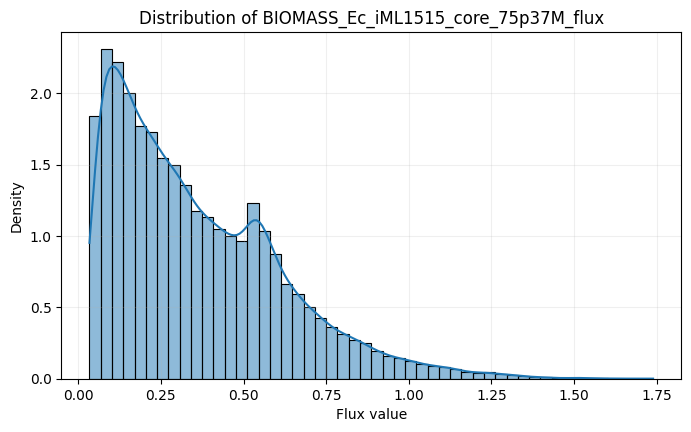

In [15]:
def plot_flux_distribution(y, outputs, flux_name, bins=50, figsize=(8, 4.5)):
    """Plot the distribution of a selected output flux from target tensor y."""
    if flux_name not in outputs:
        raise ValueError(f"{flux_name} not found in outputs.")
    flux_idx = outputs.index(flux_name)
    flux_values = y[:, flux_idx]
    if isinstance(flux_values, torch.Tensor):
        flux_values = flux_values.detach().cpu().numpy()
    else:
        flux_values = np.asarray(flux_values)

    plt.figure(figsize=figsize)
    sns.histplot(flux_values, bins=bins, kde=True, stat="density", color="tab:blue")
    plt.title(f"Distribution of {flux_name}")
    plt.xlabel("Flux value")
    plt.ylabel("Density")
    plt.grid(alpha=0.2)
    plt.show()

plot_flux_distribution(y, outputs, "BIOMASS_Ec_iML1515_core_75p37M_flux")

### Plot Results

In [16]:
today = date.today().isoformat()
pic_dir = f"./pics/{today}/{model_name}"

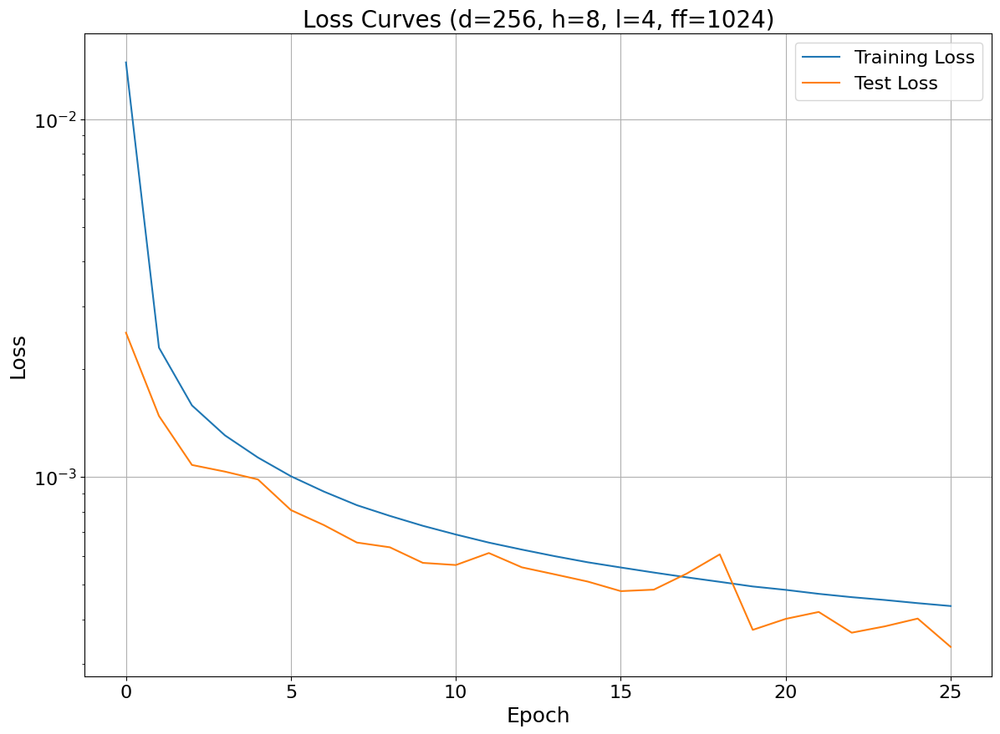

In [17]:
plot_loss_curves(
    train_losses,
    test_losses,
    d_model=config['d_model'],
    n_heads=config['n_heads'],
    n_layers=config['n_layers'],
    d_ff=config['d_ff']
)

BIOMASS_Ec_iML1515_core_75p37M_flux:
------------------------------------------------------------
BIOMASS_Ec_iML1515_core_75p37M_flux token index: 2668
injected medium slot: False
y_true range: 0.03401843458414078 to 1.7261155843734741
y_pred range: 0.035093601793050766 to 1.6403931379318237
R2: 0.9996
MAE: 0.003674
RMSE: 0.005181


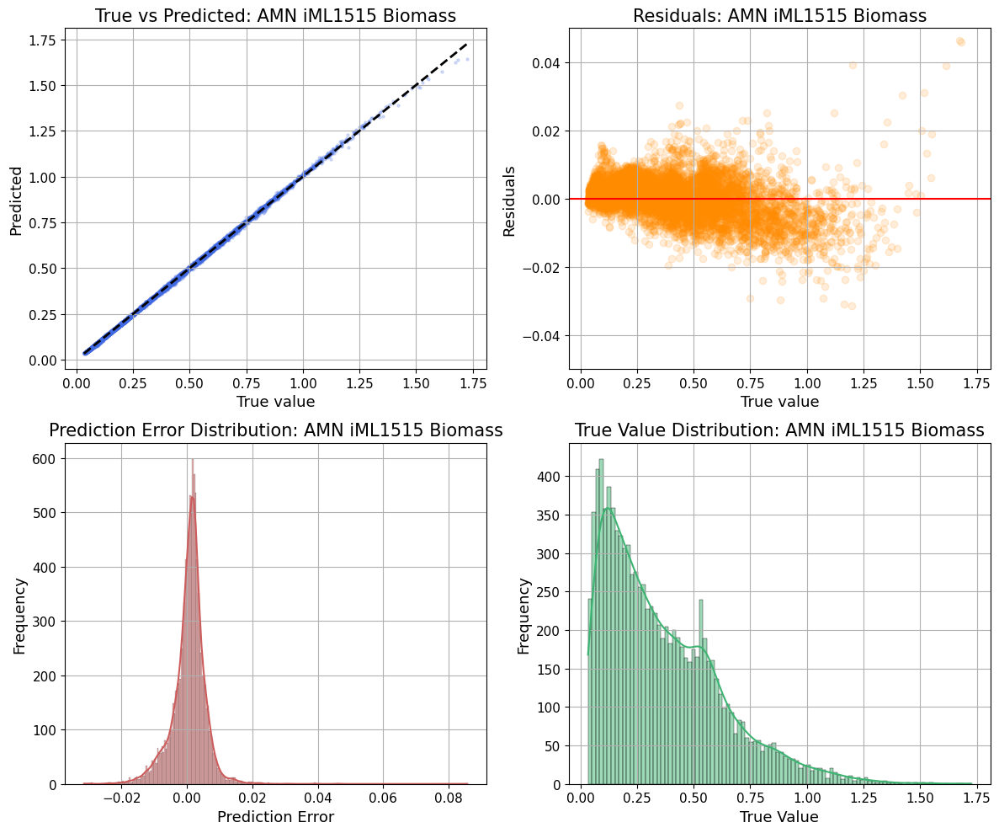

In [18]:
diagnostics_to_plot = ['BIOMASS_Ec_iML1515_core_75p37M_flux']

for flux_name in diagnostics_to_plot:
    save_path = f"{pic_dir}/{flux_name}"
    print(f'{flux_name}:')
    print(60 * '-')
    plot_flux(model, X_test, y_test, outputs, flux_name, save_path=save_path)

GLUDy_flux:
------------------------------------------------------------
GLUDy_flux token index: 1404
injected medium slot: False
y_true range: -6.614126205444336 to 2.01672101020813
y_pred range: -6.697403907775879 to 2.031416654586792
R2: 0.9952
MAE: 0.046519
RMSE: 0.079297


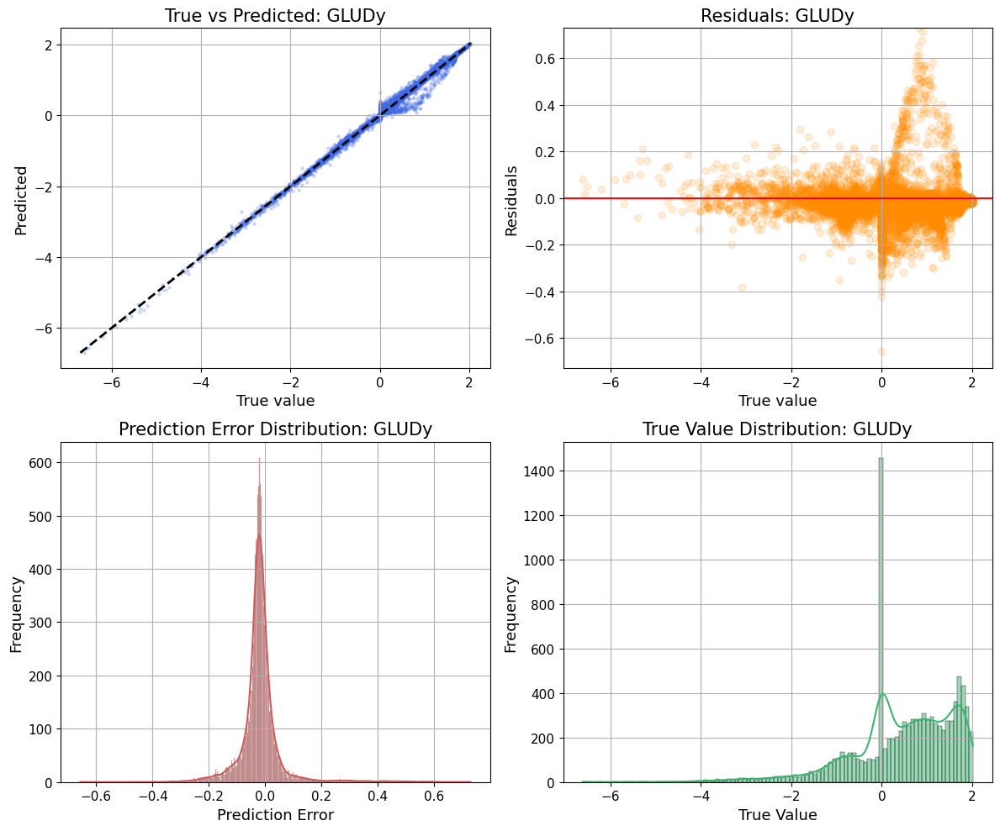

EX_co2_e_flux:
------------------------------------------------------------
EX_co2_e_flux token index: 45
injected medium slot: True
y_true range: 0.15830528736114502 to 33.89672088623047
y_pred range: 0.12794232368469238 to 33.144859313964844
R2: 0.9998
MAE: 0.057767
RMSE: 0.084384


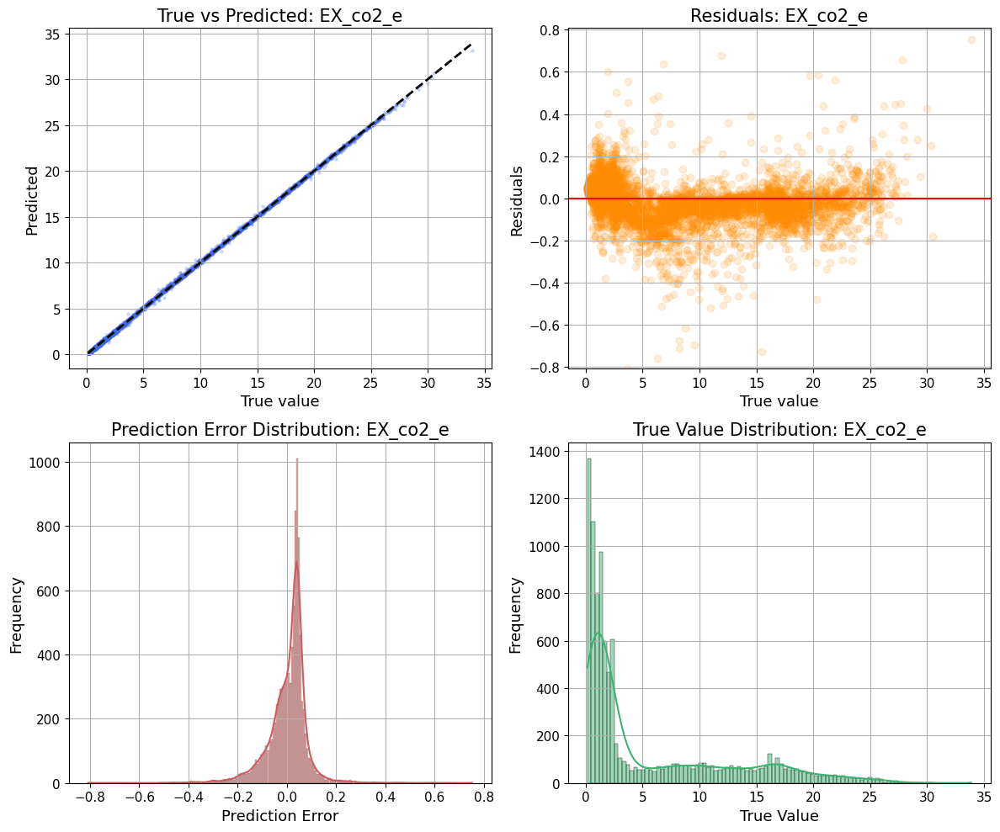

O2tpp_flux:
------------------------------------------------------------
O2tpp_flux token index: 734
injected medium slot: False
y_true range: 1.0 to 24.989999771118164
y_pred range: 0.9647970199584961 to 24.954130172729492
R2: 1.0000
MAE: 0.018021
RMSE: 0.028491


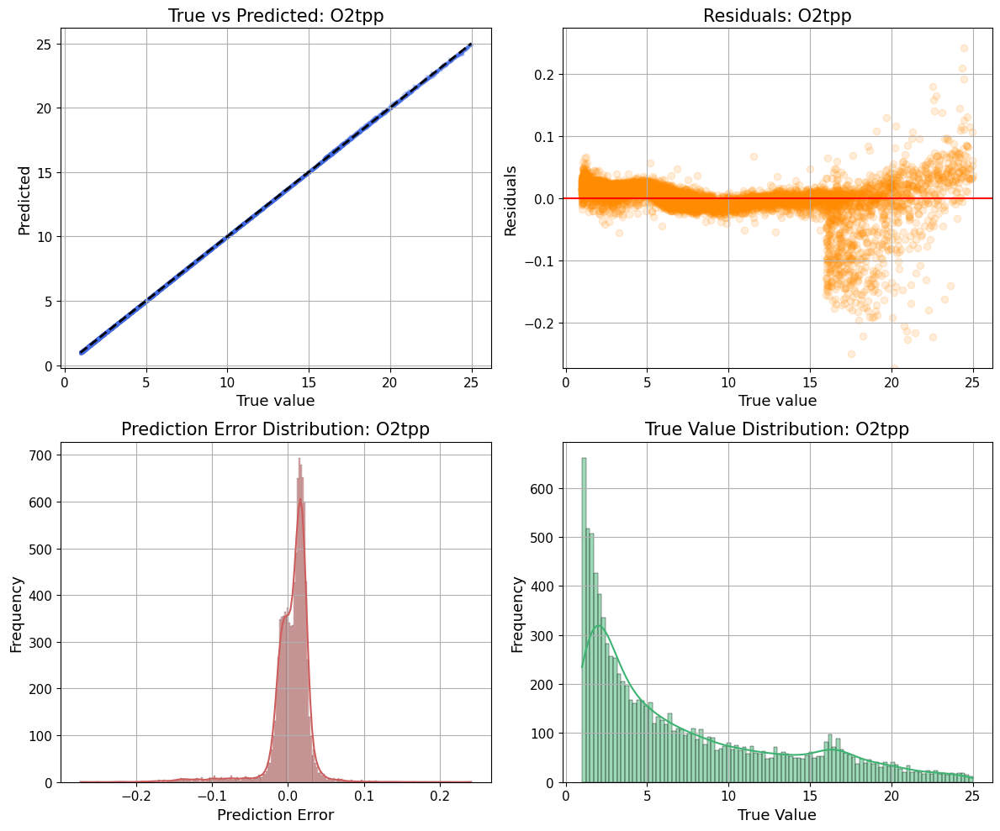

In [19]:
diagnostics_to_plot = ['GLUDy_flux', 'EX_co2_e_flux', 'O2tpp_flux']

for flux_name in diagnostics_to_plot:
    save_path = f"{pic_dir}/{flux_name}"
    print(f'{flux_name}:')
    print(60 * '-')
    plot_flux(model, X_test, y_test, outputs, flux_name, save_path=None)

In [20]:
# Overall model metrics across all output fluxes (flattened)
def _compute_overall_metrics(model_ref, X_ref, y_ref, outputs_ref, device_ref, batch_size_ref):
    model_eval = model_ref.to(device_ref).eval()
    V = len(outputs_ref)

    if X_ref.shape[1] != V or y_ref.shape[1] != V:
        raise ValueError(
            f"Expected X_test/y_test second dim == len(outputs)={V}, got {X_ref.shape[1]} and {y_ref.shape[1]}"
        )

    pred_batches = []
    true_batches = []
    perm = None
    use_amp = device_ref.type == "cuda"

    with torch.inference_mode():
        for i in range(0, X_ref.shape[0], batch_size_ref):
            xb = X_ref[i:i + batch_size_ref].to(device_ref)
            yb_true = y_ref[i:i + batch_size_ref]

            if use_amp:
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    preds_all_layers, selected_indices = model_eval(xb.unsqueeze(-1), output_subset=None)
            else:
                preds_all_layers, selected_indices = model_eval(xb.unsqueeze(-1), output_subset=None)

            preds_last = preds_all_layers[:, :, -1]  # (B, S)

            if perm is None:
                selected_indices_np = selected_indices.detach().cpu().numpy()
                if selected_indices_np.ndim > 1:
                    selected_indices_np = selected_indices_np[0]
                selected_indices_np = selected_indices_np.astype(int)

                if selected_indices_np.size != V:
                    raise RuntimeError(f"Model returned {selected_indices_np.size} outputs, expected {V}.")

                inv = np.full(V, -1, dtype=np.int64)
                inv[selected_indices_np] = np.arange(selected_indices_np.size, dtype=np.int64)
                if (inv < 0).any():
                    missing = np.where(inv < 0)[0].tolist()
                    raise RuntimeError(f"Missing output indices in model forward pass: {missing[:10]}")
                perm = torch.as_tensor(inv, device=preds_last.device, dtype=torch.long)

            yb_pred = preds_last.index_select(1, perm).detach().cpu().numpy().astype(np.float32, copy=False)
            pred_batches.append(yb_pred)
            true_batches.append(yb_true.detach().cpu().numpy().astype(np.float32, copy=False))

            del xb, preds_all_layers, preds_last, selected_indices
            if device_ref.type == "cuda":
                torch.cuda.empty_cache()

    y_pred_full = np.concatenate(pred_batches, axis=0)
    y_true_full = np.concatenate(true_batches, axis=0)

    overall_r2 = r2_score(y_true_full.ravel(), y_pred_full.ravel())
    overall_mae = mean_absolute_error(y_true_full.ravel(), y_pred_full.ravel())
    overall_rmse = root_mean_squared_error(y_true_full.ravel(), y_pred_full.ravel())
    return overall_r2, overall_mae, overall_rmse

original_device = next(model.parameters()).device
preferred_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if preferred_device.type == "cuda":
    batch_size_metrics = 2
else:
    batch_size_metrics = 32

used_device = preferred_device
try:
    overall_r2, overall_mae, overall_rmse = _compute_overall_metrics(
        model, X_test, y_test, outputs, preferred_device, batch_size_metrics
    )
except RuntimeError as e:
    if preferred_device.type == "cuda" and "out of memory" in str(e).lower():
        print("CUDA OOM during overall metrics; falling back to CPU...")
        torch.cuda.empty_cache()
        used_device = torch.device("cpu")
        overall_r2, overall_mae, overall_rmse = _compute_overall_metrics(
            model, X_test, y_test, outputs, used_device, 32
        )
    else:
        raise
finally:
    model.to(original_device)

print("Overall model metrics (all fluxes, flattened):")
print(f"Device used: {used_device}")
print(f"R2:   {overall_r2:.4f}")
print(f"MAE:  {overall_mae:.6f}")
print(f"RMSE: {overall_rmse:.6f}")

Overall model metrics (all fluxes, flattened):
Device used: cuda
R2:   0.9997
MAE:  0.003206
RMSE: 0.028317


### Overall model metrics on B and E test distributions

Score the complete independent B test CSV selected by the MINN notebook and the E test CSV selected by the E notebook. Both contain the same 2,712 ordered flux targets as the AMN checkpoint. Inject **every source nutrient value** at its matching `*_flux` token in the checkpoint's full reaction vocabulary; set all other context slots to zero. With `output_subset=None`, FluxTransformer reads the complete context, including tokens outside its 38 declared training-input slots. The table and saved protocol identify those additional source inputs and their activity. This tests full source context, but nonzero values at additional tokens remain outside AMN's training-input distribution. Report pooled regression R2, MAE and RMSE over every row and flux; source solver and bound policies also differ from AMN's training data.

In [21]:
from pathlib import Path
import json

from generate_ecoli_iML1515_B_data import (
    CONTEXT_EXCHANGES as B_CONTEXT_EXCHANGES,
    BASE_EXCHANGES as B_BASE_EXCHANGES,
)
from generate_ecoli_iML1515_E_data import build_input_columns as build_e_input_columns

AMN_SHIFT_TESTS = {
    "B (MINN Tazza test)": {
        "path": Path("./data/iML1515_B_test_data_50000_samples.csv"),
        "inputs": B_CONTEXT_EXCHANGES + B_BASE_EXCHANGES,
    },
    "E (general test)": {
        "path": Path("./data/iML1515_E_test_data_50000_samples.csv"),
        "inputs": build_e_input_columns(),
    },
}

checkpoint_inputs = list(data_info["input_cols"])
checkpoint_outputs = list(data_info["output_cols"])
if list(outputs) != checkpoint_outputs or model.vocab_size != len(checkpoint_outputs):
    raise ValueError("AMN test output order or vocabulary differs from the checkpoint.")
if len(checkpoint_inputs) != len(set(checkpoint_inputs)):
    raise ValueError("AMN checkpoint has duplicate nutrient inputs.")
output_lookup = {name: index for index, name in enumerate(checkpoint_outputs)}
expected_injection = [output_lookup[f"{name}_flux"] for name in checkpoint_inputs]
actual_injection = model.input_token_indices.detach().cpu().tolist()
if actual_injection != expected_injection:
    raise ValueError("AMN checkpoint input-token indices do not match its nutrient names.")

shift_protocol = {}
for dataset, spec in AMN_SHIFT_TESTS.items():
    test_path = spec["path"]
    if not test_path.is_file():
        raise FileNotFoundError(test_path)
    if test_path.resolve() in {Path(DATA_PATH).resolve(), Path(data_info["dataset"]).resolve()}:
        raise ValueError(f"{dataset} must use a distinct held-out CSV.")
    source_inputs = list(spec["inputs"])
    header = pd.read_csv(test_path, nrows=0).columns.tolist()
    if header != source_inputs + checkpoint_outputs:
        raise ValueError(f"{dataset} input schema or output order differs from its generator and AMN checkpoint.")
    if len(source_inputs) != len(set(source_inputs)):
        raise ValueError(f"{dataset} has duplicate nutrient inputs.")
    missing_tokens = [name for name in source_inputs if f"{name}_flux" not in output_lookup]
    if missing_tokens:
        raise ValueError(f"{dataset} inputs have no matching checkpoint flux tokens: {missing_tokens}")
    shift_protocol[dataset] = {
        "path": str(test_path),
        "source_inputs": source_inputs,
        "injected_flux_tokens": [f"{name}_flux" for name in source_inputs],
        "additional_source_inputs": [name for name in source_inputs if name not in checkpoint_inputs],
        "zero_filled_trained_inputs": [name for name in checkpoint_inputs if name not in source_inputs],
        "output_count": len(checkpoint_outputs),
        "aggregation": "pooled over every row and flux",
    }


def compute_amn_shift_metrics(spec, protocol, inference_device, batch_size, expected_rows=50_000):
    source_inputs = protocol["source_inputs"]
    additional_inputs = protocol["additional_source_inputs"]
    source_token_indices = [output_lookup[f"{name}_flux"] for name in source_inputs]
    n_rows = n_values = additional_active_rows = 0
    additional_input_active_rows = {name: 0 for name in additional_inputs}
    sum_true = sum_true_sq = sum_abs_error = sum_sq_error = 0.0
    selected_order = output_order = None
    model.to(inference_device).eval()
    with torch.inference_mode():
        for frame in pd.read_csv(spec["path"], chunksize=128):
            if not np.isfinite(frame.to_numpy(np.float64)).all():
                raise ValueError("Distribution-shift test CSV contains nonfinite values.")
            if additional_inputs:
                additional_active = frame[additional_inputs].ne(0)
                additional_active_rows += int(additional_active.any(axis=1).sum())
                for name in additional_inputs:
                    additional_input_active_rows[name] += int(additional_active[name].sum())
            source_values = frame[source_inputs].to_numpy(np.float32)
            truth = frame[checkpoint_outputs].to_numpy(np.float64)
            for start in range(0, len(frame), batch_size):
                stop = min(start + batch_size, len(frame))
                context = torch.zeros(stop - start, model.vocab_size, 1, device=inference_device)
                context[:, source_token_indices, 0] = torch.as_tensor(source_values[start:stop], device=inference_device)
                if inference_device.type == "cuda":
                    with torch.autocast(device_type="cuda", dtype=torch.float16):
                        layers, selected_indices = model(context, output_subset=None)
                else:
                    layers, selected_indices = model(context, output_subset=None)
                selected = selected_indices.detach().cpu().numpy()
                if selected.ndim > 1:
                    if not np.all(selected == selected[0]):
                        raise ValueError("Output token order varies within a batch.")
                    selected = selected[0]
                if output_order is None:
                    if selected.size != model.vocab_size or not np.array_equal(
                        np.sort(selected), np.arange(model.vocab_size)
                    ):
                        raise ValueError("Full-output inference did not return every checkpoint token.")
                    selected_order = selected.copy()
                    output_order = torch.as_tensor(np.argsort(selected_order), device=inference_device)
                elif not np.array_equal(selected, selected_order):
                    raise ValueError("Output token order changed between batches.")
                prediction = layers[:, :, -1].index_select(1, output_order).float().cpu().numpy().astype(np.float64)
                actual = truth[start:stop]
                if not np.isfinite(prediction).all():
                    raise FloatingPointError("Nonfinite full-output predictions.")
                residual = actual - prediction
                n_rows += len(actual)
                n_values += actual.size
                sum_true += actual.sum()
                sum_true_sq += np.square(actual).sum()
                sum_abs_error += np.abs(residual).sum()
                sum_sq_error += np.square(residual).sum()
    if n_rows != expected_rows:
        raise ValueError(f"Expected {expected_rows:,} held-out rows, got {n_rows}.")
    protocol["additional_input_active_rows"] = additional_input_active_rows
    sst = sum_true_sq - sum_true ** 2 / n_values
    return {
        "Rows": n_rows,
        "Rows with active additional inputs": additional_active_rows,
        "Fluxes": len(checkpoint_outputs),
        "R2": 1 - sum_sq_error / sst if sst > 0 else float("nan"),
        "MAE": sum_abs_error / n_values,
        "RMSE": np.sqrt(sum_sq_error / n_values),
        "Device": str(inference_device),
    }


shift_metric_rows = []
original_device = next(model.parameters()).device
try:
    for dataset, spec in AMN_SHIFT_TESTS.items():
        protocol = shift_protocol[dataset]
        used_device = original_device
        try:
            scores = compute_amn_shift_metrics(spec, protocol, used_device, batch_size_metrics)
        except RuntimeError as exc:
            if used_device.type != "cuda" or "out of memory" not in str(exc).lower():
                raise
            print(f"CUDA OOM on {dataset}; retrying on CPU.")
            torch.cuda.empty_cache()
            used_device = torch.device("cpu")
            scores = compute_amn_shift_metrics(spec, protocol, used_device, 32)
        shift_metric_rows.append({
            "Dataset": dataset,
            "Source inputs": len(protocol["source_inputs"]),
            "Injected source inputs": len(protocol["injected_flux_tokens"]),
            "Additional inputs beyond training schema": len(protocol["additional_source_inputs"]),
            "Zero-filled trained inputs": len(protocol["zero_filled_trained_inputs"]),
            **scores,
        })
finally:
    model.to(original_device)

amn_distribution_shift_metrics_df = pd.DataFrame(shift_metric_rows)
shift_artifact_dir = Path(pic_dir)
shift_artifact_dir.mkdir(parents=True, exist_ok=True)
with (shift_artifact_dir / "overall_distribution_shift_protocol.json").open("w", encoding="utf-8") as handle:
    json.dump(shift_protocol, handle, indent=2)
amn_distribution_shift_metrics_df.to_csv(shift_artifact_dir / "overall_distribution_shift_metrics.csv", index=False)
print("AMN full-output metrics on B and E test distributions (all rows and fluxes, flattened):")
display(amn_distribution_shift_metrics_df)


AMN full-output metrics on B and E test distributions (all rows and fluxes, flattened):


,Dataset,Source inputs,Injected source inputs,Additional inputs beyond training schema,Zero-filled trained inputs,Rows,Rows with active additional inputs,Fluxes,R2,MAE,RMSE,Device
0,B (MINN Tazza test),26,26,2,14,50000,50000,2712,0.325715,0.132121,1.155919,cuda:0
1,E (general test),72,72,34,0,50000,44972,2712,0.395681,0.105546,1.055914,cuda:0


Reaction colors:
  GLCptspp: #700080
  GLCt2pp: #58009f
  HEX1: #0000d1
  PGI: #007add
  PFK: #00a2c3
  FBA: #00aa8b
  TPI: #00a400
  GAPD: #00d200
  PGK: #0fff00
  PGM: #d4f700
  ENO: #fdcf00
  PYK: #ff7500
  PPS: #e90000
  FBP: #cc0c0c
Plot saved to ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024/A_1M_d256_h8_l4_ff1024_tsne_glycolysis_reactions


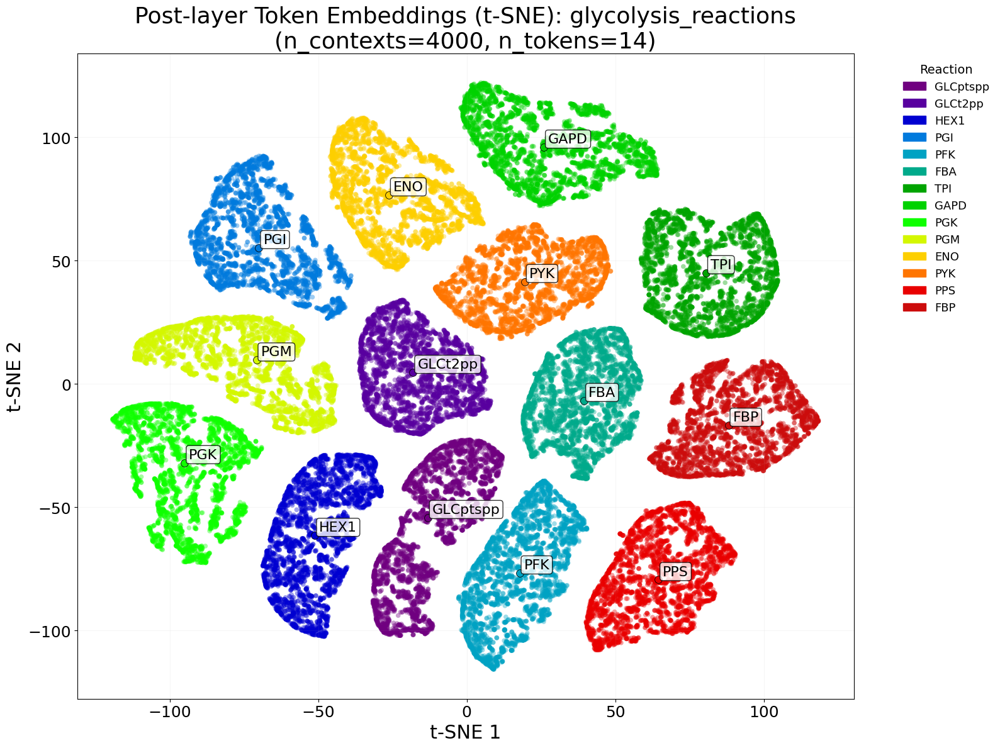

In [22]:
save_path = f"{pic_dir}/{model_name}_tsne_glycolysis_reactions"

plot_reaction_subset_tsne(
    model,
    outputs,
    X_test,
    glycolysis_reactions,
    subset_name="glycolysis_reactions",
    n_samples=4000,
    perplexity=40.0,
    annotate=True,
    annotate_fontsize=16,
    save_path=save_path,
)


Plot saved to ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024/A_1M_d256_h8_l4_ff1024_tsne_glycolysis_reactions_rainbow


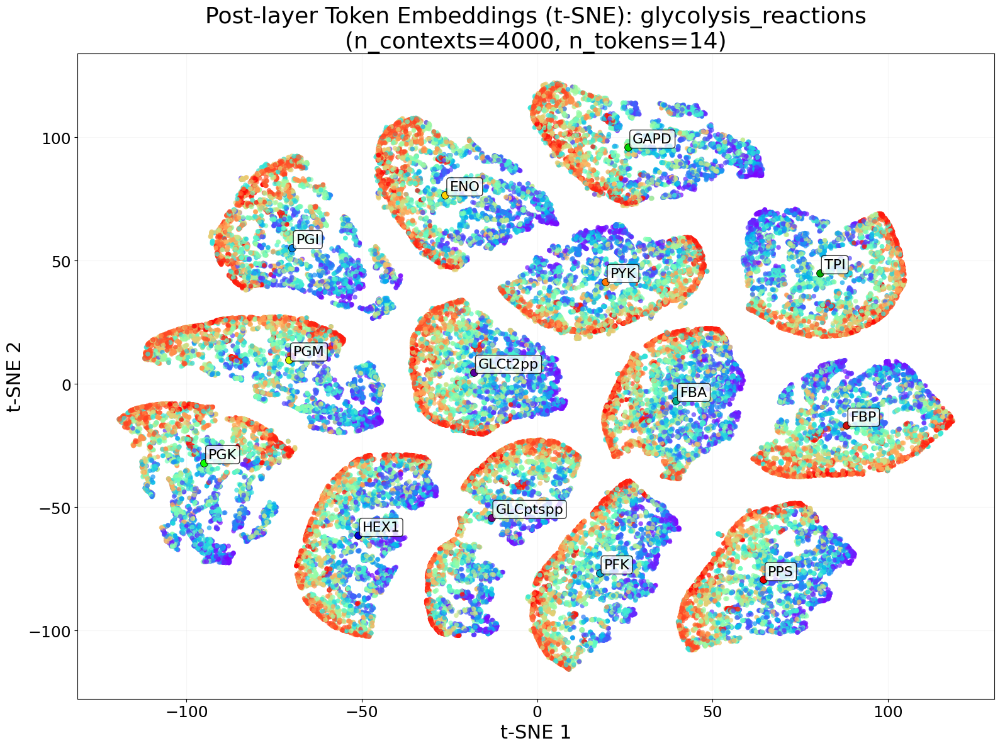

In [23]:
save_path = f"{pic_dir}/{model_name}_tsne_glycolysis_reactions_rainbow"

plot_reaction_subset_tsne(
    model,
    outputs,
    X_test,
    glycolysis_reactions,
    subset_name="glycolysis_reactions",
    n_samples=4000,
    perplexity=40.0,
    annotate=True,
    annotate_fontsize=16,
    sample_color_mode="rainbow",
    save_path=save_path,
)


Reaction colors:
  G6PDH2r: #700080
  PGL: #0000c5
  GND: #009bd7
  RPI: #009e28
  RPE: #00e700
  TKT1: #e8f000
  TALA: #ff5100
  TKT2: #cc0c0c
Plot saved to ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024/A_1M_d256_h8_l4_ff1024_tsne_ppp_reactions


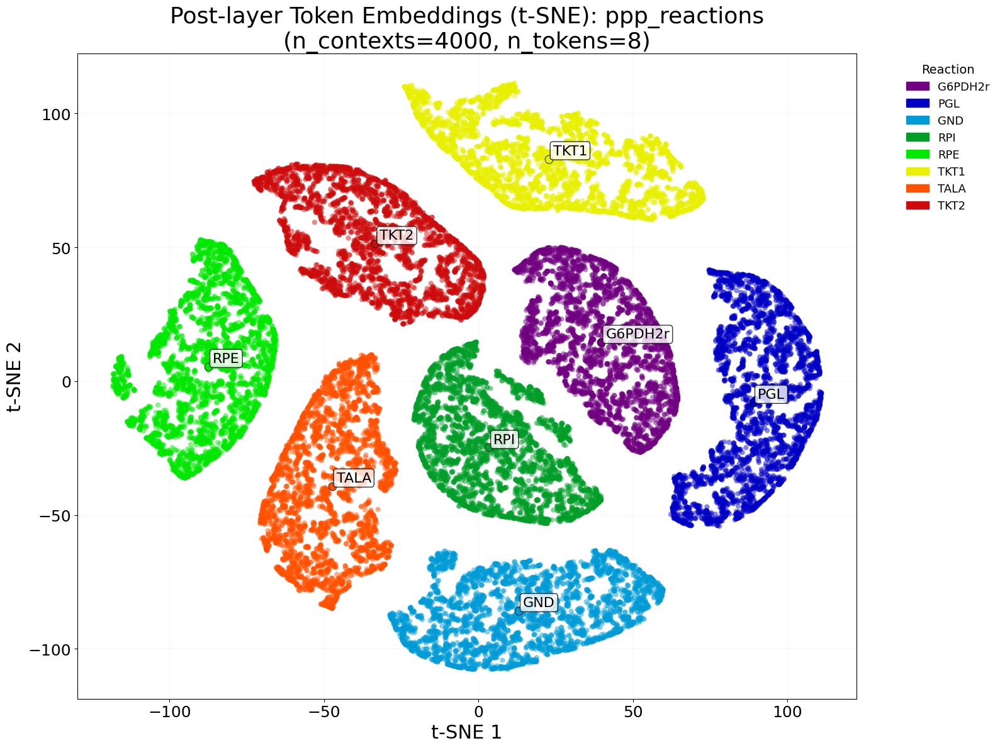

In [24]:
save_path = f"{pic_dir}/{model_name}_tsne_ppp_reactions"

plot_reaction_subset_tsne(
    model,
    outputs,
    X_test,
    ppp_reactions,
    subset_name="ppp_reactions",
    n_samples=4000,
    perplexity=40.0,
    annotate=True,
    annotate_fontsize=16,
    save_path=save_path,
)


Plot saved to ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024/A_1M_d256_h8_l4_ff1024_tsne_tca_reactions_rainbow


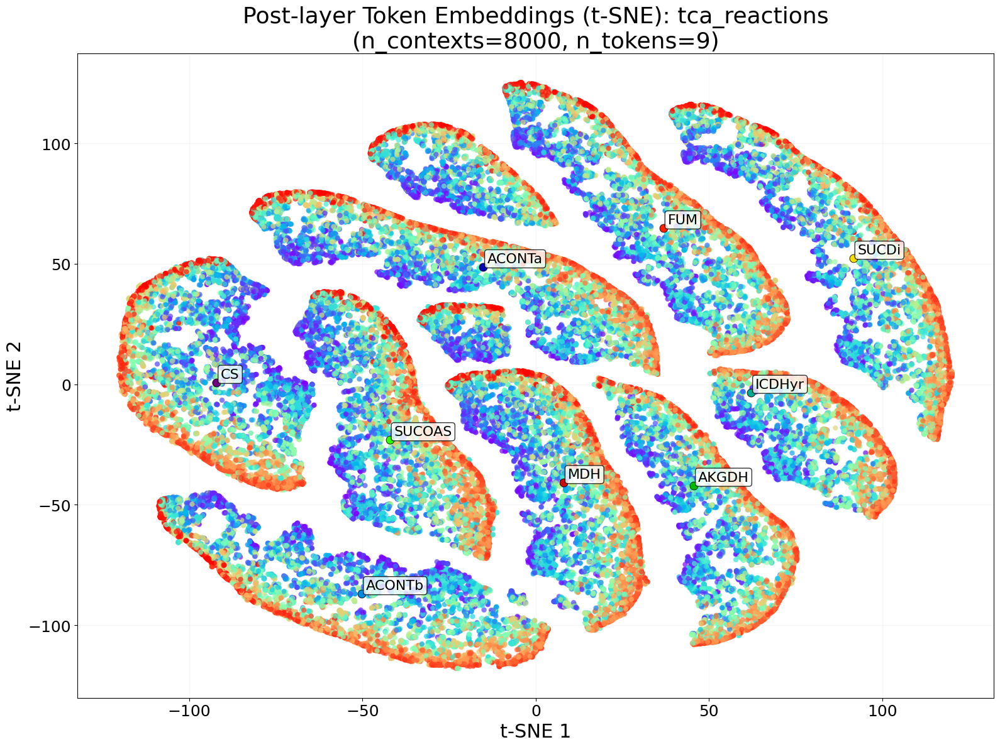

In [25]:
save_path = f"{pic_dir}/{model_name}_tsne_tca_reactions_rainbow"

plot_reaction_subset_tsne(
    model,
    outputs,
    X_test,
    tca_reactions,
    subset_name="tca_reactions",
    n_samples=8000,
    perplexity=40.0,
    annotate=True,
    annotate_fontsize=16,
    sample_color_mode="rainbow",
    save_path=save_path,
)


Pre-embedding points plotted: 7
Plot saved to ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024/A_1M_d256_h8_l4_ff1024_tsne_fermentation_reactions_gray


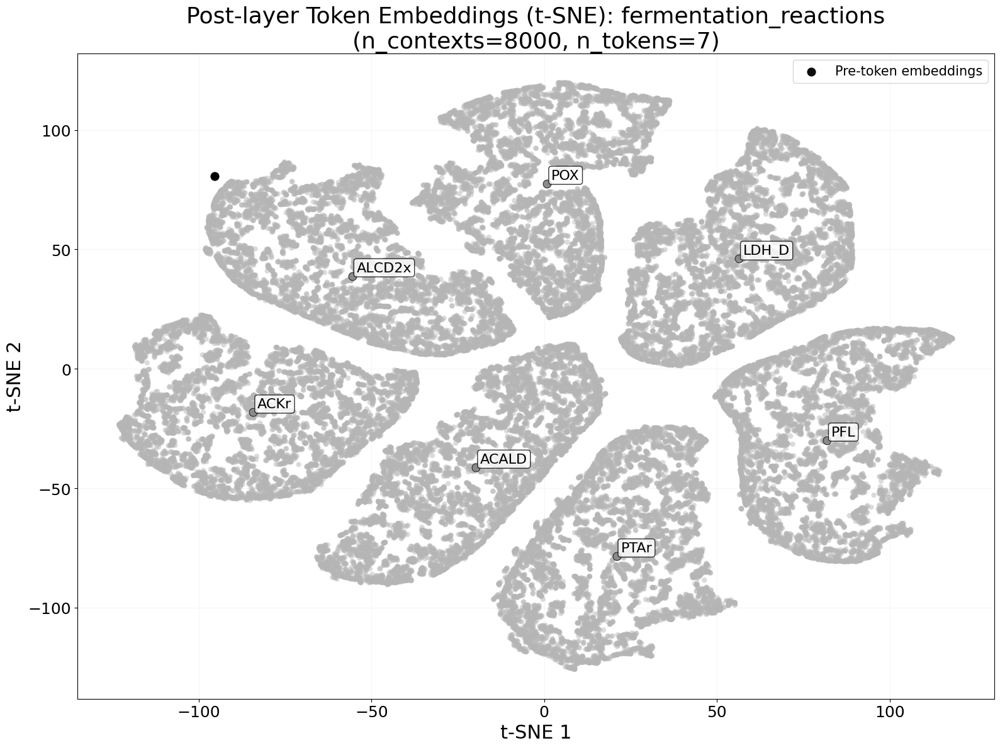

In [26]:
save_path = f"{pic_dir}/{model_name}_tsne_fermentation_reactions_gray"

plot_reaction_subset_tsne(
    model,
    outputs,
    X_test,
    fermentation_reactions,
    subset_name="fermentation_reactions",
    n_samples=8000,
    perplexity=40.0,
    annotate=True,
    annotate_fontsize=16,
    sample_color_mode="gray",
    show_pre_embeddings=True,
    save_path=save_path,
)


### AMN Fructose–Oxygen Sweep t-SNE

Controlled 100 × 100 fructose/oxygen grid from `generate_AMN_sweep.py`.
All 10,000 contexts are retained without a train/test split. One t-SNE fit
supplies both single-variable panels and the separate bivariate figure.
The post-layer forward uses the selected pathway plus injected nutrient tokens,
matching the existing plots. This is a qualitative subset visualization;
smoothness or cluster positions in t-SNE alone do not establish mechanism.

For the 140,000 glycolysis points, this experiment uses openTSNE's FFT method
with PCA initialization, seed 10 and one worker for reproducibility in the same
environment. Existing sklearn t-SNE experiments are unchanged. Metadata stays
in generator row order and is checked against the actual model input values.

In [27]:
SWEEP_DATA_PATH = "./data/iML1515_AMN_sweep_10000_samples.csv"
SWEEP_METADATA_PATH = "./data/iML1515_AMN_sweep_10000_metadata.csv"


def validate_AMN_sweep_data(
    X_sweep_np, y_sweep_np, sweep_inputs, sweep_outputs,
    sweep_input_token_indices, sweep_metadata, model_ref,
    reference_outputs, checkpoint_data_info, *, carbon_levels=100, oxygen_levels=100,
    carbon_range=(0.05, 2.2), oxygen_range=(1.0, 10.0),
):
    """Validate the full Cartesian grid in place; never independently sort metadata."""
    required = ["sample_id", "sweep_fructose_rate", "sweep_oxygen_rate",
                "sweep_fructose_index", "sweep_oxygen_index"]
    missing = set(required) - set(sweep_metadata.columns)
    if missing:
        raise ValueError(f"Sweep metadata is missing columns: {sorted(missing)}")
    n = carbon_levels * oxygen_levels
    if len(X_sweep_np) != n or len(y_sweep_np) != n or len(sweep_metadata) != n:
        raise ValueError(f"Expected {n} aligned sweep rows; got inputs={len(X_sweep_np)}, "
                         f"fluxes={len(y_sweep_np)}, metadata={len(sweep_metadata)}")
    if sweep_metadata["sample_id"].duplicated().any():
        raise ValueError("Duplicate sweep sample_id values")
    if not np.array_equal(sweep_metadata["sample_id"].to_numpy(), np.arange(n)):
        raise ValueError("Sweep sample_id must be exactly 0..N-1 in CSV row order")
    if list(sweep_outputs) != list(reference_outputs):
        raise ValueError("Sweep output order differs from the loaded model outputs")
    if list(sweep_outputs) != list(checkpoint_data_info["output_cols"]):
        raise ValueError("Sweep output order differs from checkpoint output_cols")
    if len(sweep_inputs) != len(set(sweep_inputs)) or set(sweep_inputs) != set(checkpoint_data_info["input_cols"]):
        raise ValueError("Sweep nutrient inputs do not match the checkpoint AMN input set")
    if X_sweep_np.shape != (n, int(model_ref.vocab_size)) or y_sweep_np.shape != X_sweep_np.shape:
        raise ValueError("Sweep arrays must both have shape (N, model.vocab_size)")
    expected_mapping = [sweep_outputs.index(f"{name}_flux") for name in sweep_inputs]
    if list(sweep_input_token_indices) != expected_mapping:
        raise ValueError("Sweep nutrient-to-output token mapping is incorrect")
    if set(expected_mapping) != set(model_ref.input_token_indices.detach().cpu().tolist()):
        raise ValueError("Sweep input tokens differ from the model's injected tokens")
    if not np.isfinite(X_sweep_np).all() or not np.isfinite(y_sweep_np).all():
        raise ValueError("Sweep input/flux arrays contain nonfinite values")

    expected_fidx = np.repeat(np.arange(carbon_levels), oxygen_levels)
    expected_oidx = np.tile(np.arange(oxygen_levels), carbon_levels)
    if not np.array_equal(sweep_metadata["sweep_fructose_index"], expected_fidx):
        raise ValueError("Fructose grid indices do not match fructose-major row order")
    if not np.array_equal(sweep_metadata["sweep_oxygen_index"], expected_oidx):
        raise ValueError("Oxygen grid indices do not match oxygen-minor row order")
    for nutrient, exchange, levels, limits, indices in (
        ("fructose", "EX_fru_e", carbon_levels, carbon_range, expected_fidx),
        ("oxygen", "EX_o2_e", oxygen_levels, oxygen_range, expected_oidx),
    ):
        values = sweep_metadata[f"sweep_{nutrient}_rate"].to_numpy(dtype=float)
        if not np.isfinite(values).all():
            raise ValueError(f"Nonfinite {nutrient} metadata")
        unique = np.unique(values)
        if len(unique) != levels or not np.allclose(unique, np.linspace(*limits, levels), rtol=1e-6, atol=1e-7):
            raise ValueError(f"Expected {levels} linear {nutrient} levels over {limits}")
        if not np.allclose(values, unique[indices], rtol=1e-6, atol=1e-7):
            raise ValueError(f"{nutrient} rates do not match their grid indices")
        token_idx = sweep_outputs.index(f"{exchange}_flux")
        if not np.allclose(X_sweep_np[:, token_idx], values, rtol=1e-6, atol=1e-7):
            raise ValueError(f"{nutrient} metadata is misaligned with samples CSV uptake values")
    if sweep_metadata.duplicated(["sweep_fructose_rate", "sweep_oxygen_rate"]).any():
        raise ValueError("Duplicate fructose/oxygen grid combinations")
    print(f"Sweep conditions: {n:,}")
    print(f"Fructose levels: {carbon_levels}, range {carbon_range[0]:.2f}–{carbon_range[1]:.2f}")
    print(f"Oxygen levels: {oxygen_levels}, range {oxygen_range[0]:.2f}–{oxygen_range[1]:.2f}")
    print(f"Grid complete: {carbon_levels} × {oxygen_levels}")


# A dedicated cache avoids overwriting mappings belonging to other datasets.
(X_sweep_np, y_sweep_np, sweep_inputs, sweep_outputs,
 sweep_input_token_indices, sweep_out_indices) = load_data(
    SWEEP_DATA_PATH, cache_dir=os.path.join("tmp_memmap", "amn_sweep_tsne"),
)
sweep_metadata = pd.read_csv(SWEEP_METADATA_PATH)
validate_AMN_sweep_data(
    X_sweep_np, y_sweep_np, sweep_inputs, sweep_outputs,
    sweep_input_token_indices, sweep_metadata, model, outputs, data_info,
)
# Keep the full grid on CPU; only inference batches move to the model device.
X_sweep = torch.tensor(X_sweep_np, dtype=torch.float32)
if tuple(X_sweep.shape) != (len(sweep_metadata), int(model.vocab_size)):
    raise ValueError("X_sweep must have shape (N, model.vocab_size)")


Loaded data with 10000 samples from ./data/iML1515_AMN_sweep_10000_samples.csv
Extracted input columns count:  38
Extracted output columns count: 2712
Medium constraints are injected into these token indices (in outputs order):
[40, 45, 86, 92, 104, 164, 304, 621, 700, 859, 913, 934, 970, 1424, 1478, 1485, 1500, 1534, 1535, 1836, 1981, 2243, 2320, 99, 108, 98, 1490, 217, 114, 1439, 288, 303, 206, 209, 106, 347, 112, 111]
Sweep conditions: 10,000
Fructose levels: 100, range 0.05–2.20
Oxygen levels: 100, range 1.00–10.00
Grid complete: 100 × 100


In [28]:
def plot_AMN_sweep_tsne(
    model, token_names, X_context, sweep_metadata, reaction_subset, *,
    pic_dir, model_name, perplexity=40.0, random_state=10, batch_size=128,
    annotate=True, annotate_fontsize=16,
):
    """Extract once, fit once, and render three views of the same geometry.

    token_id_labels indexes reaction_ids; sample_id_labels indexes the original
    metadata rows. All conditions are used in their validated generator order.
    """
    from openTSNE import TSNE as SweepTSNE

    if reaction_subset not in pathway_reaction_lists:
        raise ValueError(f"Unknown pathway {reaction_subset!r}; choose from {list(pathway_reaction_lists)}")
    selected_names = [_reaction_token_name(r, token_names)
                      for r in pathway_reaction_lists[reaction_subset]]
    if not selected_names or any(name is None for name in selected_names):
        raise ValueError(f"Unresolved reaction tokens for {reaction_subset}")
    selected_names = list(dict.fromkeys(selected_names))
    reaction_ids = [name[:-5] if name.endswith("_flux") else name for name in selected_names]
    token_indices = [token_names.index(name) for name in selected_names]
    n, n_tok = len(X_context), len(token_indices)
    if tuple(X_context.shape) != (n, int(model.vocab_size)) or len(token_names) != int(model.vocab_size):
        raise ValueError("Sweep contexts/token names do not match model vocabulary")
    if len(sweep_metadata) != n or not np.array_equal(sweep_metadata["sample_id"], np.arange(n)):
        raise ValueError("Sweep contexts require metadata in original sample_id order")
    if batch_size < 1 or perplexity <= 0 or 3 * perplexity > n * n_tok - 1:
        raise ValueError("Require positive batch size/perplexity and at least 3*perplexity+1 points")
    model_device = next(model.parameters()).device
    token_indices_tensor = torch.tensor(token_indices, dtype=torch.long, device=model_device)
    all_embeddings = []
    was_training = model.training
    model.eval()
    try:
        with torch.no_grad():
            for start in range(0, n, batch_size):
                batch_context = X_context[start:start + batch_size].to(model_device).unsqueeze(-1)
                embeddings, selected_indices = model(
                    batch_context, output_subset=token_indices_tensor, return_embedding=True,
                )
                # The forward returns sorted pathway + input tokens, not pathway order.
                selected_list = selected_indices.detach().cpu().tolist()
                if not set(token_indices).issubset(selected_list):
                    raise RuntimeError("Model did not return every requested pathway token")
                positions = torch.tensor([selected_list.index(idx) for idx in token_indices],
                                         dtype=torch.long, device=model_device)
                all_embeddings.append(embeddings.index_select(1, positions).detach().cpu())
    finally:
        model.train(was_training)
    embeddings_by_sample = torch.cat(all_embeddings, dim=0)
    if tuple(embeddings_by_sample.shape[:2]) != (n, n_tok):
        raise RuntimeError("Unexpected sample/reaction embedding axes")
    embeddings_flat = embeddings_by_sample.reshape(n * n_tok, -1).numpy()
    if not np.isfinite(embeddings_flat).all():
        raise ValueError("Nonfinite post-layer embeddings")
    token_id_labels = np.tile(np.arange(n_tok, dtype=np.int64), n)
    sample_id_labels = np.repeat(sweep_metadata["sample_id"].to_numpy(dtype=np.int64), n_tok)
    print(f"Sweep t-SNE: {n:,} contexts × {n_tok} reactions = {len(embeddings_flat):,} points")
    # One seeded fit only. FFT avoids Barnes-Hut repulsion costs at 140k points.
    embedding_2d = np.asarray(SweepTSNE(
        n_components=2, perplexity=perplexity, initialization="pca",
        random_state=random_state, negative_gradient_method="fft", n_jobs=1,
    ).fit(embeddings_flat)).copy()
    if embedding_2d.shape != (n * n_tok, 2) or not np.isfinite(embedding_2d).all():
        raise ValueError("Invalid t-SNE coordinates")
    reaction_centers = np.array([np.median(embedding_2d[token_id_labels == i], axis=0)
                                 for i in range(n_tok)])
    fructose_point_values = sweep_metadata["sweep_fructose_rate"].to_numpy()[sample_id_labels]
    oxygen_point_values = sweep_metadata["sweep_oxygen_rate"].to_numpy()[sample_id_labels]
    fructose_range = (float(fructose_point_values.min()), float(fructose_point_values.max()))
    oxygen_range = (float(oxygen_point_values.min()), float(oxygen_point_values.max()))
    bivariate_colors = make_bivariate_colors(
        fructose_point_values, oxygen_point_values, fructose_range=fructose_range, oxygen_range=oxygen_range,
    )
    reaction_colors = plt.cm.nipy_spectral(np.linspace(0.05, 0.95, n_tok))
    point_size = 4.0
    center_size = 86.0 if n_tok <= 10 else 72.0 if n_tok <= 20 else 36.0
    lower, upper = embedding_2d.min(axis=0), embedding_2d.max(axis=0)
    margin = np.maximum(upper - lower, 1e-6) * 0.05
    xlim = (lower[0] - margin[0], upper[0] + margin[0])
    ylim = (lower[1] - margin[1], upper[1] + margin[1])

    def style_sweep_axis(ax, neutral_centers=False):
        for i, center in enumerate(reaction_centers):
            ax.scatter(*center, s=center_size, marker="o",
                       color="white" if neutral_centers else reaction_colors[i],
                       edgecolor="black", linewidth=0.6, zorder=3)
            if annotate:
                ax.annotate(reaction_ids[i], center, xytext=(5, 5), textcoords="offset points",
                            fontsize=annotate_fontsize,
                            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
        ax.set(xlim=xlim, ylim=ylim)
        ax.set_xlabel("t-SNE 1", fontsize=22)
        ax.set_ylabel("t-SNE 2", fontsize=22)
        ax.tick_params(labelsize=18)
        ax.grid(alpha=0.1)

    pathway_title = reaction_subset.removesuffix("_reactions").replace("_", " ")
    title = f"AMN nutrient sweep: {pathway_title} reaction embeddings"
    unit = r"(mmol gDW$^{-1}$ h$^{-1}$)"
    os.makedirs(pic_dir, exist_ok=True)
    filename_base = os.path.join(str(pic_dir), f"{model_name}_tsne_AMN_sweep_{reaction_subset}")
    fig, axes = plt.subplots(1, 2, figsize=(24, 10))
    for ax, values, cmap, limits, nutrient in zip(
        axes, [fructose_point_values, oxygen_point_values], ["viridis", "plasma"],
        [fructose_range, oxygen_range], ["Fructose", "Oxygen"],
    ):
        cloud = ax.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c=values,
                           cmap=cmap, vmin=limits[0], vmax=limits[1], s=point_size,
                           alpha=0.70, edgecolors="none")
        style_sweep_axis(ax)
        ax.set_title(f"{nutrient} uptake", fontsize=26)
        colorbar = fig.colorbar(cloud, ax=ax, fraction=0.046, pad=0.04)
        colorbar.set_label(f"{nutrient} uptake bound {unit}", fontsize=18)
        colorbar.ax.tick_params(labelsize=16)
    fig.suptitle(title, fontsize=26)
    fig.tight_layout()
    single_path = filename_base + "_single_variables.png"
    fig.savefig(single_path, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close(fig)

    fig = plt.figure(figsize=(16, 12))
    layout = fig.add_gridspec(1, 2, width_ratios=[3.4, 1.2])
    ax, key_ax = fig.add_subplot(layout[0, 0]), fig.add_subplot(layout[0, 1])
    ax.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c=bivariate_colors,
               s=point_size, alpha=0.90, edgecolors="none")
    style_sweep_axis(ax, neutral_centers=True)
    legend_f, legend_o = np.meshgrid(np.linspace(*fructose_range, 100), np.linspace(*oxygen_range, 100))
    legend_colors = make_bivariate_colors(
        legend_f, legend_o, fructose_range=fructose_range, oxygen_range=oxygen_range,
    )
    key_ax.imshow(legend_colors, origin="lower", extent=[*fructose_range, *oxygen_range], aspect="auto")
    key_ax.set_box_aspect(1)
    key_ax.set_xticks(fructose_range)
    key_ax.set_yticks(oxygen_range)
    key_ax.set_xlabel(f"Fructose\n{unit}", fontsize=17)
    key_ax.set_ylabel(f"Oxygen\n{unit}", fontsize=17)
    key_ax.tick_params(labelsize=16)
    key_ax.set_title("Joint nutrient bounds", fontsize=19)
    fig.suptitle(title, fontsize=26)
    fig.tight_layout()
    bivariate_path = filename_base + "_bivariate.png"
    fig.savefig(bivariate_path, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close(fig)
    print(f"Saved: {single_path}\nSaved: {bivariate_path}")
    return dict(
        embedding_2d=embedding_2d, token_id_labels=token_id_labels,
        sample_id_labels=sample_id_labels, reaction_ids=reaction_ids,
        fructose_point_values=fructose_point_values, oxygen_point_values=oxygen_point_values,
        reaction_centers=reaction_centers, bivariate_colors=bivariate_colors,
        single_variables_path=single_path, bivariate_path=bivariate_path,
    )

In [29]:
def make_bivariate_colors(
    fructose_values, oxygen_values, *, fructose_range, oxygen_range,
):
    """Bilinear RGB palette: light gray, high-F red, high-O blue, high-both yellow-green."""
    from matplotlib.colors import to_rgb

    fructose_values, oxygen_values = np.broadcast_arrays(
        np.asarray(fructose_values, dtype=float), np.asarray(oxygen_values, dtype=float),
    )
    if not np.isfinite(fructose_values).all() or not np.isfinite(oxygen_values).all():
        raise ValueError("Bivariate nutrient values must be finite")
    if not np.isfinite([*fructose_range, *oxygen_range]).all():
        raise ValueError("Bivariate ranges must be finite")
    if fructose_range[1] <= fructose_range[0] or oxygen_range[1] <= oxygen_range[0]:
        raise ValueError("Both nutrient ranges must have positive width")
    f = np.clip((fructose_values - fructose_range[0]) / (fructose_range[1] - fructose_range[0]), 0, 1)[..., None]
    o = np.clip((oxygen_values - oxygen_range[0]) / (oxygen_range[1] - oxygen_range[0]), 0, 1)[..., None]
    low_low = np.array(to_rgb("#F0F0F0"))
    high_f = np.array(to_rgb("#D73027"))
    high_o = np.array(to_rgb("#0072B2"))
    high_both = np.array(to_rgb("#A6CE39"))
    colors = (1-f)*(1-o)*low_low + f*(1-o)*high_f + (1-f)*o*high_o + f*o*high_both
    return np.clip(colors, 0, 1)

In [30]:
RANDOM_AMN_TEST_PATH = "./data/iML1515_A_test_data_50000_samples.csv"
RANDOM_AMN_CONTEXTS = 10_000
RANDOM_AMN_SEED = 10


def load_AMN_random_contexts(path, token_names, checkpoint_info, n_contexts=10_000, seed=10):
    # Read all independent test inputs; sample from the full CSV, not X_test.
    header = list(pd.read_csv(path, nrows=0).columns)
    split = next(i for i, name in enumerate(header) if name.endswith("_flux"))
    input_names, output_names = header[:split], header[split:]
    if output_names != list(token_names) or output_names != list(checkpoint_info["output_cols"]):
        raise ValueError("Random test output tokens/order differ from the checkpoint")
    if len(input_names) != len(set(input_names)) or set(input_names) != set(checkpoint_info["input_cols"]):
        raise ValueError("Random test input tokens differ from the checkpoint")
    if os.path.realpath(path) == os.path.realpath(checkpoint_info["dataset"]):
        raise ValueError("Random contexts must come from independent test data, not training data")
    frame = pd.read_csv(path, usecols=input_names, dtype=np.float32)[input_names]
    if n_contexts < 1 or len(frame) < n_contexts:
        raise ValueError(f"Need {n_contexts} random test rows; found {len(frame)}")
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError("Nonfinite random test nutrient values")
    row_ids = np.random.default_rng(seed).choice(len(frame), size=n_contexts, replace=False)
    # Same nutrient-to-flux-token injection as load_data(), without reading unused fluxes.
    token_indices = [output_names.index(f"{name}_flux") for name in input_names]
    contexts = torch.zeros((n_contexts, len(output_names)), dtype=torch.float32)
    contexts[:, token_indices] = torch.tensor(frame.iloc[row_ids].to_numpy(), dtype=torch.float32)
    print(f"Random AMN test contexts: {n_contexts:,} of {len(frame):,}; seed={seed}")
    return contexts, row_ids


X_random_amn, random_amn_row_ids = load_AMN_random_contexts(
    RANDOM_AMN_TEST_PATH, sweep_outputs, data_info, RANDOM_AMN_CONTEXTS, RANDOM_AMN_SEED,
)


# The combined fit uses a 25 x 40 grid spanning both full nutrient ranges.
combined_fructose_indices = np.rint(np.linspace(0, 99, 25)).astype(np.int64)
combined_oxygen_indices = np.rint(np.linspace(0, 99, 40)).astype(np.int64)
combined_sweep_row_ids = (
    combined_fructose_indices[:, None] * 100 + combined_oxygen_indices[None, :]
).ravel()
if len(sweep_metadata) != 10_000 or not np.array_equal(sweep_metadata["sample_id"], np.arange(10_000)):
    raise ValueError("Combined subset requires the validated 100 x 100 sweep in generator order")
if len(np.unique(combined_sweep_row_ids)) != 1_000:
    raise ValueError("Combined sweep subset must contain 1,000 distinct grid conditions")
X_sweep_combined = X_sweep[torch.as_tensor(combined_sweep_row_ids, dtype=torch.long)]
sweep_metadata_combined = sweep_metadata.iloc[combined_sweep_row_ids].copy()
print("Combined fit: 1,000 sweep conditions (25 x 40) + 10,000 random conditions")

# Full fructose sweep along the oxygen=10 edge, retaining original source IDs.
oxygen10_sweep_row_ids = np.flatnonzero(np.isclose(sweep_metadata["sweep_oxygen_rate"], 10.0))
sweep_metadata_oxygen10 = sweep_metadata.iloc[oxygen10_sweep_row_ids].copy()
if len(oxygen10_sweep_row_ids) != 100 or not np.allclose(
    sweep_metadata_oxygen10["sweep_fructose_rate"], np.linspace(0.05, 2.2, 100),
):
    raise ValueError("Expected 100 ordered fructose levels spanning 0.05--2.2 at oxygen=10")
X_sweep_oxygen10 = X_sweep[torch.as_tensor(oxygen10_sweep_row_ids, dtype=torch.long)]


Random AMN test contexts: 10,000 of 50,000; seed=10
Combined fit: 1,000 sweep conditions (25 x 40) + 10,000 random conditions


In [31]:
def plot_AMN_combined_sweep_tsne(
    model, token_names, X_sweep_context, X_random_context, sweep_metadata, random_row_ids, reaction_subset, *,
    pic_dir, model_name, perplexity=80.0, random_state=10, batch_size=128,
    annotate=True, annotate_fontsize=16, fixed_oxygen=None,
):
    """Fit sweep and random conditions together; coordinates differ from sweep-only fits."""
    n_sweep, n_random = len(X_sweep_context), len(X_random_context)
    if n_sweep == 0 or n_random == 0:
        raise ValueError("Both sweep and random contexts are required")
    if len(random_row_ids) != n_random or len(np.unique(random_row_ids)) != n_random:
        raise ValueError("Random source row IDs must be unique and aligned")
    if len(sweep_metadata) != n_sweep or sweep_metadata["sample_id"].duplicated().any():
        raise ValueError("Sweep metadata must be aligned and have unique original sample IDs")
    for name, exchange in [("fructose", "EX_fru_e"), ("oxygen", "EX_o2_e")]:
        actual = X_sweep_context[:, token_names.index(f"{exchange}_flux")].detach().cpu().numpy()
        if not np.allclose(actual, sweep_metadata[f"sweep_{name}_rate"], rtol=1e-6, atol=1e-7):
            raise ValueError(f"Misaligned sweep {name} metadata")
    X_context = torch.cat([X_sweep_context, X_random_context], dim=0)
    if not torch.isfinite(X_context).all():
        raise ValueError("Nonfinite combined contexts")
    from openTSNE import TSNE as SweepTSNE

    if reaction_subset not in pathway_reaction_lists:
        raise ValueError(f"Unknown pathway {reaction_subset!r}; choose from {list(pathway_reaction_lists)}")
    selected_names = [_reaction_token_name(r, token_names)
                      for r in pathway_reaction_lists[reaction_subset]]
    if not selected_names or any(name is None for name in selected_names):
        raise ValueError(f"Unresolved reaction tokens for {reaction_subset}")
    selected_names = list(dict.fromkeys(selected_names))
    reaction_ids = [name[:-5] if name.endswith("_flux") else name for name in selected_names]
    token_indices = [token_names.index(name) for name in selected_names]
    n, n_tok = len(X_context), len(token_indices)
    if tuple(X_context.shape) != (n, int(model.vocab_size)) or len(token_names) != int(model.vocab_size):
        raise ValueError("Sweep contexts/token names do not match model vocabulary")
    if batch_size < 1 or perplexity <= 0 or 3 * perplexity > n * n_tok - 1:
        raise ValueError("Require positive batch size/perplexity and at least 3*perplexity+1 points")
    model_device = next(model.parameters()).device
    token_indices_tensor = torch.tensor(token_indices, dtype=torch.long, device=model_device)
    all_embeddings = []
    was_training = model.training
    model.eval()
    try:
        with torch.no_grad():
            for start in range(0, n, batch_size):
                batch_context = X_context[start:start + batch_size].to(model_device).unsqueeze(-1)
                embeddings, selected_indices = model(
                    batch_context, output_subset=token_indices_tensor, return_embedding=True,
                )
                # The forward returns sorted pathway + input tokens, not pathway order.
                selected_list = selected_indices.detach().cpu().tolist()
                if not set(token_indices).issubset(selected_list):
                    raise RuntimeError("Model did not return every requested pathway token")
                positions = torch.tensor([selected_list.index(idx) for idx in token_indices],
                                         dtype=torch.long, device=model_device)
                all_embeddings.append(embeddings.index_select(1, positions).detach().cpu())
    finally:
        model.train(was_training)
    embeddings_by_sample = torch.cat(all_embeddings, dim=0)
    if tuple(embeddings_by_sample.shape[:2]) != (n, n_tok):
        raise RuntimeError("Unexpected sample/reaction embedding axes")
    embeddings_flat = embeddings_by_sample.reshape(n * n_tok, -1).numpy()
    if not np.isfinite(embeddings_flat).all():
        raise ValueError("Nonfinite post-layer embeddings")
    token_id_labels = np.tile(np.arange(n_tok, dtype=np.int64), n)
    sample_id_labels = np.repeat(np.concatenate([
        sweep_metadata["sample_id"].to_numpy(dtype=np.int64), np.asarray(random_row_ids, dtype=np.int64),
    ]), n_tok)
    dataset_labels = np.repeat(np.array(["sweep"] * n_sweep + ["random"] * n_random), n_tok)
    sweep_mask = dataset_labels == "sweep"
    print(f"Combined sweep/random t-SNE: {n:,} contexts × {n_tok} reactions = {len(embeddings_flat):,} points")
    # One seeded fit only. FFT avoids Barnes-Hut repulsion costs at 140k points.
    embedding_2d = np.asarray(SweepTSNE(
        n_components=2, perplexity=perplexity, initialization="pca",
        random_state=random_state, negative_gradient_method="fft", n_jobs=1,
    ).fit(embeddings_flat)).copy()
    if embedding_2d.shape != (n * n_tok, 2) or not np.isfinite(embedding_2d).all():
        raise ValueError("Invalid t-SNE coordinates")
    reaction_centers = np.array([
        np.median(embedding_2d[sweep_mask & (token_id_labels == i)], axis=0) for i in range(n_tok)
    ])
    fructose_point_values = np.repeat(sweep_metadata["sweep_fructose_rate"].to_numpy(), n_tok)
    oxygen_point_values = np.repeat(sweep_metadata["sweep_oxygen_rate"].to_numpy(), n_tok)
    fructose_range = (float(fructose_point_values.min()), float(fructose_point_values.max()))
    oxygen_range = (float(oxygen_point_values.min()), float(oxygen_point_values.max()))
    if fixed_oxygen is not None:
        if fixed_oxygen != 10.0 or not np.allclose(oxygen_point_values, fixed_oxygen):
            raise ValueError("Fixed-oxygen view requires oxygen uptake 10 throughout")
        # Preserve the original palette: oxygen 10 is its high-oxygen edge.
        oxygen_range = (1.0, 10.0)
    bivariate_colors = make_bivariate_colors(
        fructose_point_values, oxygen_point_values, fructose_range=fructose_range, oxygen_range=oxygen_range,
    )
    point_size = 10.0
    center_size = 86.0 if n_tok <= 10 else 72.0 if n_tok <= 20 else 36.0
    fig = plt.figure(figsize=(16, 12))
    layout = fig.add_gridspec(1, 2, width_ratios=[3.4, 1.2])
    ax, key_ax = fig.add_subplot(layout[0, 0]), fig.add_subplot(layout[0, 1])
    ax.scatter(*embedding_2d[~sweep_mask].T, c="#D9AA73", s=3.0,
               alpha=0.20, edgecolors="none", zorder=1, label="Random AMN test conditions")
    ax.scatter(*embedding_2d[sweep_mask].T, c=bivariate_colors, s=point_size,
               alpha=0.85, edgecolors="none", zorder=2)
    for i, center in enumerate(reaction_centers):
        ax.scatter(*center, s=center_size, color="white", edgecolor="black", linewidth=0.6, zorder=3)
        if annotate:
            ax.annotate(reaction_ids[i], center, xytext=(5, 5), textcoords="offset points",
                        fontsize=annotate_fontsize,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
    ax.set_xlabel("t-SNE 1", fontsize=22)
    ax.set_ylabel("t-SNE 2", fontsize=22)
    ax.tick_params(labelsize=18)
    ax.grid(alpha=0.1)
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([], [], marker="o", linestyle="none", color="#D9AA73",
                             label="Random AMN test conditions", markersize=8)], fontsize=13)
    if fixed_oxygen is None:
        legend_f, legend_o = np.meshgrid(np.linspace(*fructose_range, 100), np.linspace(*oxygen_range, 100))
        legend_colors = make_bivariate_colors(
            legend_f, legend_o, fructose_range=fructose_range, oxygen_range=oxygen_range,
        )
        key_ax.imshow(legend_colors, origin="lower", extent=[*fructose_range, *oxygen_range], aspect="auto")
        key_ax.set_box_aspect(1)
        key_ax.set_xticks(fructose_range)
        key_ax.set_yticks(oxygen_range)
        unit = r"(mmol gDW$^{-1}$ h$^{-1}$)"
        key_ax.set_xlabel(f"Fructose\n{unit}", fontsize=17)
        key_ax.set_ylabel(f"Oxygen\n{unit}", fontsize=17)
        key_ax.tick_params(labelsize=16)
        key_ax.set_title("Sweep nutrient bounds", fontsize=19)
    else:
        from matplotlib.colors import ListedColormap, Normalize
        from matplotlib.cm import ScalarMappable
        legend_fructose = np.linspace(*fructose_range, 256)
        edge_colors = make_bivariate_colors(
            legend_fructose, np.full(256, fixed_oxygen),
            fructose_range=fructose_range, oxygen_range=oxygen_range,
        )
        key_ax.set_axis_off()
        color_axis = key_ax.inset_axes([0.20, 0.15, 0.15, 0.70])
        colorbar = fig.colorbar(
            ScalarMappable(norm=Normalize(*fructose_range), cmap=ListedColormap(edge_colors)),
            cax=color_axis,
        )
        colorbar.set_label(r"Fructose uptake (mmol gDW$^{-1}$ h$^{-1}$)", fontsize=17)
        colorbar.ax.tick_params(labelsize=16)
        colorbar.set_ticks([fructose_range[0], np.mean(fructose_range), fructose_range[1]])
        key_ax.set_title("Oxygen uptake fixed at 10", fontsize=16)
    pathway_title = reaction_subset.removesuffix("_reactions").replace("_", " ")
    title_prefix = "AMN sweep" if fixed_oxygen is None else "AMN fructose sweep (oxygen = 10)"
    fig.suptitle(f"{title_prefix} + random test conditions: {pathway_title}", fontsize=26)
    fig.tight_layout()
    os.makedirs(pic_dir, exist_ok=True)
    suffix = "with_random_bivariate" if fixed_oxygen is None else "oxygen10_with_random"
    save_path = os.path.join(str(pic_dir), f"{model_name}_tsne_AMN_sweep_{reaction_subset}_{suffix}.png")
    fig.savefig(save_path, bbox_inches="tight", dpi=300)
    plt.show()
    plt.close(fig)
    print(f"Saved: {save_path}")
    return dict(embedding_2d=embedding_2d, token_id_labels=token_id_labels,
                sample_id_labels=sample_id_labels, dataset_labels=dataset_labels,
                reaction_ids=reaction_ids, reaction_centers=reaction_centers,
                sweep_mask=sweep_mask, fructose_point_values=fructose_point_values,
                oxygen_point_values=oxygen_point_values, bivariate_colors=bivariate_colors,
                random_row_ids=np.asarray(random_row_ids).copy(), save_path=save_path)


Sweep t-SNE: 10,000 contexts × 14 reactions = 140,000 points


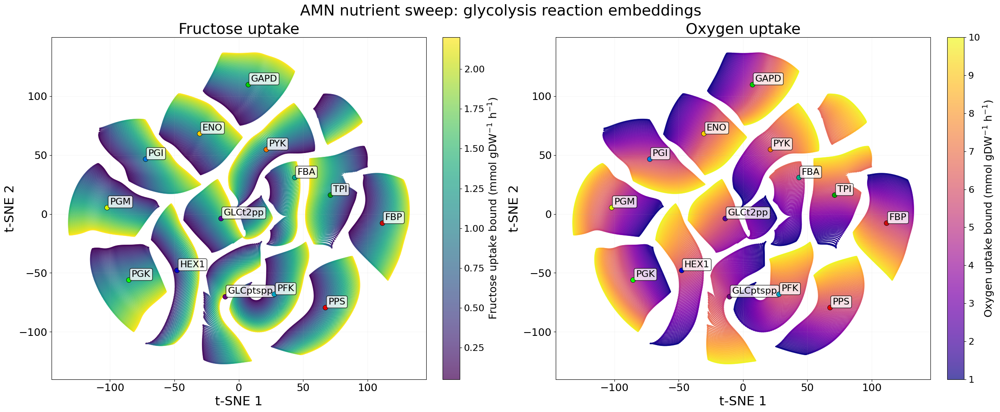

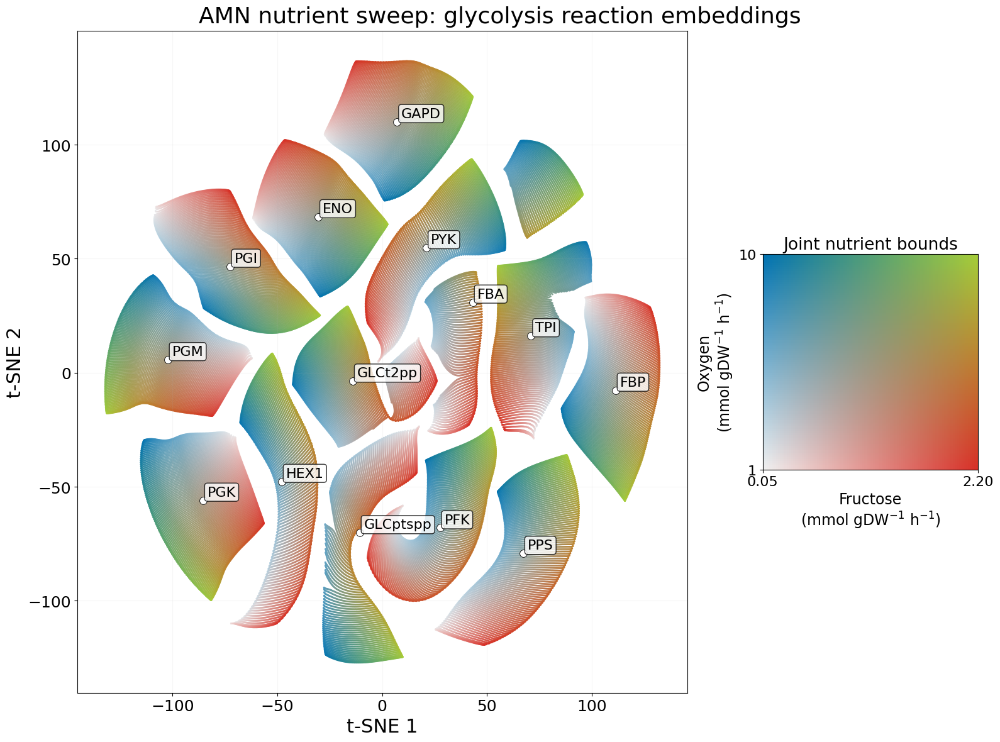

Saved: ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024\A_1M_d256_h8_l4_ff1024_tsne_AMN_sweep_glycolysis_reactions_single_variables.png
Saved: ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024\A_1M_d256_h8_l4_ff1024_tsne_AMN_sweep_glycolysis_reactions_bivariate.png


In [32]:
SWEEP_TSNE_REACTION_SUBSET = "glycolysis_reactions"

sweep_tsne_result = plot_AMN_sweep_tsne(
    model, sweep_outputs, X_sweep, sweep_metadata,
    reaction_subset=SWEEP_TSNE_REACTION_SUBSET,
    pic_dir=pic_dir, model_name=model_name,
    perplexity=40.0, random_state=10, batch_size=128,
    annotate=True, annotate_fontsize=16,
)

Combined sweep/random t-SNE: 11,000 contexts × 14 reactions = 154,000 points


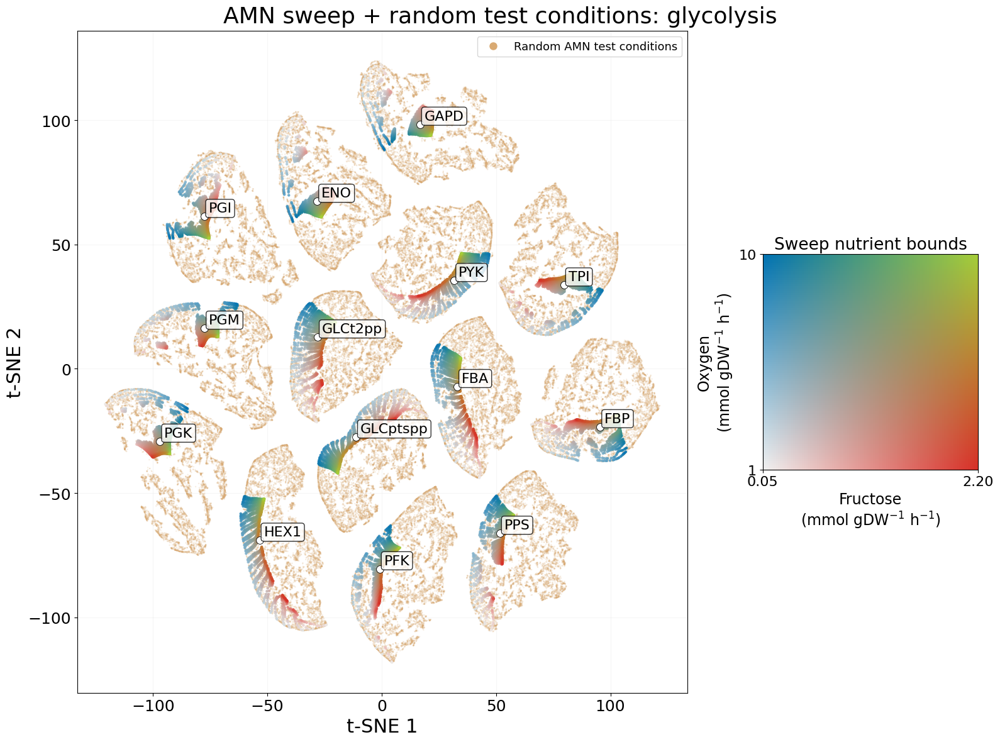

Saved: ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024\A_1M_d256_h8_l4_ff1024_tsne_AMN_sweep_glycolysis_reactions_with_random_bivariate.png


In [33]:
sweep_random_glycolysis_result = plot_AMN_combined_sweep_tsne(
    model, sweep_outputs, X_sweep_combined, X_random_amn, sweep_metadata_combined, random_amn_row_ids,
    reaction_subset="glycolysis_reactions", pic_dir=pic_dir, model_name=model_name,
    perplexity=80.0, random_state=10, batch_size=128,
    annotate=True, annotate_fontsize=16,
)


Combined sweep/random t-SNE: 10,100 contexts × 14 reactions = 141,400 points


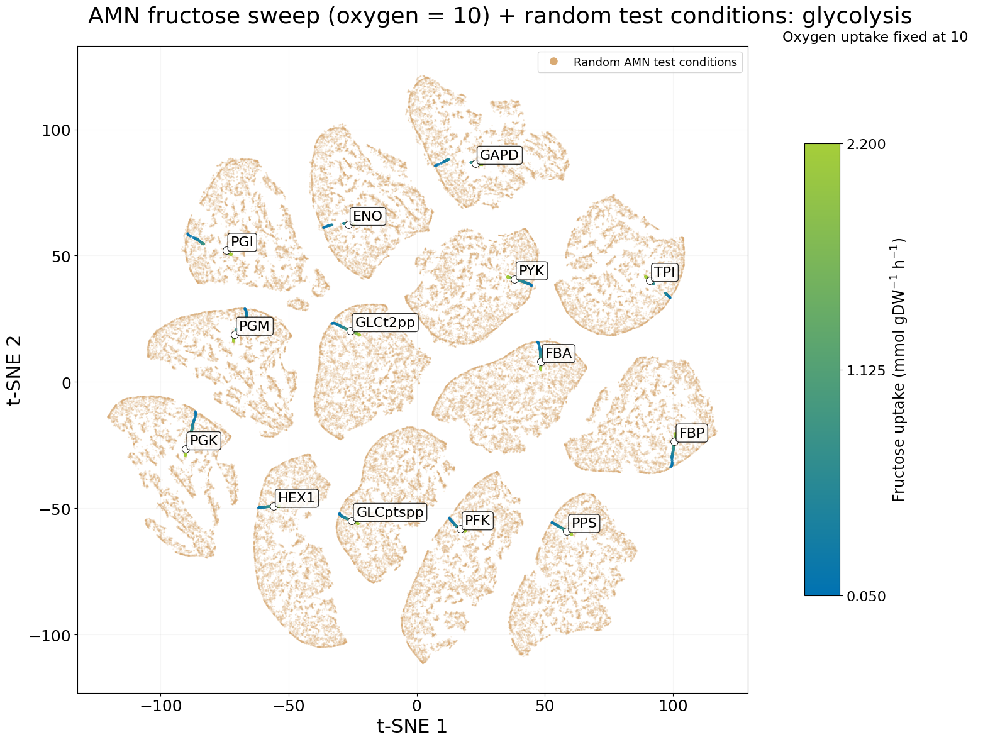

Saved: ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024\A_1M_d256_h8_l4_ff1024_tsne_AMN_sweep_glycolysis_reactions_oxygen10_with_random.png


In [34]:
sweep_random_glycolysis_oxygen10_result = plot_AMN_combined_sweep_tsne(
    model, sweep_outputs, X_sweep_oxygen10, X_random_amn,
    sweep_metadata_oxygen10, random_amn_row_ids,
    reaction_subset="glycolysis_reactions", pic_dir=pic_dir, model_name=model_name,
    perplexity=80.0, random_state=10, batch_size=128,
    annotate=True, annotate_fontsize=16, fixed_oxygen=10.0,
)


Sweep t-SNE: 10,000 contexts × 8 reactions = 80,000 points


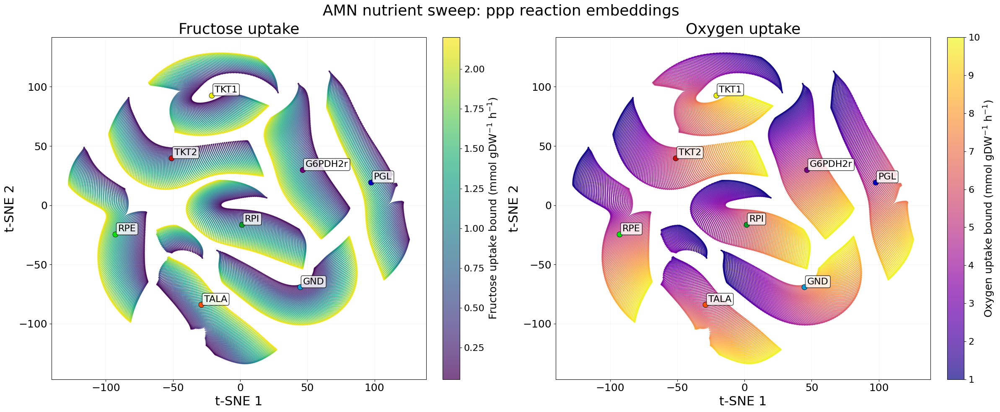

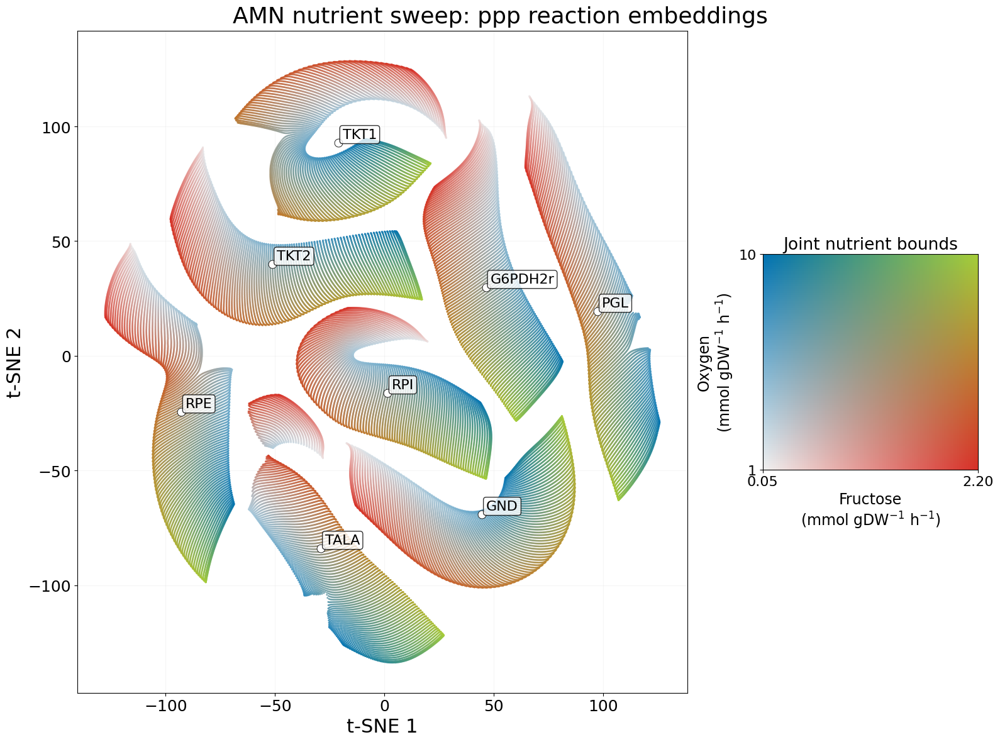

Saved: ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024\A_1M_d256_h8_l4_ff1024_tsne_AMN_sweep_ppp_reactions_single_variables.png
Saved: ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024\A_1M_d256_h8_l4_ff1024_tsne_AMN_sweep_ppp_reactions_bivariate.png


In [35]:
sweep_ppp_tsne_result = plot_AMN_sweep_tsne(
    model, sweep_outputs, X_sweep, sweep_metadata,
    reaction_subset="ppp_reactions",
    pic_dir=pic_dir, model_name=model_name,
    perplexity=40.0, random_state=10, batch_size=128,
    annotate=True, annotate_fontsize=16,
)


Combined sweep/random t-SNE: 11,000 contexts × 8 reactions = 88,000 points


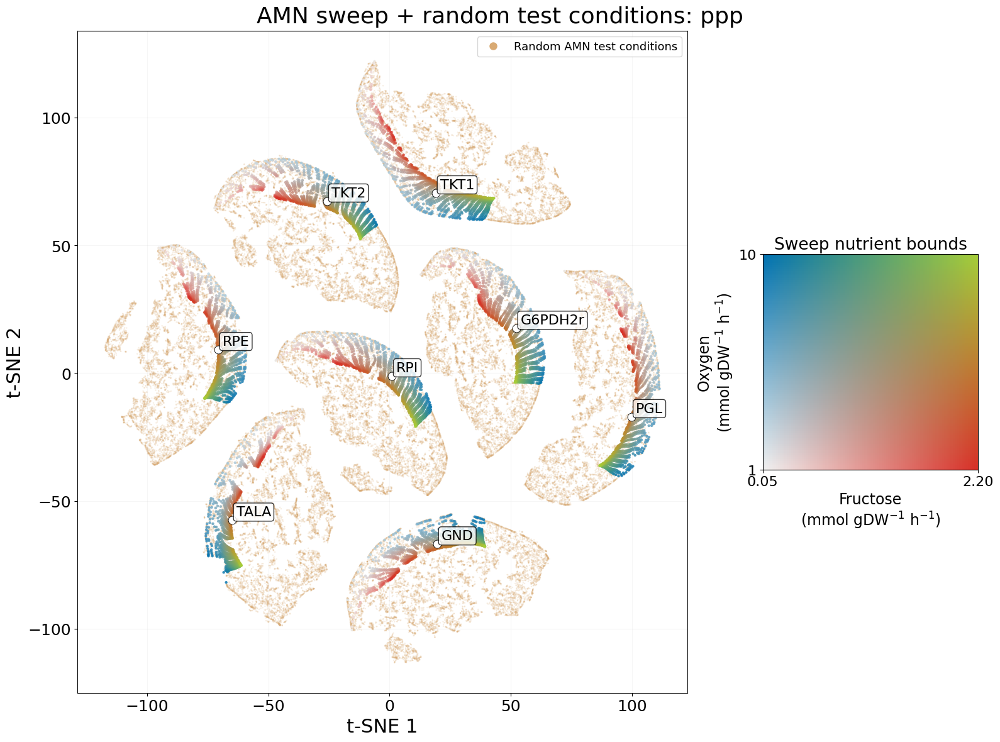

Saved: ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024\A_1M_d256_h8_l4_ff1024_tsne_AMN_sweep_ppp_reactions_with_random_bivariate.png


In [36]:
sweep_random_ppp_result = plot_AMN_combined_sweep_tsne(
    model, sweep_outputs, X_sweep_combined, X_random_amn, sweep_metadata_combined, random_amn_row_ids,
    reaction_subset="ppp_reactions", pic_dir=pic_dir, model_name=model_name,
    perplexity=80.0, random_state=10, batch_size=128,
    annotate=True, annotate_fontsize=16,
)


Combined sweep/random t-SNE: 10,100 contexts × 8 reactions = 80,800 points


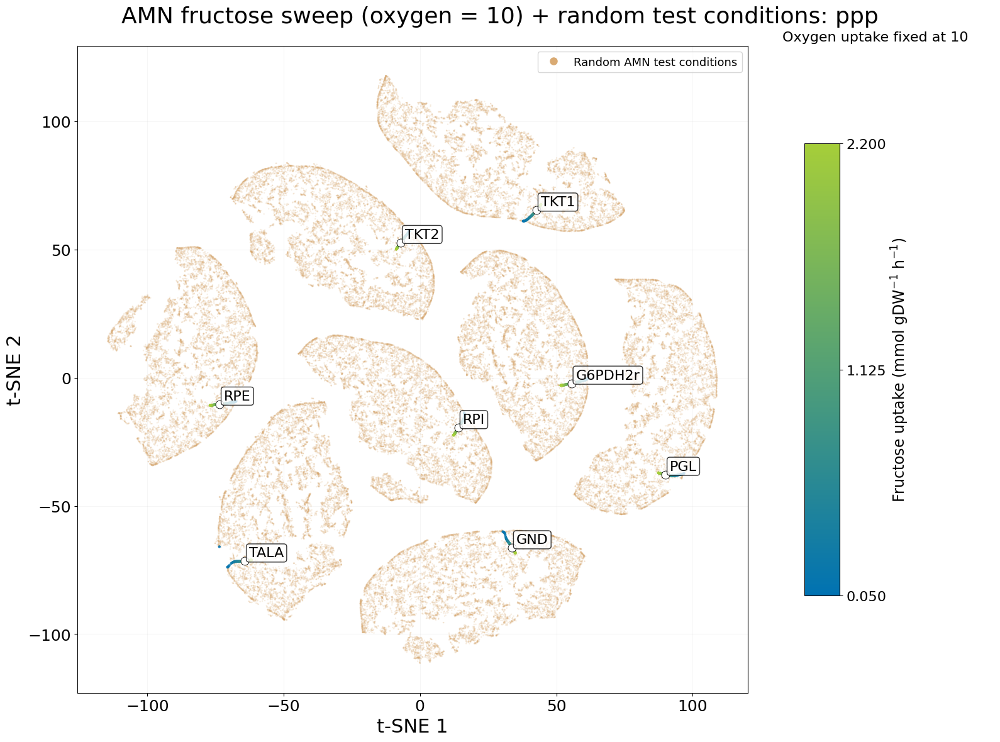

Saved: ./pics/2026-10-22/A_1M_d256_h8_l4_ff1024\A_1M_d256_h8_l4_ff1024_tsne_AMN_sweep_ppp_reactions_oxygen10_with_random.png


In [37]:
sweep_random_ppp_oxygen10_result = plot_AMN_combined_sweep_tsne(
    model, sweep_outputs, X_sweep_oxygen10, X_random_amn,
    sweep_metadata_oxygen10, random_amn_row_ids,
    reaction_subset="ppp_reactions", pic_dir=pic_dir, model_name=model_name,
    perplexity=80.0, random_state=10, batch_size=128,
    annotate=True, annotate_fontsize=16, fixed_oxygen=10.0,
)


### Reservoir Computing on Experimental Data (Frozen FluxTransformer + Prior Dense Net)


In [38]:
from torch.utils.data import TensorDataset, DataLoader

EXP_PATH = "./AMN_data/iML1515_EXP.csv"
GROWTH_TARGET_COL = "GR_AVG"
BIOMASS_TOKEN = "BIOMASS_Ec_iML1515_core_75p37M_flux"

exp_df = pd.read_csv(EXP_PATH).fillna(0.0)

# Normalize experimental column names to match model input names.
# Example: EX_pi_e_i -> EX_pi_e
normalized_cols = {c: c[:-2] if c.endswith("_i") else c for c in exp_df.columns}
exp_df = exp_df.rename(columns=normalized_cols)

OPTIONAL_ABSENT_INPUT_DEFAULTS = {
    # Shared AMN/MINN checkpoints include these MINN-context inputs, but
    # Faure experimental media do not contain glucose or ethanol columns.
    "EX_glc__D_e": 0.0,
    "EX_etoh_e": 0.0,
}
missing_inputs = [c for c in inputs if c not in exp_df.columns]
unknown_missing_inputs = [c for c in missing_inputs if c not in OPTIONAL_ABSENT_INPUT_DEFAULTS]
if unknown_missing_inputs:
    raise ValueError(f"Missing expected input columns in experimental data: {unknown_missing_inputs}")
for c in missing_inputs:
    exp_df[c] = float(OPTIONAL_ABSENT_INPUT_DEFAULTS[c])
if missing_inputs:
    print("Filled optional absent experimental inputs with defaults:")
    print({c: OPTIONAL_ABSENT_INPUT_DEFAULTS[c] for c in missing_inputs})
if GROWTH_TARGET_COL not in exp_df.columns:
    raise ValueError(f"Missing growth target column: {GROWTH_TARGET_COL}")
if BIOMASS_TOKEN not in outputs:
    raise ValueError(f"Biomass token not found in outputs: {BIOMASS_TOKEN}")

# Only variable media are learned by the front ANN, fixed media stay constant.
TRAINABLE_EXTRA_INPUTS = {"EX_o2_e"}  # force oxygen to be trainable with variable carbons
variable_input_cols = [c for c in inputs if (exp_df[c].nunique(dropna=False) > 1) or (c in TRAINABLE_EXTRA_INPUTS)]
fixed_input_cols = [c for c in inputs if c not in variable_input_cols]

if len(variable_input_cols) == 0:
    raise ValueError("No variable input columns found in experimental dataset.")

biomass_idx = outputs.index(BIOMASS_TOKEN)

print(f"Experimental samples: {len(exp_df)}")
print(f"Total media inputs: {len(inputs)}")
print(f"Variable media inputs learned by prior ANN: {len(variable_input_cols)}")
print(f"Fixed media inputs kept constant: {len(fixed_input_cols)}")
print(f"Biomass output token index: {biomass_idx}")

var_pos = torch.tensor([inputs.index(c) for c in variable_input_cols], dtype=torch.long, device=device)
fixed_pos = torch.tensor([inputs.index(c) for c in fixed_input_cols], dtype=torch.long, device=device)
token_idx = torch.tensor(input_token_indices, dtype=torch.long, device=device)

X_var = torch.tensor(exp_df[variable_input_cols].to_numpy(dtype=np.float32), dtype=torch.float32, device=device)
y_growth = torch.tensor(exp_df[GROWTH_TARGET_COL].to_numpy(dtype=np.float32), dtype=torch.float32, device=device)

# Convert fixed presence flags (0/1) into physical bounds, aligned with simulation generator.
BASE_DEFAULT_RATE = 10.0
AMINO_RATE = 2.2
FIXED_SPECIAL_RATES = {
    "EX_glyc_e": AMINO_RATE,
}
AMINO_EXCHANGES = {"EX_ala__L_e", "EX_pro__L_e", "EX_thr__L_e", "EX_gly_e"}

def fixed_presence_to_bound(col_name, presence_value):
    if presence_value <= 0:
        return 0.0
    if col_name in FIXED_SPECIAL_RATES:
        return FIXED_SPECIAL_RATES[col_name]
    if col_name in AMINO_EXCHANGES:
        return AMINO_RATE
    return BASE_DEFAULT_RATE

if len(fixed_input_cols) > 0:
    fixed_presence = exp_df[fixed_input_cols].iloc[0].to_numpy(dtype=np.float32)
    fixed_bound_values = np.array(
        [fixed_presence_to_bound(c, v) for c, v in zip(fixed_input_cols, fixed_presence)],
        dtype=np.float32,
    )
    fixed_values = torch.tensor(fixed_bound_values, dtype=torch.float32, device=device)
else:
    fixed_values = torch.empty(0, dtype=torch.float32, device=device)

print("Variable input columns:")
print(variable_input_cols)
print("Fixed input bounds used (derived from presence flags):")
print({c: float(v) for c, v in zip(fixed_input_cols, fixed_values.detach().cpu().numpy())})

Experimental samples: 110
Total media inputs: 38
Variable media inputs learned by prior ANN: 11
Fixed media inputs kept constant: 27
Biomass output token index: 2668
Variable input columns:
['EX_o2_e', 'EX_rib__D_e', 'EX_malt_e', 'EX_melib_e', 'EX_tre_e', 'EX_fru_e', 'EX_gal_e', 'EX_ac_e', 'EX_lac__D_e', 'EX_succ_e', 'EX_pyr_e']
Fixed input bounds used (derived from presence flags):
{'EX_pi_e': 10.0, 'EX_co2_e': 10.0, 'EX_fe3_e': 10.0, 'EX_h_e': 10.0, 'EX_mn2_e': 10.0, 'EX_fe2_e': 10.0, 'EX_zn2_e': 10.0, 'EX_mg2_e': 10.0, 'EX_ca2_e': 10.0, 'EX_ni2_e': 10.0, 'EX_cu2_e': 10.0, 'EX_sel_e': 10.0, 'EX_cobalt2_e': 10.0, 'EX_h2o_e': 10.0, 'EX_mobd_e': 10.0, 'EX_so4_e': 10.0, 'EX_nh4_e': 10.0, 'EX_k_e': 10.0, 'EX_na1_e': 10.0, 'EX_cl_e': 10.0, 'EX_tungs_e': 10.0, 'EX_slnt_e': 10.0, 'EX_glyc_e': 2.200000047683716, 'EX_ala__L_e': 2.200000047683716, 'EX_pro__L_e': 2.200000047683716, 'EX_thr__L_e': 2.200000047683716, 'EX_gly_e': 2.200000047683716}


In [39]:
class PriorDenseNetwork(nn.Module):
    def __init__(self, in_dim, out_dim, n_hidden=1, hidden_dim=512, activation="relu", out_scale=2.2, dropout=0.25):
        super().__init__()
        if in_dim <= 0 or out_dim <= 0:
            raise ValueError("in_dim and out_dim must be positive.")

        act = nn.ReLU if activation.lower() == "relu" else nn.GELU
        layers = []
        last_dim = in_dim
        for _ in range(n_hidden):
            layers.append(nn.Linear(last_dim, hidden_dim))
            layers.append(act())
            layers.append(nn.Dropout(dropout))
            last_dim = hidden_dim
        layers.append(nn.Linear(last_dim, out_dim))
        self.net = nn.Sequential(*layers)
        out_scale_t = torch.as_tensor(out_scale, dtype=torch.float32)
        if out_scale_t.ndim == 0:
            out_scale_t = out_scale_t.repeat(out_dim)
        elif out_scale_t.ndim == 1 and out_scale_t.numel() == out_dim:
            pass
        else:
            raise ValueError(f"out_scale must be scalar or shape ({out_dim},), got {tuple(out_scale_t.shape)}")
        self.register_buffer("out_scale", out_scale_t.view(1, out_dim), persistent=True)

    def forward(self, x):
        # x is binary presence (0/1) for variable carbon sources.
        # Predict bounded uptake rates and force absent sources to zero.
        mask = (x > 0).float()
        raw = self.net(x)
        rates = torch.sigmoid(raw) * self.out_scale
        return mask * rates


In [40]:
from copy import deepcopy
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch.utils.checkpoint import checkpoint


def compose_full_medium(var_part):
    batch = var_part.size(0)
    full_medium = torch.zeros(batch, len(inputs), dtype=torch.float32, device=var_part.device)
    full_medium[:, var_pos] = var_part
    if fixed_values.numel() > 0:
        full_medium[:, fixed_pos] = fixed_values.unsqueeze(0).expand(batch, -1)
    full_medium = torch.clamp(full_medium, min=0.0)
    return full_medium


def medium_to_reservoir_input(full_medium):
    c = torch.zeros(full_medium.size(0), len(outputs), 1, dtype=torch.float32, device=full_medium.device)
    c[:, token_idx, 0] = full_medium
    return c


def _model_only(inp):
    out, _ = model(inp, output_subset=None)
    return out


def _mean_curve(curves):
    max_len = max(len(c) for c in curves)
    mat = np.full((len(curves), max_len), np.nan, dtype=np.float32)
    for i, c in enumerate(curves):
        arr = np.asarray(c, dtype=np.float32)
        mat[i, :len(arr)] = arr
    return np.nanmean(mat, axis=0).tolist()


def _predict_growth_with_prior(prior_model, X_input, chunk_size):
    pred_parts = []
    for s_idx in range(0, X_input.size(0), chunk_size):
        e_idx = min(s_idx + chunk_size, X_input.size(0))
        xb_val = X_input[s_idx:e_idx]
        pred_var_val = prior_model(xb_val)
        full_medium_val = compose_full_medium(pred_var_val)
        c_val = medium_to_reservoir_input(full_medium_val)
        reservoir_val, _ = model(c_val, output_subset=None)
        pred_parts.append(reservoir_val[:, biomass_idx, -1].detach().cpu())
        if device.type == "cuda":
            torch.cuda.empty_cache()
    return torch.cat(pred_parts, dim=0).numpy()


def train_prior_one_seed(
    seed,
    X_train_var,
    y_train_growth,
    X_val_var,
    y_val_growth,
    train_batch_size,
    val_batch_size,
    run_prefix,
    return_model=False,
):
    set_seed(seed)

    prior_net_seed = PriorDenseNetwork(
        in_dim=len(variable_input_cols),
        out_dim=len(variable_input_cols),
        n_hidden=1,
        hidden_dim=hidden_dim,
        activation="relu",
        out_scale=out_scale_vec,
        dropout=dropout,
    ).to(device)

    optimizer_seed = torch.optim.AdamW(prior_net_seed.parameters(), lr=1e-3, weight_decay=1e-3)
    criterion_seed = nn.HuberLoss(delta=0.03)
    train_loader_seed = DataLoader(
        TensorDataset(X_train_var, y_train_growth),
        batch_size=train_batch_size,
        shuffle=True,
    )

    train_losses_seed = []
    val_losses_seed = []
    best_val_seed = float("inf")
    best_state_seed = None
    best_epoch_seed = 0
    no_improve_seed = 0

    for epoch in range(num_epochs):
        prior_net_seed.train()
        running = 0.0

        for xb_var, yb in train_loader_seed:
            optimizer_seed.zero_grad(set_to_none=True)

            pred_var = prior_net_seed(xb_var)
            full_medium = compose_full_medium(pred_var)
            c_in = medium_to_reservoir_input(full_medium)

            reservoir_out = checkpoint(_model_only, c_in, use_reentrant=False)
            y_pred = reservoir_out[:, biomass_idx, -1]
            loss = criterion_seed(y_pred, yb)

            loss.backward()
            optimizer_seed.step()
            running += loss.item() * xb_var.size(0)

            if device.type == "cuda":
                torch.cuda.empty_cache()

        epoch_train = running / max(1, X_train_var.size(0))
        train_losses_seed.append(epoch_train)

        prior_net_seed.eval()
        with torch.no_grad():
            if device.type == "cuda":
                torch.cuda.empty_cache()

            val_running = 0.0
            val_count = 0
            for s_idx in range(0, X_val_var.size(0), val_batch_size):
                e_idx = min(s_idx + val_batch_size, X_val_var.size(0))
                xb_val = X_val_var[s_idx:e_idx]
                yb_val = y_val_growth[s_idx:e_idx]

                pred_var_val = prior_net_seed(xb_val)
                full_medium_val = compose_full_medium(pred_var_val)
                c_val = medium_to_reservoir_input(full_medium_val)
                reservoir_val, _ = model(c_val, output_subset=None)
                y_val_pred = reservoir_val[:, biomass_idx, -1]

                batch_loss = criterion_seed(y_val_pred, yb_val)
                val_running += batch_loss.item() * xb_val.size(0)
                val_count += xb_val.size(0)

                if device.type == "cuda":
                    torch.cuda.empty_cache()

            epoch_val = val_running / max(1, val_count)
            val_losses_seed.append(epoch_val)

        if epoch_val < best_val_seed:
            best_val_seed = epoch_val
            best_state_seed = deepcopy(prior_net_seed.state_dict())
            best_epoch_seed = epoch + 1
            no_improve_seed = 0
        else:
            no_improve_seed += 1

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(
                f"{run_prefix} seed={seed} | Epoch {epoch+1:>3}/{num_epochs} | "
                f"train_huber={epoch_train:.6f} | val_huber={epoch_val:.6f} | no_improve={no_improve_seed}"
            )

        if no_improve_seed >= patience:
            print(
                f"{run_prefix} seed={seed} early stop at epoch {epoch+1} "
                f"(best_epoch={best_epoch_seed}, best_val={best_val_seed:.6f})"
            )
            break

    if best_state_seed is None:
        best_state_seed = deepcopy(prior_net_seed.state_dict())

    prior_net_seed.load_state_dict(best_state_seed)
    prior_net_seed.eval()

    with torch.no_grad():
        y_val_pred_seed = _predict_growth_with_prior(prior_net_seed, X_val_var, val_batch_size)
        vin_val_seed = compose_full_medium(prior_net_seed(X_val_var)).detach().cpu().numpy()

    result = {
        "seed": int(seed),
        "best_val": float(best_val_seed),
        "best_epoch": int(best_epoch_seed),
        "train_losses": train_losses_seed,
        "val_losses": val_losses_seed,
        "y_val_pred": y_val_pred_seed,
        "vin_val": vin_val_seed,
        "train_batch_used": int(train_batch_size),
        "val_batch_used": int(val_batch_size),
    }

    if return_model:
        result["model"] = prior_net_seed
    else:
        del prior_net_seed

    del optimizer_seed, train_loader_seed
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return result


def train_prior_one_seed_with_fallback(
    seed,
    X_train_var,
    y_train_growth,
    X_val_var,
    y_val_growth,
    run_prefix,
    return_model=False,
):
    train_batch_try = max(1, min(batch_size, X_train_var.size(0)))
    val_batch_try = max(1, min(val_batch, X_val_var.size(0)))

    while True:
        try:
            return train_prior_one_seed(
                seed=seed,
                X_train_var=X_train_var,
                y_train_growth=y_train_growth,
                X_val_var=X_val_var,
                y_val_growth=y_val_growth,
                train_batch_size=train_batch_try,
                val_batch_size=val_batch_try,
                run_prefix=run_prefix,
                return_model=return_model,
            )
        except RuntimeError as err:
            err_msg = str(err).lower()
            is_oom = "out of memory" in err_msg
            if device.type == "cuda" and is_oom and train_batch_try > 1:
                print(
                    f"{run_prefix} seed={seed} CUDA OOM at batch_size={train_batch_try}; "
                    "retrying with batch_size=1."
                )
                train_batch_try = 1
                val_batch_try = 1
                torch.cuda.empty_cache()
                continue
            raise


# Freeze FluxTransformer parameters and keep deterministic behavior.
for p in model.parameters():
    p.requires_grad = False
model.eval()

set_seed(10)
n_samples = X_var.size(0)
if n_samples < 10:
    raise ValueError("Need at least 10 samples for 10-fold stratified validation.")

CARBON_SOURCE_COLS = [
    "EX_rib__D_e",
    "EX_malt_e",
    "EX_melib_e",
    "EX_tre_e",
    "EX_fru_e",
    "EX_gal_e",
    "EX_ac_e",
    "EX_lac__D_e",
    "EX_succ_e",
    "EX_pyr_e",
]
missing_carbon_cols = [c for c in CARBON_SOURCE_COLS if c not in exp_df.columns]
if missing_carbon_cols:
    raise ValueError(f"Missing required carbon source columns for stratification: {missing_carbon_cols}")

stratify_y = exp_df[CARBON_SOURCE_COLS].gt(0).sum(axis=1).to_numpy(dtype=np.int64)
if np.any((stratify_y < 1) | (stratify_y > 4)):
    raise ValueError("Experimental strata must be carbon-source counts in {1,2,3,4}.")

exp110_df = pd.read_csv("AMN_data/EXP110.csv")
if "GR_STD" not in exp110_df.columns:
    raise ValueError("EXP110.csv must contain GR_STD column.")
y_std_all = exp110_df["GR_STD"].to_numpy(dtype=np.float32)
if y_std_all.shape[0] != n_samples:
    raise ValueError("EXP110.csv GR_STD length must match number of samples used in training.")

n_splits = 10
cv_split_seeds = [10, 11, 12]
prior_train_seed = 10

strata_counts = np.bincount(stratify_y, minlength=5)[1:5]
if np.min(strata_counts) < n_splits:
    raise ValueError("Each carbon-source-count stratum must have at least 10 samples for 10-fold stratified CV.")
print("Stratification counts (1,2,3,4 carbons):", strata_counts.tolist())

num_epochs = 100
hidden_dim = 512
dropout = 0.0
batch_size = 1
val_batch = 2
patience = 15
ensemble_seeds = [10, 11, 12]  # final full-data ensemble fit only

out_scale_vec = np.array([10.0 if c == "EX_o2_e" else 2.2 for c in variable_input_cols], dtype=np.float32)
print(
    f"Training config | epochs={num_epochs} | patience={patience} | base_batch={batch_size} | "
    f"cv_split_seeds={cv_split_seeds} | prior_train_seed={prior_train_seed}"
)

fold_summaries = []
oof_true_parts = []
oof_pred_parts = []
oof_fold_parts = []
oof_std_parts = []
oof_idx_parts = []
oof_seed_parts = []
oof_vin_parts = []

for split_seed in cv_split_seeds:
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=split_seed)

    for fold_local_id, (tr_np, va_np) in enumerate(skf.split(np.arange(n_samples), stratify_y), start=1):
        train_idx = torch.tensor(tr_np, dtype=torch.long, device=device)
        val_idx = torch.tensor(va_np, dtype=torch.long, device=device)

        X_train_var = X_var[train_idx]
        y_train_growth = y_growth[train_idx]
        X_val_var = X_var[val_idx]
        y_val_growth = y_growth[val_idx]

        seed_result = train_prior_one_seed_with_fallback(
            seed=prior_train_seed,
            X_train_var=X_train_var,
            y_train_growth=y_train_growth,
            X_val_var=X_val_var,
            y_val_growth=y_val_growth,
            run_prefix=f"CV seed {split_seed} fold {fold_local_id}/{n_splits}",
            return_model=False,
        )

        y_val_true_fold = y_val_growth.detach().cpu().numpy()
        y_val_pred_fold = seed_result["y_val_pred"]
        vin_val_fold = seed_result["vin_val"]
        if vin_val_fold.shape != (len(va_np), len(inputs)):
            raise ValueError("Held-out Vin shape does not match validation rows and input exchanges.")

        fold_r2 = r2_score(y_val_true_fold, y_val_pred_fold)
        fold_mae = mean_absolute_error(y_val_true_fold, y_val_pred_fold)
        fold_mse = float(np.mean((y_val_true_fold - y_val_pred_fold) ** 2))

        oof_true_parts.append(y_val_true_fold)
        oof_pred_parts.append(y_val_pred_fold)
        oof_fold_parts.append(np.full(y_val_true_fold.shape[0], fold_local_id, dtype=np.int32))
        oof_std_parts.append(y_std_all[va_np])
        oof_idx_parts.append(va_np.astype(np.int32))
        oof_seed_parts.append(np.full(len(va_np), split_seed, dtype=np.int32))
        oof_vin_parts.append(vin_val_fold)

        fold_summaries.append({
            "cv_seed": int(split_seed),
            "fold": int(fold_local_id),
            "best_val": float(seed_result["best_val"]),
            "best_epoch": int(seed_result["best_epoch"]),
            "train_losses": seed_result["train_losses"],
            "val_losses": seed_result["val_losses"],
            "r2": float(fold_r2),
            "mae": float(fold_mae),
            "mse": float(fold_mse),
            "y_val_true": y_val_true_fold.tolist(),
            "y_val_pred": y_val_pred_fold.tolist(),
            "train_seed": int(prior_train_seed),
            "train_batch_used": int(seed_result["train_batch_used"]),
            "val_batch_used": int(seed_result["val_batch_used"]),
        })

        print(
            f"cv_seed={split_seed} fold={fold_local_id:>2d} | "
            f"R2={fold_r2:.4f} | MAE={fold_mae:.6f} | MSE={fold_mse:.6f} | "
            f"best_val={seed_result['best_val']:.6f}"
        )

        if device.type == "cuda":
            torch.cuda.empty_cache()

oof_true_cv_raw = np.concatenate(oof_true_parts, axis=0)
oof_pred_cv_raw = np.concatenate(oof_pred_parts, axis=0)
oof_fold_cv_raw = np.concatenate(oof_fold_parts, axis=0)
oof_std_cv_raw = np.concatenate(oof_std_parts, axis=0)
oof_idx_cv_raw = np.concatenate(oof_idx_parts, axis=0)
oof_seed_cv_raw = np.concatenate(oof_seed_parts, axis=0)
oof_vin_cv_raw = np.concatenate(oof_vin_parts, axis=0)
if oof_vin_cv_raw.shape != (len(oof_idx_cv_raw), len(inputs)) or not np.isfinite(oof_vin_cv_raw).all():
    raise ValueError("Held-out Vin values are missing, misaligned or nonfinite.")

# Aggregate repeated-CV predictions so each experimental sample contributes one OOF dot.
pred_sum = np.zeros(n_samples, dtype=np.float64)
pred_sumsq = np.zeros(n_samples, dtype=np.float64)
pred_count = np.zeros(n_samples, dtype=np.int32)
oof_true_per_sample = np.full(n_samples, np.nan, dtype=np.float32)
oof_std_per_sample = np.full(n_samples, np.nan, dtype=np.float32)
oof_fold_per_sample = np.full(n_samples, -1, dtype=np.int32)

for idx_i, y_t, y_p, f_i, y_s in zip(oof_idx_cv_raw, oof_true_cv_raw, oof_pred_cv_raw, oof_fold_cv_raw, oof_std_cv_raw):
    idx_i = int(idx_i)
    pred_sum[idx_i] += float(y_p)
    pred_sumsq[idx_i] += float(y_p) ** 2
    pred_count[idx_i] += 1
    if np.isnan(oof_true_per_sample[idx_i]):
        oof_true_per_sample[idx_i] = float(y_t)
        oof_std_per_sample[idx_i] = float(y_s)
    if oof_fold_per_sample[idx_i] < 0:
        oof_fold_per_sample[idx_i] = int(f_i)

expected_count = len(cv_split_seeds)
if not np.all(pred_count == expected_count):
    uniq_counts, uniq_freq = np.unique(pred_count, return_counts=True)
    raise ValueError(
        f"Repeated-CV aggregation error: expected each sample to have {expected_count} predictions, "
        f"but got counts {dict(zip(uniq_counts.tolist(), uniq_freq.tolist()))}."
    )

oof_pred_mean = pred_sum / pred_count
oof_pred_cv = oof_pred_mean.astype(np.float32)
oof_pred_seed_var_cv = (pred_sumsq - pred_count * oof_pred_mean ** 2) / np.maximum(1, pred_count - 1)
oof_pred_seed_std_cv = np.sqrt(np.maximum(0.0, oof_pred_seed_var_cv)).astype(np.float32)
oof_true_cv = oof_true_per_sample.astype(np.float32)
oof_std_cv = oof_std_per_sample.astype(np.float32)
oof_fold_cv = oof_fold_per_sample.astype(np.int32)

best_vals = np.array([f["best_val"] for f in fold_summaries], dtype=np.float32)
cv_r2 = np.array([f["r2"] for f in fold_summaries], dtype=np.float32)
cv_mae = np.array([f["mae"] for f in fold_summaries], dtype=np.float32)
cv_mse = np.array([f["mse"] for f in fold_summaries], dtype=np.float32)
cv_r2_mean, cv_r2_std = float(cv_r2.mean()), float(cv_r2.std(ddof=0))
cv_mae_mean, cv_mae_std = float(cv_mae.mean()), float(cv_mae.std(ddof=0))
cv_mse_mean, cv_mse_std = float(cv_mse.mean()), float(cv_mse.std(ddof=0))
print("Repeated stratified K-fold summary")
print(
    f"n_splits={n_splits} | n_repeat_seeds={len(cv_split_seeds)} | total_fits={len(fold_summaries)} | "
    f"mean_best_val={best_vals.mean():.6f} | std_best_val={best_vals.std(ddof=0):.6f}"
)
print(f"CV R2 : {cv_r2_mean:.4f} +/- {cv_r2_std:.4f}")
print(f"CV MAE: {cv_mae_mean:.6f} +/- {cv_mae_std:.6f}")
print(f"CV MSE: {cv_mse_mean:.6f} +/- {cv_mse_std:.6f}")
for f in fold_summaries:
    print(
        f"cv_seed={f['cv_seed']} fold={f['fold']} best_epoch~{f['best_epoch']} "
        f"best_val={f['best_val']:.6f} r2={f['r2']:.4f} mae={f['mae']:.6f} mse={f['mse']:.6f}"
    )

# Train final prior-net ensemble with an internal stratified split and early stopping.
full_train_np, full_val_np = train_test_split(
    np.arange(n_samples),
    test_size=0.1,
    random_state=10,
    stratify=stratify_y,
    shuffle=True,
)
full_train_idx = torch.tensor(full_train_np, dtype=torch.long, device=device)
full_val_idx = torch.tensor(full_val_np, dtype=torch.long, device=device)

X_full_train_var = X_var[full_train_idx]
y_full_train_growth = y_growth[full_train_idx]
X_full_val_var = X_var[full_val_idx]
y_full_val_growth = y_growth[full_val_idx]

full_seed_results = []
for seed in ensemble_seeds:
    seed_result = train_prior_one_seed_with_fallback(
        seed=seed,
        X_train_var=X_full_train_var,
        y_train_growth=y_full_train_growth,
        X_val_var=X_full_val_var,
        y_val_growth=y_full_val_growth,
        run_prefix="Full fit",
        return_model=True,
    )
    full_seed_results.append(seed_result)

prior_net_ensemble = [r["model"] for r in full_seed_results]
for net in prior_net_ensemble:
    net.eval()

# Backward-compatible handle for downstream cells that expect a single model object.
prior_net = prior_net_ensemble[0]


def prior_net_predict_var_ensemble(X_input, infer_batch=None, model_list=None):
    models = prior_net_ensemble if model_list is None else model_list
    if len(models) == 0:
        raise ValueError("No models available in prior_net_ensemble.")

    if infer_batch is None:
        infer_batch = max(1, min(val_batch, X_input.size(0)))

    pred_parts = []
    with torch.no_grad():
        for s_idx in range(0, X_input.size(0), infer_batch):
            e_idx = min(s_idx + infer_batch, X_input.size(0))
            xb = X_input[s_idx:e_idx]
            pred_sum = torch.zeros(xb.size(0), len(variable_input_cols), dtype=torch.float32, device=xb.device)
            for net in models:
                pred_sum += net(xb)
            pred_parts.append(pred_sum / float(len(models)))
            if device.type == "cuda":
                torch.cuda.empty_cache()

    return torch.cat(pred_parts, dim=0)


train_losses_prior = _mean_curve([r["train_losses"] for r in full_seed_results])
val_losses_prior = _mean_curve([r["val_losses"] for r in full_seed_results])
full_best_val = float(np.mean([r["best_val"] for r in full_seed_results]))
full_best_epoch = int(round(np.mean([r["best_epoch"] for r in full_seed_results])))

full_seed_summaries = [
    {
        "seed": int(r["seed"]),
        "best_val": float(r["best_val"]),
        "best_epoch": int(r["best_epoch"]),
        "train_batch_used": int(r["train_batch_used"]),
        "val_batch_used": int(r["val_batch_used"]),
    }
    for r in full_seed_results
]

print("Final ensemble summary")
print(
    f"seeds={ensemble_seeds} | mean_best_val={full_best_val:.6f} | "
    f"std_best_val={np.std([r['best_val'] for r in full_seed_results], ddof=0):.6f} | "
    f"mean_best_epoch={full_best_epoch}"
)
for s in full_seed_summaries:
    print(
        f"seed={s['seed']} best_epoch={s['best_epoch']} best_val={s['best_val']:.6f} "
        f"train_batch={s['train_batch_used']} val_batch={s['val_batch_used']}"
    )



Stratification counts (1,2,3,4 carbons): [10, 20, 40, 40]
Training config | epochs=100 | patience=15 | base_batch=1 | cv_split_seeds=[10, 11, 12] | prior_train_seed=10
CV seed 10 fold 1/10 seed=10 | Epoch   1/100 | train_huber=0.000875 | val_huber=0.000336 | no_improve=0
CV seed 10 fold 1/10 seed=10 | Epoch  10/100 | train_huber=0.000190 | val_huber=0.000265 | no_improve=3
CV seed 10 fold 1/10 seed=10 | Epoch  20/100 | train_huber=0.000084 | val_huber=0.000299 | no_improve=13
CV seed 10 fold 1/10 seed=10 early stop at epoch 22 (best_epoch=7, best_val=0.000088)
cv_seed=10 fold= 1 | R2=0.9821 | MAE=0.011343 | MSE=0.000177 | best_val=0.000088
CV seed 10 fold 2/10 seed=10 | Epoch   1/100 | train_huber=0.000833 | val_huber=0.000846 | no_improve=0
CV seed 10 fold 2/10 seed=10 | Epoch  10/100 | train_huber=0.000169 | val_huber=0.000232 | no_improve=0
CV seed 10 fold 2/10 seed=10 | Epoch  20/100 | train_huber=0.000040 | val_huber=0.000326 | no_improve=1
CV seed 10 fold 2/10 seed=10 | Epoch  30

In-sample prior model fit on full experimental set (ensemble, n=3)
R2:  0.9790
MAE: 0.007697
MSE: 0.000150

Cross-validated performance:
R2 : 0.8168 +/- 0.1571
MAE: 0.024478 +/- 0.006364
MSE: 0.001009 +/- 0.000445


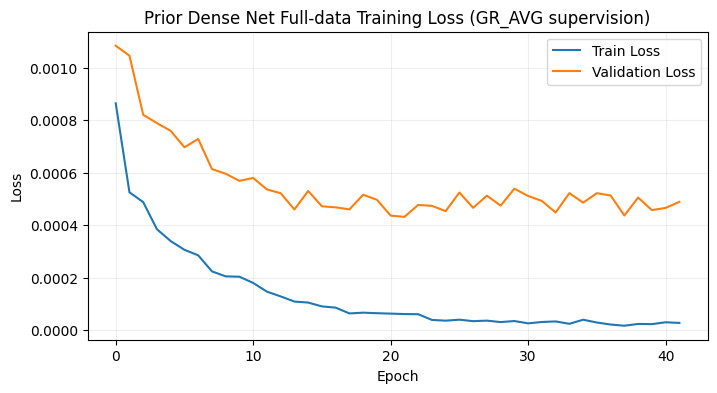

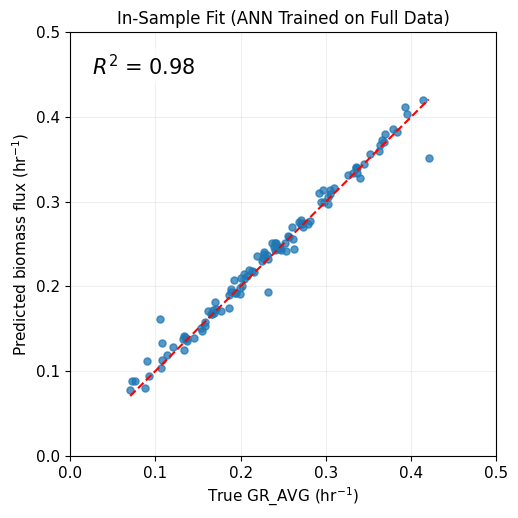

Saved figure to: C:\Users\truok\projects\metabolic-NN\insights\thesis\iML1515_insample_fit.png


In [41]:
with torch.no_grad():
    pred_var_all = prior_net_predict_var_ensemble(X_var, infer_batch=1)
    full_medium_all = compose_full_medium(pred_var_all)

    infer_batch = 1
    pred_parts = []
    for s_idx in range(0, full_medium_all.size(0), infer_batch):
        e_idx = min(s_idx + infer_batch, full_medium_all.size(0))
        c_all = medium_to_reservoir_input(full_medium_all[s_idx:e_idx])
        reservoir_all, _ = model(c_all, output_subset=None)
        pred_parts.append(reservoir_all[:, biomass_idx, -1].detach().cpu())
        if device.type == "cuda":
            torch.cuda.empty_cache()

    y_pred_all = torch.cat(pred_parts, dim=0).numpy()

y_true_all = y_growth.detach().cpu().numpy()
r2_growth = r2_score(y_true_all, y_pred_all)
mae_growth = mean_absolute_error(y_true_all, y_pred_all)
mse_growth = np.mean((y_true_all - y_pred_all) ** 2)

print(f"In-sample prior model fit on full experimental set (ensemble, n={len(prior_net_ensemble)})")
print(f"R2:  {r2_growth:.4f}")
print(f"MAE: {mae_growth:.6f}")
print(f"MSE: {mse_growth:.6f}")
if "cv_r2_mean" in globals():
    print("\nCross-validated performance:")
    print(f"R2 : {cv_r2_mean:.4f} +/- {cv_r2_std:.4f}")
    print(f"MAE: {cv_mae_mean:.6f} +/- {cv_mae_std:.6f}")
    print(f"MSE: {cv_mse_mean:.6f} +/- {cv_mse_std:.6f}")

plt.figure(figsize=(8, 4))
plt.plot(train_losses_prior, label="Train Loss")
if len(val_losses_prior) > 0:
    plt.plot(val_losses_prior, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Prior Dense Net Full-data Training Loss (GR_AVG supervision)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_true_all, y_pred_all, alpha=0.75, s=26)
line_min_v = float(max(0.0, min(y_true_all.min(), y_pred_all.min())))
line_max_v = float(min(0.5, max(y_true_all.max(), y_pred_all.max())))
plt.plot([line_min_v, line_max_v], [line_min_v, line_max_v], "r--", lw=1.5, label="Ideal")
plt.xlabel(r"True GR_AVG (hr$^{-1}$)", fontsize=11)
plt.ylabel(r"Predicted biomass flux (hr$^{-1}$)", fontsize=11)
plt.title("In-Sample Fit (ANN Trained on Full Data)")
plt.xlim(0.0, 0.5)
plt.ylim(0.0, 0.5)
plt.text(0.05, 0.95, rf"$R^2$ = {r2_growth:.2f}", transform=plt.gca().transAxes,
         ha="left", va="top", fontsize=15,
         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.75))
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
#plt.legend()
plt.grid(alpha=0.2)

from pathlib import Path
out_dir = Path("./insights/thesis")
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "iML1515_insample_fit.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {out_path.resolve()}")


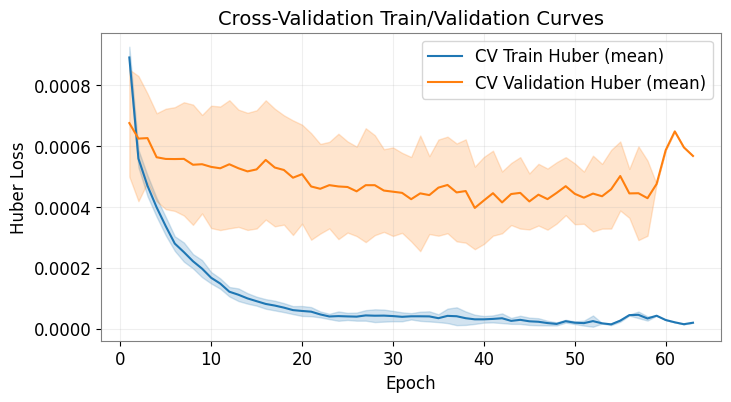


Per-fold CV metrics:
cv_seed=10 fold= 1 | R2=0.9821 | MAE=0.011343 | MSE=0.000177
cv_seed=10 fold= 2 | R2=0.9638 | MAE=0.016733 | MSE=0.000388
cv_seed=10 fold= 3 | R2=0.9215 | MAE=0.018241 | MSE=0.000542
cv_seed=10 fold= 4 | R2=0.9030 | MAE=0.027756 | MSE=0.001204
cv_seed=10 fold= 5 | R2=0.6359 | MAE=0.024263 | MSE=0.001278
cv_seed=10 fold= 6 | R2=0.8412 | MAE=0.018987 | MSE=0.000683
cv_seed=10 fold= 7 | R2=0.6640 | MAE=0.033726 | MSE=0.001616
cv_seed=10 fold= 8 | R2=0.7837 | MAE=0.031109 | MSE=0.001227
cv_seed=10 fold= 9 | R2=0.7312 | MAE=0.022417 | MSE=0.000844
cv_seed=10 fold=10 | R2=0.8042 | MAE=0.031436 | MSE=0.001485
cv_seed=11 fold= 1 | R2=0.9370 | MAE=0.014517 | MSE=0.000292
cv_seed=11 fold= 2 | R2=0.9115 | MAE=0.019195 | MSE=0.000805
cv_seed=11 fold= 3 | R2=0.8239 | MAE=0.023035 | MSE=0.001070
cv_seed=11 fold= 4 | R2=0.8458 | MAE=0.031813 | MSE=0.001227
cv_seed=11 fold= 5 | R2=0.8476 | MAE=0.026214 | MSE=0.001290
cv_seed=11 fold= 6 | R2=0.9536 | MAE=0.013608 | MSE=0.000245
cv

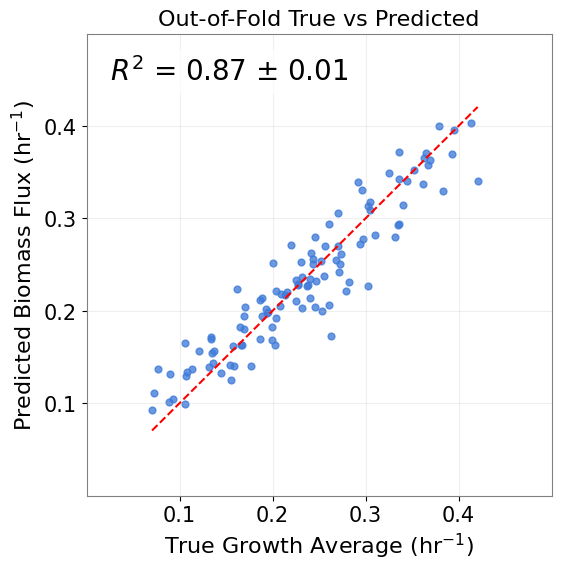

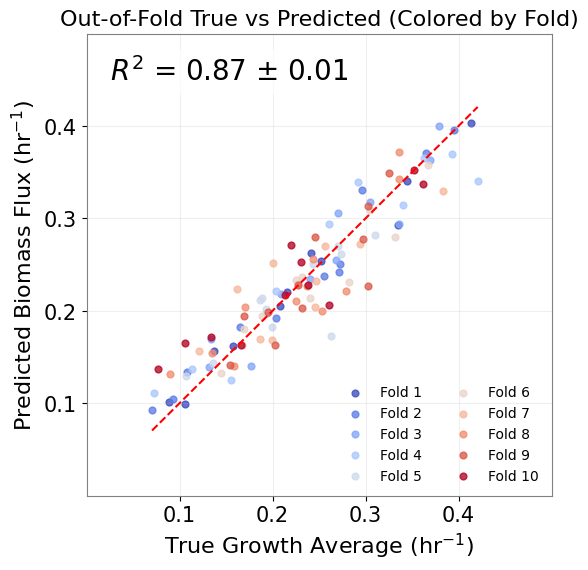

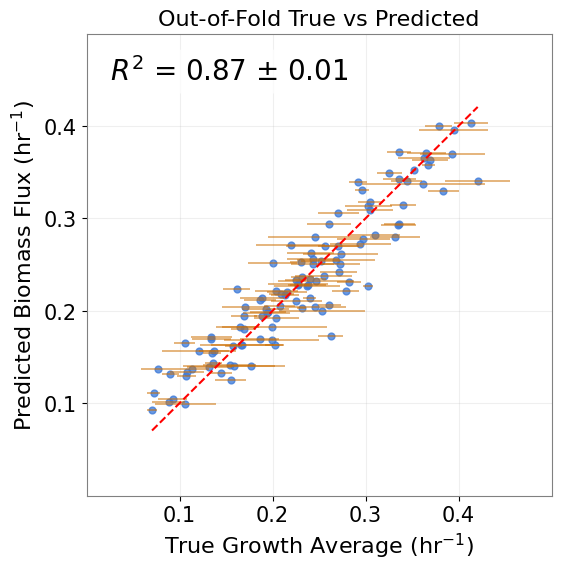

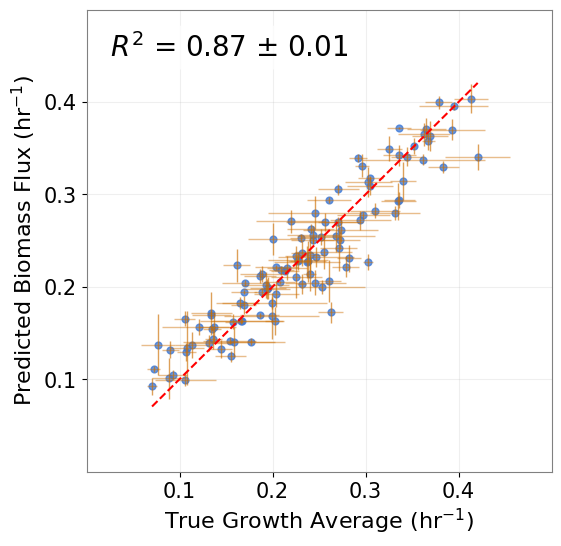

In [42]:
# CV diagnostics: mean train/validation curves, OOF scatter, and best-fold scatter
train_curves_cv = [np.array(f["train_losses"], dtype=np.float32) for f in fold_summaries]
val_curves_cv = [np.array(f["val_losses"], dtype=np.float32) for f in fold_summaries]

max_len_cv = max(len(c) for c in train_curves_cv)
train_mat_cv = np.full((len(train_curves_cv), max_len_cv), np.nan, dtype=np.float32)
val_mat_cv = np.full((len(val_curves_cv), max_len_cv), np.nan, dtype=np.float32)

for i, c in enumerate(train_curves_cv):
    train_mat_cv[i, :len(c)] = c
for i, c in enumerate(val_curves_cv):
    val_mat_cv[i, :len(c)] = c

epochs_cv = np.arange(1, max_len_cv + 1)
train_mean_cv = np.nanmean(train_mat_cv, axis=0)
train_std_cv = np.nanstd(train_mat_cv, axis=0)
val_mean_cv = np.nanmean(val_mat_cv, axis=0)
val_std_cv = np.nanstd(val_mat_cv, axis=0)

plt.figure(figsize=(8, 4))
plt.plot(epochs_cv, train_mean_cv, label="CV Train Huber (mean)", color="tab:blue")
plt.fill_between(epochs_cv, train_mean_cv - train_std_cv, train_mean_cv + train_std_cv, alpha=0.2, color="tab:blue")
plt.plot(epochs_cv, val_mean_cv, label="CV Validation Huber (mean)", color="tab:orange")
plt.fill_between(epochs_cv, val_mean_cv - val_std_cv, val_mean_cv + val_std_cv, alpha=0.2, color="tab:orange")
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Huber Loss", fontsize=12)
plt.title("Cross-Validation Train/Validation Curves", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.grid(alpha=0.2)
plt.show()

# Per-fold metrics
print("\nPer-fold CV metrics:")
for f in fold_summaries:
    print(
        f"cv_seed={f['cv_seed']} fold={f['fold']:>2d} | "
        f"R2={f['r2']:.4f} | MAE={f['mae']:.6f} | MSE={f['mse']:.6f}"
    )

# Pooled OOF metric (aggregated across repeated split seeds)
r2_oof = r2_score(oof_true_cv, oof_pred_cv)
mae_oof = mean_absolute_error(oof_true_cv, oof_pred_cv)
rmse_oof = np.sqrt(np.mean((oof_true_cv - oof_pred_cv) ** 2))
# Std across split seeds: compute pooled OOF metric per seed, then std over seeds.
r2_seed_vals = []
mae_seed_vals = []
rmse_seed_vals = []
for seed_i in cv_split_seeds:
    y_true_seed_parts = []
    y_pred_seed_parts = []
    for f in fold_summaries:
        if f["cv_seed"] == seed_i:
            y_true_seed_parts.append(np.array(f["y_val_true"], dtype=np.float32))
            y_pred_seed_parts.append(np.array(f["y_val_pred"], dtype=np.float32))

    y_true_seed = np.concatenate(y_true_seed_parts, axis=0)
    y_pred_seed = np.concatenate(y_pred_seed_parts, axis=0)
    if y_true_seed.shape[0] != n_samples:
        raise ValueError(
            f"Expected {n_samples} pooled OOF samples for cv_seed={seed_i}, got {y_true_seed.shape[0]}."
        )

    r2_seed_vals.append(r2_score(y_true_seed, y_pred_seed))
    mae_seed_vals.append(mean_absolute_error(y_true_seed, y_pred_seed))
    rmse_seed_vals.append(np.sqrt(np.mean((y_true_seed - y_pred_seed) ** 2)))

r2_seed_vals = np.array(r2_seed_vals, dtype=np.float32)
mae_seed_vals = np.array(mae_seed_vals, dtype=np.float32)
rmse_seed_vals = np.array(rmse_seed_vals, dtype=np.float32)
r2_oof_std = float(np.std(r2_seed_vals, ddof=0))
mae_oof_std = float(np.std(mae_seed_vals, ddof=0))
rmse_oof_std = float(np.std(rmse_seed_vals, ddof=0))
pred_seed_std_mean = float(np.mean(oof_pred_seed_std_cv))
pred_seed_std_std = float(np.std(oof_pred_seed_std_cv))
print(f"\nAggregated OOF samples: {oof_true_cv.shape[0]}")
print(f"Prediction std across split seeds: mean={pred_seed_std_mean:.6f} +/- {pred_seed_std_std:.6f}")
print(f"\nOut-Of-Fold R2 (pooled): {r2_oof:.4f} +/- {r2_oof_std:.4f}")
print(f"Out-Of-Fold MAE (pooled): {mae_oof:.6f} +/- {mae_oof_std:.6f}")
print(f"Out-Of-Fold RMSE (pooled): {rmse_oof:.6f} +/- {rmse_oof_std:.6f}")

from pathlib import Path
out_dir = Path("./insights/thesis")
out_dir.mkdir(parents=True, exist_ok=True)


# OOF scatter (single color)
plt.figure(figsize=(6, 6))
plt.scatter(oof_true_cv, oof_pred_cv, alpha=0.78, s=24, c="#3F7BD9")
line_min_cv = float(max(0.0, min(oof_true_cv.min(), oof_pred_cv.min())))
line_max_cv = float(min(0.5, max(oof_true_cv.max(), oof_pred_cv.max())))
plt.plot([line_min_cv, line_max_cv], [line_min_cv, line_max_cv], "r--", lw=1.5)
plt.title("Out-of-Fold True vs Predicted", fontsize=16)
plt.xlabel(r"True Growth Average (hr$^{-1}$)", fontsize=16)
plt.ylabel(r"Predicted Biomass Flux (hr$^{-1}$)", fontsize=16)
plt.xlim(0.0, 0.5)
plt.ylim(0.0, 0.5)
plt.text(0.05, 0.95, format_r2_with_std(r2_oof, r2_oof_std), transform=plt.gca().transAxes,
         ha="left", va="top", fontsize=20,
         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.75))
plt.xticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
plt.yticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.grid(alpha=0.2)
plt.savefig(out_dir / "iML1515_oof_true_vs_predicted_all_cv_folds.png", dpi=300, bbox_inches="tight")
plt.show()

# OOF scatter colored by fold
plt.figure(figsize=(6, 6))
cmap = plt.get_cmap("coolwarm", n_splits)
for f in range(1, n_splits + 1):
    m = (oof_fold_cv == f)
    plt.scatter(oof_true_cv[m], oof_pred_cv[m], alpha=0.78, s=24, color=cmap(f - 1), label=f"Fold {f}")
plt.plot([line_min_cv, line_max_cv], [line_min_cv, line_max_cv], "r--", lw=1.5)
plt.xlabel(r"True Growth Average (hr$^{-1}$)", fontsize=16)
plt.ylabel(r"Predicted Biomass Flux (hr$^{-1}$)", fontsize=16)
plt.title("Out-of-Fold True vs Predicted (Colored by Fold)", fontsize=16)
plt.xlim(0.0, 0.5)
plt.ylim(0.0, 0.5)
plt.text(0.05, 0.95, format_r2_with_std(r2_oof, r2_oof_std), transform=plt.gca().transAxes,
         ha="left", va="top", fontsize=20,
         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.75))
plt.xticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
plt.yticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.grid(alpha=0.2)
plt.legend(ncol=2, fontsize=10, frameon=False)
plt.savefig(out_dir / "iML1515_oof_true_vs_predicted_colored_by_fold.png", dpi=300, bbox_inches="tight")
plt.show()


# Third OOF plot: measured std as horizontal bars around true GR_AVG
plt.figure(figsize=(6, 6))
plt.hlines(
    y=oof_pred_cv,
    xmin=oof_true_cv - oof_std_cv,
    xmax=oof_true_cv + oof_std_cv,
    colors="#CC6E00",
    alpha=0.6,
    linewidth=1.2,
)
plt.scatter(oof_true_cv, oof_pred_cv, alpha=0.78, s=24, c="#3F7BD9")
plt.plot([line_min_cv, line_max_cv], [line_min_cv, line_max_cv], "r--", lw=1.5)
plt.xlabel(r"True Growth Average (hr$^{-1}$)", fontsize=16)
plt.ylabel(r"Predicted Biomass Flux (hr$^{-1}$)", fontsize=16)
plt.title("Out-of-Fold True vs Predicted", fontsize=16)
plt.xlim(0.0, 0.5)
plt.ylim(0.0, 0.5)
plt.text(0.05, 0.95, format_r2_with_std(r2_oof, r2_oof_std), transform=plt.gca().transAxes,
         ha="left", va="top", fontsize=20,
         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.75))
plt.xticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
plt.yticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.grid(alpha=0.2)
plt.savefig(out_dir / "iML1515_oof_true_vs_predicted_with_std_bars.png", dpi=300, bbox_inches="tight")
plt.show()

# Fourth OOF plot: add vertical bars for prediction std across split seeds
plt.figure(figsize=(6, 6))
plt.hlines(
    y=oof_pred_cv,
    xmin=oof_true_cv - oof_std_cv,
    xmax=oof_true_cv + oof_std_cv,
    colors="#CC6E00",
    alpha=0.45,
    linewidth=1.0,
)
plt.vlines(
    x=oof_true_cv,
    ymin=oof_pred_cv - oof_pred_seed_std_cv,
    ymax=oof_pred_cv + oof_pred_seed_std_cv,
    colors="#CC6E00",
    alpha=0.65,
    linewidth=1.0,
)
plt.scatter(oof_true_cv, oof_pred_cv, alpha=0.78, s=24, c="#3F7BD9")
plt.plot([line_min_cv, line_max_cv], [line_min_cv, line_max_cv], "r--", lw=1.5)
plt.xlabel(r"True Growth Average (hr$^{-1}$)", fontsize=16)
plt.ylabel(r"Predicted Biomass Flux (hr$^{-1}$)", fontsize=16)
#plt.title("Out-of-Fold True vs Predicted", fontsize=16)
plt.xlim(0.0, 0.5)
plt.ylim(0.0, 0.5)
plt.text(0.05, 0.95, format_r2_with_std(r2_oof, r2_oof_std), transform=plt.gca().transAxes,
         ha="left", va="top", fontsize=20,
         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.75))
plt.xticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
plt.yticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.grid(alpha=0.2)
plt.savefig(out_dir / "iML1515_oof_true_vs_predicted_with_exp_and_seed_std_bars.png", dpi=300, bbox_inches="tight")
plt.show()

In [43]:
# Prior-net input/output comparison (variable media only)
with torch.no_grad():
    var_in = X_var.detach().cpu().numpy()                                     # inputs to dense net
    var_out = prior_net_predict_var_ensemble(X_var).detach().cpu().numpy()    # ensemble-mean outputs

in_cols = [f"in::{c}" for c in variable_input_cols]
out_cols = [f"out::{c}" for c in variable_input_cols]

compare_df = pd.DataFrame(
    np.concatenate([var_in, var_out], axis=1),
    columns=in_cols + out_cols
)

display(compare_df.head(10))

,in::EX_o2_e,in::EX_rib__D_e,in::EX_malt_e,in::EX_melib_e,in::EX_tre_e,in::EX_fru_e,in::EX_gal_e,in::EX_ac_e,in::EX_lac__D_e,in::EX_succ_e,...,out::EX_rib__D_e,out::EX_malt_e,out::EX_melib_e,out::EX_tre_e,out::EX_fru_e,out::EX_gal_e,out::EX_ac_e,out::EX_lac__D_e,out::EX_succ_e,out::EX_pyr_e
0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,1.824585,0.000000,0.000000,0.000000,0.000000
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.00000,1.361957,0.000000,0.000000,0.000000,0.000000,0.000000
2,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,1.313674,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,1.260191,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.713293
5,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.903948,0.000000,0.000000,0.000000
6,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.714676,0.000000,0.000000
7,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.110968,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,1.50947,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.501202,0.000000


### FBA with cross-validated predicted uptake bounds (Faure Figure S9-style)

Use the front network's validation-fold `Vin` from the existing repeated 10-fold CV, rather than the full-data ensemble. For each fold prediction, convert positive uptake caps to negative exchange lower bounds in the same iML1515 model and maximize the core biomass objective with ordinary FBA. All other exchange uptake is closed, matching the AMN generator. Solve FBA separately for every fold prediction, then aggregate its three growth predictions per experimental medium. Compare against the frozen FluxTransformer on the same folds and plot measured versus FBA-predicted growth in the established style. Figure S9 uses one 10-fold run; this notebook retains its three-repeat protocol. Its outer validation folds also select training epochs, so these are not untouched model-selection test sets.

In [44]:
from cobra.io import read_sbml_model
from generate_ecoli_iML1515_A_data import reset_closed_medium

if "oof_vin_cv_raw" not in globals():
    raise RuntimeError("Rerun the prior-network CV training cell to collect validation-fold Vin before this FBA test.")
if len(inputs) != len(set(inputs)) or list(inputs) != list(data_info["input_cols"]):
    raise ValueError("Experimental exchange inputs differ from the AMN checkpoint schema.")
expected_cv_rows = n_samples * len(cv_split_seeds)
if oof_vin_cv_raw.shape != (expected_cv_rows, len(inputs)) or any(
    len(array) != expected_cv_rows
    for array in (oof_idx_cv_raw, oof_seed_cv_raw, oof_fold_cv_raw, oof_true_cv_raw, oof_pred_cv_raw)
):
    raise ValueError("Expected one aligned Vin vector and CV record per validation row and repeat.")
if not np.isfinite(oof_vin_cv_raw).all() or np.any(oof_vin_cv_raw < -1e-7):
    raise ValueError("Predicted Vin must contain finite, nonnegative uptake caps.")
if not np.allclose(oof_true_cv, y_growth.detach().cpu().numpy()):
    raise ValueError("Aggregated CV targets differ from experimental growth row order.")
exp110_carbon_cols = [f"{name}_i" for name in CARBON_SOURCE_COLS]
if not np.array_equal(exp_df[CARBON_SOURCE_COLS].to_numpy(), exp110_df[exp110_carbon_cols].to_numpy()):
    raise ValueError("EXP110 replicate uncertainty rows do not match experimental media order.")
if not np.allclose(exp_df[GROWTH_TARGET_COL].to_numpy(), exp110_df["GR_AVG"].to_numpy()):
    raise ValueError("EXP110 growth means do not match experimental media order.")

FBA_MODEL_PATH = Path("./models/iML1515.xml")
FBA_OBJECTIVE_ID = BIOMASS_TOKEN.removesuffix("_flux")
fba_model = read_sbml_model(str(FBA_MODEL_PATH))
fba_model.objective = FBA_OBJECTIVE_ID
fba_exchange_ids = {reaction.id for reaction in fba_model.exchanges}
missing_fba_exchanges = [name for name in inputs if name not in fba_exchange_ids]
if missing_fba_exchanges:
    raise ValueError(f"Predicted Vin exchanges missing from FBA model: {missing_fba_exchanges}")
fba_input_reactions = [fba_model.reactions.get_by_id(name) for name in inputs]
fba_default_exchange_bounds = {
    reaction.id: (float(reaction.lower_bound), float(reaction.upper_bound))
    for reaction in fba_model.exchanges
}

fba_growth_cv_raw = np.empty(len(oof_idx_cv_raw), dtype=np.float64)
fba_status_cv_raw = []
for row_number, vin in enumerate(oof_vin_cv_raw):
    reset_closed_medium(fba_model, fba_default_exchange_bounds)
    for reaction, rate in zip(fba_input_reactions, vin):
        reaction.lower_bound = -max(0.0, float(rate))  # positive Vin is a COBRA uptake cap
    solution = fba_model.optimize()  # ordinary biomass-maximizing FBA, not pFBA
    status = str(solution.status)
    fba_status_cv_raw.append(status)
    if status != "optimal" or solution.objective_value is None or not np.isfinite(solution.objective_value):
        raise RuntimeError(
            f"FBA failed for CV seed {oof_seed_cv_raw[row_number]}, "
            f"fold {oof_fold_cv_raw[row_number]}, medium {oof_idx_cv_raw[row_number]}: {status}"
        )
    fba_growth_cv_raw[row_number] = float(solution.objective_value)

seed_to_position = {int(seed): position for position, seed in enumerate(cv_split_seeds)}
fba_growth_by_seed = np.full((len(cv_split_seeds), n_samples), np.nan, dtype=np.float64)
for raw_idx, (seed, medium_idx) in enumerate(zip(oof_seed_cv_raw, oof_idx_cv_raw)):
    seed_position = seed_to_position[int(seed)]
    medium_idx = int(medium_idx)
    if np.isfinite(fba_growth_by_seed[seed_position, medium_idx]):
        raise ValueError(f"Duplicate FBA prediction for seed {seed} and medium {medium_idx}.")
    fba_growth_by_seed[seed_position, medium_idx] = fba_growth_cv_raw[raw_idx]
if not np.isfinite(fba_growth_by_seed).all():
    raise ValueError("Some experimental media lack a validation-fold FBA prediction.")
fba_growth_oof = fba_growth_by_seed.mean(axis=0)
fba_growth_seed_std = fba_growth_by_seed.std(axis=0, ddof=1) if len(cv_split_seeds) > 1 else np.zeros(n_samples)
fba_r2_oof = r2_score(oof_true_cv, fba_growth_oof)
fba_mae_oof = mean_absolute_error(oof_true_cv, fba_growth_oof)
fba_rmse_oof = np.sqrt(np.mean((oof_true_cv - fba_growth_oof) ** 2))
fba_r2_by_seed = np.array([r2_score(oof_true_cv, values) for values in fba_growth_by_seed])
fba_mae_by_seed = np.array([mean_absolute_error(oof_true_cv, values) for values in fba_growth_by_seed])
fba_rmse_by_seed = np.array([
    np.sqrt(np.mean((oof_true_cv - values) ** 2)) for values in fba_growth_by_seed
])
fba_r2_seed_std = float(fba_r2_by_seed.std(ddof=0))

vin_fba_cv_df = pd.DataFrame({
    "medium_row": oof_idx_cv_raw,
    "cv_seed": oof_seed_cv_raw,
    "fold": oof_fold_cv_raw,
    "GR_AVG": oof_true_cv_raw,
    "GR_STD": oof_std_cv_raw,
    "flux_transformer_growth": oof_pred_cv_raw,
    "fba_growth": fba_growth_cv_raw,
    "fba_status": fba_status_cv_raw,
})
for position, name in enumerate(inputs):
    vin_fba_cv_df[f"Vin::{name}"] = oof_vin_cv_raw[:, position]
Path(pic_dir).mkdir(parents=True, exist_ok=True)
vin_fba_cv_df.to_csv(Path(pic_dir) / "iML1515_oof_fba_from_predicted_vin.csv", index=False)

vin_fba_metrics_df = pd.DataFrame([
    {"Model": "Prior net + frozen FluxTransformer", "R2": r2_oof, "MAE": mae_oof, "RMSE": rmse_oof,
     "R2 SD across seeds": r2_oof_std, "MAE SD across seeds": mae_oof_std,
     "RMSE SD across seeds": rmse_oof_std},
    {"Model": "FBA with predicted Vin", "R2": fba_r2_oof, "MAE": fba_mae_oof,
     "RMSE": fba_rmse_oof, "R2 SD across seeds": fba_r2_seed_std,
     "MAE SD across seeds": float(fba_mae_by_seed.std(ddof=0)),
     "RMSE SD across seeds": float(fba_rmse_by_seed.std(ddof=0))},
])
vin_fba_metrics_df.to_csv(Path(pic_dir) / "iML1515_oof_fba_from_predicted_vin_metrics.csv", index=False)
print(f"Ordinary FBA optimal for all {len(fba_growth_cv_raw)} validation-fold Vin vectors.")
display(vin_fba_metrics_df)


Ordinary FBA optimal for all 330 validation-fold Vin vectors.


,Model,R2,MAE,RMSE,R2 SD across seeds,MAE SD across seeds,RMSE SD across seeds
0,Prior net + frozen FluxTransformer,0.873541,0.023255,0.029987,0.006994,0.000777,0.000785
1,FBA with predicted Vin,0.871237,0.023587,0.030259,0.009206,0.000750,0.001017


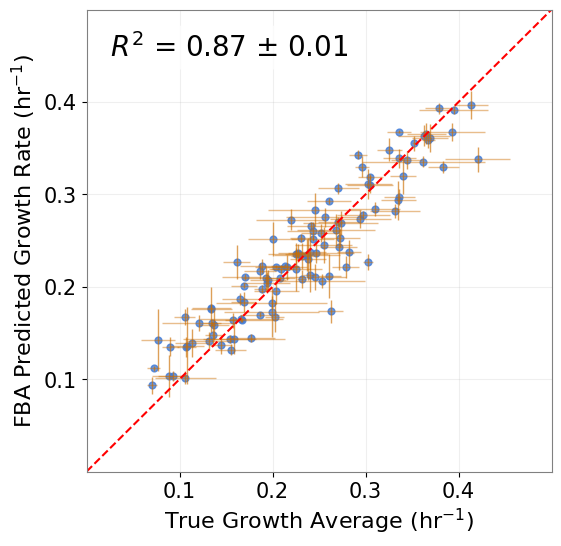

Saved Figure S9-style comparison to: C:\Users\truok\projects\metabolic-NN\insights\thesis\iML1515_oof_fba_from_predicted_vin.png


In [45]:
# Match the established experimental-growth OOF plot, with FBA as the predictor.
plt.figure(figsize=(6, 6))
plt.hlines(
    y=fba_growth_oof,
    xmin=oof_true_cv - oof_std_cv,
    xmax=oof_true_cv + oof_std_cv,
    colors="#CC6E00", alpha=0.45, linewidth=1.0,
)
plt.vlines(
    x=oof_true_cv,
    ymin=fba_growth_oof - fba_growth_seed_std,
    ymax=fba_growth_oof + fba_growth_seed_std,
    colors="#CC6E00", alpha=0.65, linewidth=1.0,
)
plt.scatter(oof_true_cv, fba_growth_oof, alpha=0.78, s=24, c="#3F7BD9")
axis_max = max(0.5, float(np.ceil(10 * max(
    np.max(oof_true_cv + oof_std_cv),
    np.max(fba_growth_oof + fba_growth_seed_std),
)) / 10))
plt.plot([0.0, axis_max], [0.0, axis_max], "r--", lw=1.5)
plt.xlabel(r"True Growth Average (hr$^{-1}$)", fontsize=16)
plt.ylabel(r"FBA Predicted Growth Rate (hr$^{-1}$)", fontsize=16)
plt.xlim(0.0, axis_max)
plt.ylim(0.0, axis_max)
plt.text(0.05, 0.95, format_r2_with_std(fba_r2_oof, fba_r2_seed_std),
         transform=plt.gca().transAxes, ha="left", va="top", fontsize=20,
         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.75))
plt.xticks(np.arange(0.1, axis_max, 0.1), fontsize=15)
plt.yticks(np.arange(0.1, axis_max, 0.1), fontsize=15)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.grid(alpha=0.2)
figure_path = Path(out_dir) / "iML1515_oof_fba_from_predicted_vin.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved Figure S9-style comparison to: {figure_path.resolve()}")


### TabPFN on Experimental Data

In [46]:
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion
from importlib.metadata import version
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import r2_score, mean_absolute_error

TABPFN_VERSION = ModelVersion.V3_5
reg = TabPFNRegressor.create_default_for_version(TABPFN_VERSION)
print("TabPFN package:", version("tabpfn"))
print("Selected model:", TABPFN_VERSION.value)
print("Checkpoint:", reg.model_path)

EXP_PATH = "./AMN_data/iML1515_EXP.csv"
GROWTH_TARGET_COL = "GR_AVG"

exp_df_tabpfn = pd.read_csv(EXP_PATH).fillna(0.0)

# Normalize experimental column names to match expected reaction IDs.
# Example: EX_pi_e_i -> EX_pi_e
normalized_cols_tabpfn = {c: c[:-2] if c.endswith("_i") else c for c in exp_df_tabpfn.columns}
exp_df_tabpfn = exp_df_tabpfn.rename(columns=normalized_cols_tabpfn)

if GROWTH_TARGET_COL not in exp_df_tabpfn.columns:
    raise ValueError(f"Missing growth target column: {GROWTH_TARGET_COL}")

CARBON_SOURCE_COLS = [
    "EX_rib__D_e",
    "EX_malt_e",
    "EX_melib_e",
    "EX_tre_e",
    "EX_fru_e",
    "EX_gal_e",
    "EX_ac_e",
    "EX_lac__D_e",
    "EX_succ_e",
    "EX_pyr_e",
]
missing_carbon_cols = [c for c in CARBON_SOURCE_COLS if c not in exp_df_tabpfn.columns]
if missing_carbon_cols:
    raise ValueError(f"Missing required carbon source columns: {missing_carbon_cols}")

# Use only variable carbon sources as TabPFN features.
feature_cols = [c for c in CARBON_SOURCE_COLS if exp_df_tabpfn[c].nunique(dropna=False) > 1]
if len(feature_cols) == 0:
    raise ValueError("No variable carbon-source features found.")

# Safety check: these features are expected to be binary 0/1.
for c in feature_cols:
    vals = set(float(v) for v in pd.Series(exp_df_tabpfn[c]).dropna().unique().tolist())
    if not vals.issubset({0.0, 1.0}):
        raise ValueError(f"Feature {c} is not binary 0/1: {sorted(vals)}")

X_all = exp_df_tabpfn[feature_cols].to_numpy(dtype=np.float32)
y_all = exp_df_tabpfn[GROWTH_TARGET_COL].to_numpy(dtype=np.float32)

exp110_df = pd.read_csv("AMN_data/EXP110.csv")
if "GR_STD" not in exp110_df.columns:
    raise ValueError("EXP110.csv must contain GR_STD column.")
y_std_all = exp110_df["GR_STD"].to_numpy(dtype=np.float32)

stratify_y = exp_df_tabpfn[CARBON_SOURCE_COLS].gt(0).sum(axis=1).to_numpy(dtype=np.int64)
if np.any((stratify_y < 1) | (stratify_y > 4)):
    raise ValueError("Experimental strata must be carbon-source counts in {1,2,3,4}.")

n_samples = X_all.shape[0]
if y_std_all.shape[0] != n_samples:
    raise ValueError("EXP110.csv GR_STD length must match number of samples used in training.")

n_splits = 10
if n_samples < n_splits:
    raise ValueError("Need at least 10 samples for 10-fold stratified CV.")

strata_counts = np.bincount(stratify_y, minlength=5)[1:5]
if np.min(strata_counts) < n_splits:
    raise ValueError("Each carbon-source-count stratum must have at least 10 samples for 10-fold stratified CV.")

skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=10)
print("Stratification counts (1,2,3,4 carbons):", strata_counts.tolist())
print("Using variable carbon-source features:", feature_cols)
print(f"Samples: {n_samples}, features: {X_all.shape[1]}")

fold_summaries_tabpfn = []
oof_true_parts_tabpfn = []
oof_pred_parts_tabpfn = []
oof_std_parts_tabpfn = []

for fold_id, (tr_idx, va_idx) in enumerate(skf.split(np.arange(n_samples), stratify_y), start=1):
    X_train, X_val = X_all[tr_idx], X_all[va_idx]
    y_train, y_val = y_all[tr_idx], y_all[va_idx]

    reg = TabPFNRegressor.create_default_for_version(TABPFN_VERSION, random_state=10)
    reg.fit(X_train, y_train)
    y_pred = reg.predict(X_val).astype(np.float32)

    fold_r2 = r2_score(y_val, y_pred)
    fold_mae = mean_absolute_error(y_val, y_pred)
    fold_mse = float(np.mean((y_val - y_pred) ** 2))

    fold_summaries_tabpfn.append({
        "fold": int(fold_id),
        "r2": float(fold_r2),
        "mae": float(fold_mae),
        "mse": float(fold_mse),
    })

    oof_true_parts_tabpfn.append(y_val)
    oof_pred_parts_tabpfn.append(y_pred)
    oof_std_parts_tabpfn.append(y_std_all[va_idx])

    print(f"Fold {fold_id:>2d}/{n_splits} | R2={fold_r2:.4f} | MAE={fold_mae:.6f} | MSE={fold_mse:.6f}")

oof_true_tabpfn = np.concatenate(oof_true_parts_tabpfn)
oof_pred_tabpfn = np.concatenate(oof_pred_parts_tabpfn)
oof_std_tabpfn = np.concatenate(oof_std_parts_tabpfn)

cv_r2_mean_tabpfn = float(np.mean([f["r2"] for f in fold_summaries_tabpfn]))
cv_r2_std_tabpfn = float(np.std([f["r2"] for f in fold_summaries_tabpfn]))
cv_mae_mean_tabpfn = float(np.mean([f["mae"] for f in fold_summaries_tabpfn]))
cv_mae_std_tabpfn = float(np.std([f["mae"] for f in fold_summaries_tabpfn]))
cv_mse_mean_tabpfn = float(np.mean([f["mse"] for f in fold_summaries_tabpfn]))
cv_mse_std_tabpfn = float(np.std([f["mse"] for f in fold_summaries_tabpfn]))

r2_oof_tabpfn = r2_score(oof_true_tabpfn, oof_pred_tabpfn)
mae_oof_tabpfn = mean_absolute_error(oof_true_tabpfn, oof_pred_tabpfn)
rmse_oof_tabpfn = np.sqrt(np.mean((oof_true_tabpfn - oof_pred_tabpfn) ** 2))
print(f"\nOOF pooled, TabPFN | R2: {r2_oof_tabpfn:.4f} | MAE: {mae_oof_tabpfn:.6f} | RMSE: {rmse_oof_tabpfn:.6f}")
print(f"CV mean+/-std | R2: {cv_r2_mean_tabpfn:.4f} +/- {cv_r2_std_tabpfn:.4f}")
print(f"CV mean+/-std | MAE: {cv_mae_mean_tabpfn:.6f} +/- {cv_mae_std_tabpfn:.6f}")
print(f"CV mean+/-std | MSE: {cv_mse_mean_tabpfn:.6f} +/- {cv_mse_std_tabpfn:.6f}")



TabPFN package: 9.0.0
Selected model: v3.5
Checkpoint: C:\Users\truok\AppData\Roaming\tabpfn\tabpfn-v3.5-20260909.safetensors
Stratification counts (1,2,3,4 carbons): [10, 20, 40, 40]
Using variable carbon-source features: ['EX_rib__D_e', 'EX_malt_e', 'EX_melib_e', 'EX_tre_e', 'EX_fru_e', 'EX_gal_e', 'EX_ac_e', 'EX_lac__D_e', 'EX_succ_e', 'EX_pyr_e']
Samples: 110, features: 10
Fold  1/10 | R2=0.9190 | MAE=0.022143 | MSE=0.000799
Fold  2/10 | R2=0.8894 | MAE=0.031041 | MSE=0.001187
Fold  3/10 | R2=0.8147 | MAE=0.032189 | MSE=0.001278
Fold  4/10 | R2=0.8529 | MAE=0.036705 | MSE=0.001827
Fold  5/10 | R2=0.6243 | MAE=0.022721 | MSE=0.001319
Fold  6/10 | R2=0.8163 | MAE=0.020826 | MSE=0.000790
Fold  7/10 | R2=0.6347 | MAE=0.036440 | MSE=0.001757
Fold  8/10 | R2=0.6405 | MAE=0.035545 | MSE=0.002039
Fold  9/10 | R2=0.6159 | MAE=0.031545 | MSE=0.001206
Fold 10/10 | R2=0.7633 | MAE=0.036605 | MSE=0.001796

OOF pooled, TabPFN | R2: 0.8031 | MAE: 0.030576 | RMSE: 0.037414
CV mean+/-std | R2: 0.75

TabPFN repeated-CV seed metrics:
cv_seed=10 | R2=0.8031 | MAE=0.030576 | RMSE=0.037414
cv_seed=11 | R2=0.8044 | MAE=0.030368 | RMSE=0.037299
cv_seed=12 | R2=0.8035 | MAE=0.030463 | RMSE=0.037379
TabPFN pooled OOF across split seeds | R2: 0.8037 +/- 0.0005
TabPFN pooled OOF across split seeds | MAE: 0.030469 +/- 0.000085
TabPFN pooled OOF across split seeds | RMSE: 0.037364 +/- 0.000048
TabPFN repeated-CV mean-prediction R2: 0.8063
TabPFN repeated-CV mean-prediction MAE: 0.030315
TabPFN repeated-CV mean-prediction RMSE: 0.037117
TabPFN prediction std across split seeds: mean=0.004508 +/- 0.002698


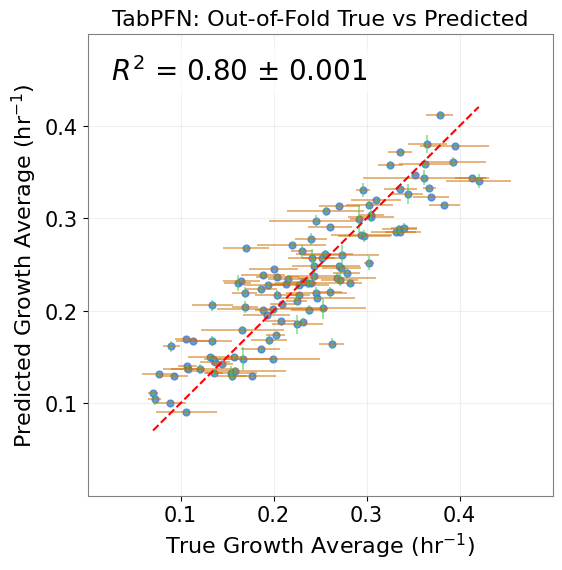

In [47]:
# TabPFN repeated-CV prediction-std diagnostic
tabpfn_cv_split_seeds = [10, 11, 12]

tabpfn_pred_sum = np.zeros(n_samples, dtype=np.float64)
tabpfn_pred_sumsq = np.zeros(n_samples, dtype=np.float64)
tabpfn_pred_count = np.zeros(n_samples, dtype=np.int32)
tabpfn_true_per_sample = np.full(n_samples, np.nan, dtype=np.float64)

tabpfn_seed_metrics = []
for cv_seed in tabpfn_cv_split_seeds:
    skf_rep = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=cv_seed)
    seed_true_parts = []
    seed_pred_parts = []

    for fold_id, (tr_idx, va_idx) in enumerate(skf_rep.split(np.arange(n_samples), stratify_y), start=1):
        X_train, X_val = X_all[tr_idx], X_all[va_idx]
        y_train, y_val = y_all[tr_idx], y_all[va_idx]

        reg_rep = TabPFNRegressor.create_default_for_version(TABPFN_VERSION, random_state=cv_seed)
        reg_rep.fit(X_train, y_train)
        y_pred = reg_rep.predict(X_val).astype(np.float32)

        for idx_i, y_t, y_p in zip(va_idx, y_val, y_pred):
            if np.isnan(tabpfn_true_per_sample[idx_i]):
                tabpfn_true_per_sample[idx_i] = float(y_t)
            elif not np.isclose(tabpfn_true_per_sample[idx_i], float(y_t), atol=1e-7):
                raise ValueError(f"Conflicting true value for sample {idx_i}.")
            tabpfn_pred_sum[idx_i] += float(y_p)
            tabpfn_pred_sumsq[idx_i] += float(y_p) ** 2
            tabpfn_pred_count[idx_i] += 1

        seed_true_parts.append(y_val)
        seed_pred_parts.append(y_pred)

    seed_true = np.concatenate(seed_true_parts)
    seed_pred = np.concatenate(seed_pred_parts)
    tabpfn_seed_metrics.append({
        "cv_seed": int(cv_seed),
        "r2": float(r2_score(seed_true, seed_pred)),
        "mae": float(mean_absolute_error(seed_true, seed_pred)),
        "rmse": float(np.sqrt(np.mean((seed_true - seed_pred) ** 2))),
    })

expected_count = len(tabpfn_cv_split_seeds)
if np.any(tabpfn_pred_count != expected_count):
    bad = np.where(tabpfn_pred_count != expected_count)[0].tolist()
    raise ValueError(f"Each sample should have {expected_count} TabPFN OOF predictions; bad samples: {bad}")

tabpfn_oof_true_cv = tabpfn_true_per_sample.astype(np.float32)
tabpfn_oof_pred_mean = tabpfn_pred_sum / tabpfn_pred_count
tabpfn_oof_pred_cv = tabpfn_oof_pred_mean.astype(np.float32)
tabpfn_oof_pred_seed_var_cv = (
    tabpfn_pred_sumsq - tabpfn_pred_count * tabpfn_oof_pred_mean ** 2
) / np.maximum(1, tabpfn_pred_count - 1)
tabpfn_oof_pred_seed_std_cv = np.sqrt(np.maximum(0.0, tabpfn_oof_pred_seed_var_cv)).astype(np.float32)
tabpfn_oof_std_cv = y_std_all.astype(np.float32)

tabpfn_r2_repeated = r2_score(tabpfn_oof_true_cv, tabpfn_oof_pred_cv)
tabpfn_mae_repeated = mean_absolute_error(tabpfn_oof_true_cv, tabpfn_oof_pred_cv)
tabpfn_rmse_repeated = np.sqrt(np.mean((tabpfn_oof_true_cv - tabpfn_oof_pred_cv) ** 2))
tabpfn_seed_r2_vals = np.array([m["r2"] for m in tabpfn_seed_metrics], dtype=np.float32)
tabpfn_seed_mae_vals = np.array([m["mae"] for m in tabpfn_seed_metrics], dtype=np.float32)
tabpfn_seed_rmse_vals = np.array([m["rmse"] for m in tabpfn_seed_metrics], dtype=np.float32)
tabpfn_seed_r2_mean = float(tabpfn_seed_r2_vals.mean())
tabpfn_seed_r2_std = float(tabpfn_seed_r2_vals.std(ddof=0))
tabpfn_seed_mae_mean = float(tabpfn_seed_mae_vals.mean())
tabpfn_seed_mae_std = float(tabpfn_seed_mae_vals.std(ddof=0))
tabpfn_seed_rmse_mean = float(tabpfn_seed_rmse_vals.mean())
tabpfn_seed_rmse_std = float(tabpfn_seed_rmse_vals.std(ddof=0))
tabpfn_pred_seed_std_mean = float(np.mean(tabpfn_oof_pred_seed_std_cv))
tabpfn_pred_seed_std_std = float(np.std(tabpfn_oof_pred_seed_std_cv))

print("TabPFN repeated-CV seed metrics:")
for m in tabpfn_seed_metrics:
    print(f"cv_seed={m['cv_seed']} | R2={m['r2']:.4f} | MAE={m['mae']:.6f} | RMSE={m['rmse']:.6f}")
print(f"TabPFN pooled OOF across split seeds | R2: {tabpfn_seed_r2_mean:.4f} +/- {tabpfn_seed_r2_std:.4f}")
print(f"TabPFN pooled OOF across split seeds | MAE: {tabpfn_seed_mae_mean:.6f} +/- {tabpfn_seed_mae_std:.6f}")
print(f"TabPFN pooled OOF across split seeds | RMSE: {tabpfn_seed_rmse_mean:.6f} +/- {tabpfn_seed_rmse_std:.6f}")
print(f"TabPFN repeated-CV mean-prediction R2: {tabpfn_r2_repeated:.4f}")
print(f"TabPFN repeated-CV mean-prediction MAE: {tabpfn_mae_repeated:.6f}")
print(f"TabPFN repeated-CV mean-prediction RMSE: {tabpfn_rmse_repeated:.6f}")
print(f"TabPFN prediction std across split seeds: mean={tabpfn_pred_seed_std_mean:.6f} +/- {tabpfn_pred_seed_std_std:.6f}")

from pathlib import Path
out_dir = Path("./insights/thesis")
out_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(6, 6))
line_min_tabpfn = float(max(0.0, min(tabpfn_oof_true_cv.min(), tabpfn_oof_pred_cv.min())))
line_max_tabpfn = float(min(0.5, max(tabpfn_oof_true_cv.max(), tabpfn_oof_pred_cv.max())))

plt.hlines(
    y=tabpfn_oof_pred_cv,
    xmin=tabpfn_oof_true_cv - tabpfn_oof_std_cv,
    xmax=tabpfn_oof_true_cv + tabpfn_oof_std_cv,
    colors="#CC6E00",
    alpha=0.6,
    linewidth=1.2,
)
plt.vlines(
    x=tabpfn_oof_true_cv,
    ymin=tabpfn_oof_pred_cv - tabpfn_oof_pred_seed_std_cv,
    ymax=tabpfn_oof_pred_cv + tabpfn_oof_pred_seed_std_cv,
    colors="#3ECC40",
    alpha=0.6,
    linewidth=1.2,
)
plt.scatter(tabpfn_oof_true_cv, tabpfn_oof_pred_cv, alpha=0.78, s=24, c="#3F7BD9")
plt.plot([line_min_tabpfn, line_max_tabpfn], [line_min_tabpfn, line_max_tabpfn], "r--", lw=1.5)
plt.xlabel(r"True Growth Average (hr$^{-1}$)", fontsize=16)
plt.ylabel(r"Predicted Growth Average (hr$^{-1}$)", fontsize=16)
plt.title("TabPFN: Out-of-Fold True vs Predicted", fontsize=16)
plt.xlim(0.0, 0.5)
plt.ylim(0.0, 0.5)
plt.text(0.05, 0.95, format_r2_with_std(tabpfn_seed_r2_mean, tabpfn_seed_r2_std), transform=plt.gca().transAxes,
         ha="left", va="top", fontsize=20,
         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.75))
plt.xticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
plt.yticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.grid(alpha=0.2)
plt.savefig(out_dir / "iML1515_tabpfn_oof_true_vs_predicted_with_exp_and_seed_std_bars.png", dpi=300, bbox_inches="tight")
plt.show()


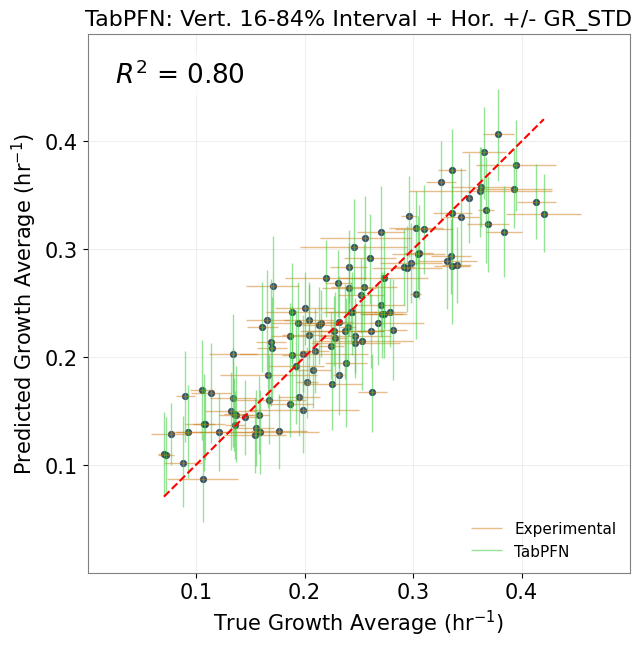

In [48]:
# TabPFN uncertainty diagnostics (OOF): prediction intervals per OOF point only
# Requires cell 30 to be run first (defines feature_cols, stratify_y, n_splits, X_all, y_all, y_std_all).

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import r2_score, mean_absolute_error
from tabpfn import TabPFNRegressor

q_list = [0.16, 0.50, 0.84]

def _to_quantile_dict(pred_q, quantiles):
    if isinstance(pred_q, dict):
        if "quantiles" in pred_q:
            q_vals = pred_q["quantiles"]
            return {float(q): np.asarray(arr).reshape(-1) for q, arr in zip(quantiles, q_vals)}
        if "predictions" in pred_q:
            q_vals = pred_q["predictions"]
            return {float(q): np.asarray(arr).reshape(-1) for q, arr in zip(quantiles, q_vals)}
        out = {}
        for k, v in pred_q.items():
            try:
                qk = float(k)
                out[qk] = np.asarray(v).reshape(-1)
            except Exception:
                pass
        if len(out) > 0:
            return out
        raise ValueError("Unsupported quantile dict format returned by TabPFNRegressor.predict().")

    if isinstance(pred_q, (list, tuple)):
        return {float(q): np.asarray(arr).reshape(-1) for q, arr in zip(quantiles, pred_q)}

    arr = np.asarray(pred_q)
    if arr.ndim == 2 and arr.shape[1] == len(quantiles):
        return {float(q): arr[:, i].reshape(-1) for i, q in enumerate(quantiles)}

    raise ValueError("Unsupported quantile output format from TabPFNRegressor.predict().")


# Build OOF quantiles fold-by-fold
skf_uq = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=10)

oof_true_uq_parts = []
oof_std_uq_parts = []
oof_q_parts = {q: [] for q in q_list}

for fold_id, (tr_idx, va_idx) in enumerate(skf_uq.split(np.arange(X_all.shape[0]), stratify_y), start=1):
    X_train, X_val = X_all[tr_idx], X_all[va_idx]
    y_train, y_val = y_all[tr_idx], y_all[va_idx]

    reg_uq = TabPFNRegressor.create_default_for_version(TABPFN_VERSION, random_state=10)
    reg_uq.fit(X_train, y_train)

    try:
        q_pred_raw = reg_uq.predict(X_val, output_type="quantiles", quantiles=q_list)
    except TypeError:
        q_pred_raw = reg_uq.predict(X_val, quantiles=q_list)

    q_pred = _to_quantile_dict(q_pred_raw, q_list)

    oof_true_uq_parts.append(y_val)
    oof_std_uq_parts.append(y_std_all[va_idx])
    for q in q_list:
        if q not in q_pred:
            raise ValueError(f"Quantile {q} missing in TabPFN output for fold {fold_id}.")
        oof_q_parts[q].append(np.asarray(q_pred[q], dtype=np.float32).reshape(-1))

oof_true_uq = np.concatenate(oof_true_uq_parts)
oof_std_uq = np.concatenate(oof_std_uq_parts)
oof_q = {q: np.concatenate(parts) for q, parts in oof_q_parts.items()}

pred_q16 = oof_q[0.16]
pred_q84 = oof_q[0.84]
r2_uq = r2_score(oof_true_tabpfn, oof_pred_tabpfn)
mae_uq = mean_absolute_error(oof_true_tabpfn, oof_pred_tabpfn)

# Prediction intervals per OOF point: vertical model interval + horizontal +/- GR_STD
plt.figure(figsize=(7, 7))

# Horizontal bars = experimental uncertainty (+/- GR_STD)
plt.hlines(
    y=oof_pred_tabpfn,
    xmin=oof_true_uq - oof_std_uq,
    xmax=oof_true_uq + oof_std_uq,
    colors="#CC6E00",
    alpha=0.45,
    linewidth=1.0,
    label="Experimental",
)

# Vertical bars = model predictive interval (q16-q84)
plt.vlines(
    x=oof_true_uq,
    ymin=pred_q16,
    ymax=pred_q84,
    colors="#3ECC40",
    alpha=0.55,
    linewidth=1.0,
    label="TabPFN",
)

# Point predictions from cell 30
plt.scatter(
    oof_true_uq,
    oof_pred_tabpfn,
    s=18,
    alpha=0.8,
    color="#1D3557",
    label="_nolegend_",
)

line_min_v = float(max(0.0, min(oof_true_uq.min(), oof_pred_tabpfn.min())))
line_max_v = float(min(0.5, max(oof_true_uq.max(), oof_pred_tabpfn.max())))
plt.plot([line_min_v, line_max_v], [line_min_v, line_max_v], "r--", lw=1.5, label="_nolegend_")
plt.xlabel(r"True Growth Average (hr$^{-1}$)", fontsize=15)
plt.ylabel(r"Predicted Growth Average (hr$^{-1}$)", fontsize=15)
plt.title("TabPFN: Vert. 16-84% Interval + Hor. +/- GR_STD", fontsize=16)
plt.xlim(0.0, 0.5)
plt.ylim(0.0, 0.5)
plt.text(0.05, 0.95, f"$R^2$ = {r2_uq:.2f}", transform=plt.gca().transAxes,
         ha="left", va="top", fontsize=19,
         bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.75))
plt.xticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
plt.yticks(np.arange(0.1, 0.5, 0.1), fontsize=15)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.legend(frameon=False, fontsize=11, loc="lower right")
plt.grid(alpha=0.2)
plt.show()


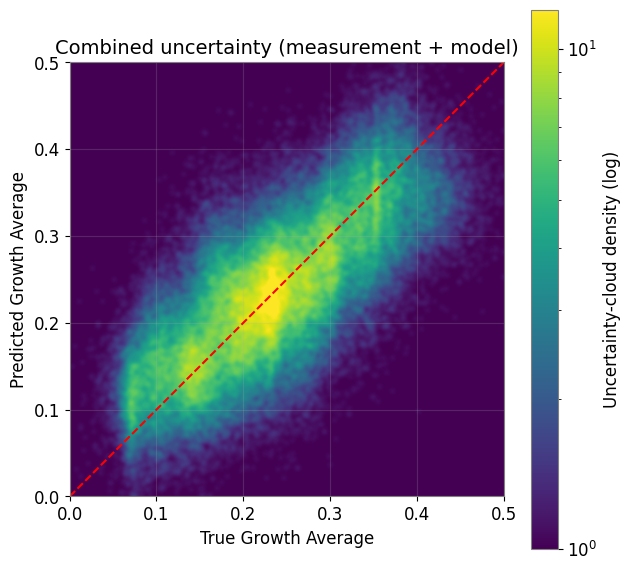

In [49]:
rng = np.random.default_rng(10)
n_draw = 1000
sigma_model = 0.5 * (pred_q84 - pred_q16)

x_cloud = (oof_true_uq[:,None] + rng.normal(0, oof_std_uq[:,None], (len(oof_true_uq), n_draw))).ravel()
y_cloud = (oof_pred_tabpfn[:,None] + rng.normal(0, sigma_model[:,None], (len(oof_true_uq), n_draw))).ravel()

from scipy.ndimage import gaussian_filter
from matplotlib.colors import LogNorm

H, xedges, yedges = np.histogram2d(x_cloud, y_cloud, bins=300, range=[[0,0.5],[0,0.5]])
H = gaussian_filter(H, sigma=1.6)
vmax = np.percentile(H, 99.7) + 1

plt.figure(figsize=(7,7))
im = plt.imshow((H.T + 1), origin="lower", extent=[0,0.5,0,0.5], cmap="viridis",
                norm=LogNorm(vmin=1, vmax=vmax), interpolation="lanczos", aspect="equal")
cbar = plt.colorbar(im)
cbar.set_label("Uncertainty-cloud density (log)", fontsize=12)
cbar.ax.tick_params(labelsize=12)
cbar.outline.set_edgecolor("gray")
plt.plot([0,0.5],[0,0.5],"r--",lw=1.5)
plt.xlim(0,0.5); plt.ylim(0,0.5)
plt.xlabel("True Growth Average", fontsize=12)
plt.ylabel("Predicted Growth Average", fontsize=12)
plt.title("Combined uncertainty (measurement + model)", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_color("gray")
plt.grid(alpha=0.2)
plt.show()
